# Sen-2 LULC India — RS3Mamba benchmark (same protocol as the U-Net baseline)

**Purpose.** Train **RS3Mamba** (Ma, Zhang & Pun, *IEEE GRSL* 2024) — a dual-branch **ResNet-18 + Vision-Mamba (VSS / VMamba-Tiny)** segmentation network — on the official **Sen-2 LULC** dataset under *exactly* the protocol used for the U-Net/ResNet34 baseline, so the two results are directly comparable.

**Why RS3Mamba.** It is the established Mamba model for *remote-sensing semantic segmentation* (official code + ImageNet-pretrained VMamba weights available), so it can be initialised from pre-trained weights just like the ImageNet-pretrained U-Net encoder, and it keeps a CNN branch for local texture while the Mamba branch adds long-range context.

## What is IDENTICAL to the U-Net notebook (benchmark controls)
Dataset, official splits, pairing/cleaning rules, label mapping (0 = unclassified → ignored; 1–7 → 0–6), train-only normalisation, augmentation (`moderate`), loss (`ce_dice`), optimizer (AdamW, lr 1e-4, wd 1e-4), cosine schedule to 1e-6 over 150 epochs, early-stopping patience 30 on val mIoU, per-GPU batch 32 × 2 GPUs, AMP fp16, grad-clip 1.0, seed 42, DDP training with rank verification, all metric code (confusion-matrix based OA / mIoU / F1 / κ / FW-IoU / per-class / per-image), run-once TEST evaluation, curves, qualitative cases, runtime / params / FLOPs / memory / throughput logging.

## What is necessarily DIFFERENT (documented, not hidden)
| item | U-Net baseline | this notebook |
|---|---|---|
| network | smp U-Net, ResNet34 (24.4 M) | RS3Mamba: ResNet-18 branch + VSS-Tiny branch + window-attention fusion + GLTB decoder (43.3 M) |
| pre-training | torchvision ImageNet ResNet34 | timm ResNet-18 (IG-1B semi-weakly-sup. → ImageNet-1k) **and** ImageNet-1k VMamba-Tiny (official RS3Mamba checkpoint, SHA-256 pinned); fusion/decoder/stem random |
| selective scan | – | fused CUDA kernel from `mamba-ssm` (built for your GPU in §3a); exact pure-PyTorch fallback exists but is not chosen silently |
| GFLOPs | `FlopCounterMode` | `FlopCounterMode` **+ analytic selective-scan term** (the custom CUDA op is invisible to the counter) |
| window-attention padding | – | official code **crashes on 64-px tiles** (2-tuple reflect pad on 4-D tensors for maps not a multiple of 8); the port uses 4-tuples and `min(8, map size)` windows. Bit-identical to official wherever the official code runs (verified: max |Δlogit| = 2e-8 at 256 px). |

**Hyper-parameters are deliberately NOT re-tuned for Mamba** (the official recipe is SGD 1e-2 on 256-px aerial crops). That is the controlled comparison you asked for; if RS3Mamba under-performs, a learning-rate sensitivity run is the first follow-up, not a change to this protocol.

**Honest expectation.** Tiles are 64×64 px at 10 m, so the VSS branch sees only 16×16 = 256 tokens at its finest stage (2×2 at the coarsest). The long-range-context advantage of Mamba is therefore limited on this data; a result at or below the U-Net is a legitimate finding.

**Settings → Accelerator = GPU T4 x2, Internet = ON.** Run top to bottom. Optional cells marked *OPTIONAL* let you pin Part 1 and the baseline to the U-Net notebook's outputs (attach them via *Add Data → Notebook Output*).


**Practical performance edition (updated October 2026):** Cell 39 now uses reproducible, rotating per-epoch training subsets and prints within-epoch progress. Cell 52 launches an 80-epoch *ceiling* with 16,384 training images per epoch and fixed 8,192-image selection-validation subset. Final validation/test still evaluate their entire official splits. This practical training protocol must not be reported as 80 full-dataset epochs. The architecture and weights are unchanged. See Sections 16–17 for validation and troubleshooting.


## 1. Kaggle environment verification

In [1]:
import os, sys, json, time, shutil, platform, subprocess, random, datetime, re, hashlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

ROOT = "/kaggle/working/lulc_research"
for d in ["official_dataset","dataset_analysis","splits","preprocessing","experiments","model_comparisons",
          "real_world_inference","flood_exposure_ready","reproducibility","paper_tables","code"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
os.environ["LULC_ROOT"] = ROOT
SEED = 42
random.seed(SEED); np.random.seed(SEED)
RUN_STARTED = datetime.datetime.now().isoformat(timespec="seconds")

print("Python", platform.python_version(), "|", platform.platform())
print(subprocess.run(["nvidia-smi","--query-gpu=index,name,memory.total,driver_version","--format=csv"],capture_output=True,text=True).stdout)
import torch
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| visible GPUs:", torch.cuda.device_count())
print("NOTE: two visible GPUs are NOT proof of dual-GPU training - Part 2 verifies per-rank work explicitly.")
print("CPU cores:", os.cpu_count())
du = shutil.disk_usage("/kaggle/working"); print(f"/kaggle/working free: {du.free/2**30:.1f} GiB of {du.total/2**30:.1f} GiB")

import requests
try:
    r = requests.get("https://data.mendeley.com", timeout=15); INTERNET_OK = r.status_code < 500
    print("Internet/Mendeley reachable:", INTERNET_OK, "(HTTP", r.status_code, ")")
except Exception as e:
    INTERNET_OK = False; print("Mendeley NOT reachable ->", repr(e), "\nEnable Settings > Internet, or use the manual-attachment fallback below.")

Python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04

torch 2.11.0+cu128 | CUDA 12.8 | visible GPUs: 2
NOTE: two visible GPUs are NOT proof of dual-GPU training - Part 2 verifies per-rank work explicitly.
CPU cores: 4
/kaggle/working free: 19.5 GiB of 19.5 GiB
Internet/Mendeley reachable: True (HTTP 200 )


## 2. Dependency installation
Only *adds* packages; PyTorch/CUDA are never replaced.

In [2]:
!pip install -q segmentation-models-pytorch timm rasterio 2>&1 | tail -2
import segmentation_models_pytorch as smp, timm, rasterio, transformers, cv2
print("smp", smp.__version__, "| timm", timm.__version__, "| rasterio", rasterio.__version__, "| transformers", transformers.__version__, "| cv2", cv2.__version__)
!pip install -q einops ninja packaging wheel 2>&1 | tail -1
import einops; print('einops', einops.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 1.7 MB/s eta 0:00:00
smp 0.6.0 | timm 1.0.29 | rasterio 1.5.1 | transformers 5.16.1 | cv2 4.14.0
einops 0.8.2


## 3. Shared I/O module (`io_utils.py`)
One reader/label-mapping implementation used by dataset scanning **and** training, so Part 1 statistics and Part 2 training can never disagree.

In [3]:
%%writefile /kaggle/working/lulc_research/code/io_utils.py
"""io_utils.py -- image/mask readers and label mapping shared by Part 1 (scan) and Part 2 (training).
Source labels (official): 0=Unclassified, 1..7 = 7 LULC classes.  Model labels: 0..6, 255 = ignore.
"""
import os
import numpy as np
from PIL import Image

NUM_CLASSES = 7
IGNORE_INDEX = 255
CLASS_NAMES_SRC = {1: "Water Bodies", 2: "Dense Forest", 3: "Built up", 4: "Agriculture land",
                   5: "Barren land", 6: "Fallow land", 7: "Sparse Forest"}
MODEL_CLASS_NAMES = [CLASS_NAMES_SRC[i] for i in range(1, 8)]

# source id -> model id.  source 0 (Unclassified) and anything unexpected -> IGNORE_INDEX
LUT_SRC2MODEL = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for _s in range(1, 8):
    LUT_SRC2MODEL[_s] = _s - 1
SRC_FROM_MODEL = np.arange(1, 8, dtype=np.uint8)   # model id k -> source id k+1


def read_image(path):
    """Return HxWx3 array (native dtype), channel order R,G,B. Original mode is NOT hidden from Part 1
    inspection (which opens the file separately)."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            arr = ds.read([1, 2, 3]).transpose(1, 2, 0)
        return arr
    im = Image.open(path)
    if im.mode != "RGB":
        im = im.convert("RGB")
    return np.asarray(im)


def read_mask_raw(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            a = ds.read()
        return a[0] if a.shape[0] == 1 else a.transpose(1, 2, 0)
    return np.asarray(Image.open(path))   # 'P' images yield palette INDICES (what we want)


def decode_mask(arr, enc):
    """Raw mask array -> uint8 array of SOURCE class ids (0..7). Unmapped colours -> 255.
    enc: {"type": "indexed"} or {"type": "rgb", "color_map": {"<packed_rgb_int>": source_id}}"""
    if arr.ndim == 3:
        if enc.get("type") == "rgb":
            a = arr.astype(np.uint32)
            packed = (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]
            out = np.full(packed.shape, 255, np.uint8)
            for k, v in enc["color_map"].items():
                out[packed == int(k)] = v
            return out
        arr = arr[..., 0]
    return np.clip(arr, 0, 255).astype(np.uint8)


def src_to_model(src):
    return LUT_SRC2MODEL[src]

Writing /kaggle/working/lulc_research/code/io_utils.py


## 3a. Mamba selective-scan kernel (`mamba_scan.py` + build/verify)

RS3Mamba's VSS blocks need the **selective-scan (S6)** operator. `mamba_scan.py` provides two *numerically equivalent* implementations: the fused CUDA kernel of `mamba-ssm` (fast; what the official model uses) and an exact pure-PyTorch scan (slow; for CPU tests / explicit opt-in only).

The kernel is imported **without** executing `mamba_ssm/__init__.py` (recent releases import Mamba-3 / tilelang / quack-kernels there, which are irrelevant here), and compiled **only for the detected GPU architecture** (`--no-build-isolation --no-deps`). The cell below (1) probes for a working kernel, (2) tries a cached wheel, (3) otherwise compiles once (≈10–25 min) and caches the wheel in `/kaggle/working/wheels`. Every path ends with a **forward + gradient self-test against the exact reference**, run in a subprocess.


In [4]:
%%writefile /kaggle/working/lulc_research/code/mamba_scan.py
"""mamba_scan.py -- selective-scan (S6) back-ends for the Mamba models of the Sen-2 LULC benchmark.

Two interchangeable implementations of the SAME function  y = SSM(u, delta, A, B, C, D):
  * "cuda"  : the fused kernel of the `mamba-ssm` package (what VMamba / RS3Mamba use).  Fast.
              It is imported WITHOUT executing mamba_ssm/__init__.py, because recent releases import Mamba-3
              (tilelang, quack-kernels, ...) there, which is irrelevant here and often not installable.
  * "torch" : exact pure-PyTorch reference (sequential scan, fp32).  Numerically equivalent, but ~10-50x slower
              on GPU; intended for CPU unit tests and as an explicit, user-chosen fallback.  Never selected silently.

Also holds the analytic FLOP bookkeeping: torch's FlopCounterMode cannot see a custom CUDA op, so while
`flop_mode(True)` is active the scan is skipped and 9*B*L*D*N + B*L*D FLOPs are accumulated instead
(VMamba convention; D here = K*d_inner because the 4 scan directions are fused into the channel axis).
"""
import importlib.util, importlib.metadata, sys, types
import torch
import torch.nn.functional as F

STATE = dict(fn=None, name=None, detail=None, flop_mode=False, scan_flops=0)


_CUDA_CACHE = {}


def load_cuda_scan():
    """-> (selective_scan_fn, version).  Raises ImportError with an actionable message.  Idempotent (cached per process)."""
    if "v" in _CUDA_CACHE:
        return _CUDA_CACHE["v"]
    if "mamba_ssm" not in sys.modules:
        spec = importlib.util.find_spec("mamba_ssm")          # does not execute the package
        if spec is None or not spec.submodule_search_locations:
            raise ImportError("package 'mamba_ssm' is not installed (run the 'Mamba CUDA kernel' cell of the notebook)")
        pkg = types.ModuleType("mamba_ssm")                   # lightweight stand-in: skips mamba_ssm/__init__.py
        pkg.__path__ = list(spec.submodule_search_locations)
        pkg.__file__, pkg.__spec__ = spec.origin, spec
        sys.modules["mamba_ssm"] = pkg
    from mamba_ssm.ops.selective_scan_interface import selective_scan_fn   # needs the compiled `selective_scan_cuda`
    import selective_scan_cuda  # noqa: F401  (explicit check that the extension itself loads)
    try:
        ver = importlib.metadata.version("mamba_ssm")
    except Exception:
        ver = "unknown"
    _CUDA_CACHE["v"] = (selective_scan_fn, ver)
    return _CUDA_CACHE["v"]


def selective_scan_torch(u, delta, A, B, C, D=None, z=None, delta_bias=None, delta_softplus=False,
                         return_last_state=False):
    """Pure-PyTorch S6 scan, same call signature / grouping convention as mamba_ssm.selective_scan_fn.
      u, delta: (Bsz, Dm, L)   A: (Dm, N)   B, C: (Bsz, G, N, L) with Dm % G == 0 (channel d belongs to group d // (Dm/G))
      D, delta_bias: (Dm,)     returns (Bsz, Dm, L) in fp32.   Always computed in fp32 (autocast disabled)."""
    assert z is None and not return_last_state, "only the variant used by SS2D is implemented"
    with torch.autocast(device_type=u.device.type, enabled=False):
        u, delta, A, B, C = u.float(), delta.float(), A.float(), B.float(), C.float()
        if delta_bias is not None:
            delta = delta + delta_bias.float()[None, :, None]
        if delta_softplus:
            delta = F.softplus(delta)
        Bsz, Dm, L = u.shape
        N, G = A.shape[1], B.shape[1]
        r = Dm // G
        u4, dt = u.reshape(Bsz, G, r, L), delta.reshape(Bsz, G, r, L)
        dA = torch.exp(dt.unsqueeze(-1) * A.reshape(1, G, r, 1, N))                       # (B,G,r,L,N)
        dBu = (dt * u4).unsqueeze(-1) * B.permute(0, 1, 3, 2).unsqueeze(2)                # (B,G,r,L,N)
        h = u.new_zeros(Bsz, G, r, N)
        hs = []
        for t in range(L):
            h = dA[:, :, :, t] * h + dBu[:, :, :, t]
            hs.append(h)
        y = torch.einsum("bgrln,bgnl->bgrl", torch.stack(hs, dim=3), C).reshape(Bsz, Dm, L)
        if D is not None:
            y = y + u * D.float()[None, :, None]
    return y


def set_backend(name="cuda"):
    """Select the scan implementation for this process.  'cuda' raises if the kernel is unavailable (no silent fallback);
    'auto' = cuda if importable else torch (the choice is recorded in the returned dict)."""
    if name not in ("cuda", "torch", "auto"):
        raise ValueError(f"scan_backend must be 'cuda' | 'torch' | 'auto', got {name!r}")
    if name in ("cuda", "auto"):
        try:
            fn, ver = load_cuda_scan()
            STATE.update(fn=fn, name="cuda", detail=f"mamba_ssm {ver} selective_scan_cuda")
        except Exception as e:
            if name == "cuda":
                raise RuntimeError(
                    "scan_backend='cuda' but the mamba-ssm CUDA kernel cannot be imported: "
                    f"{e!r}\n -> run the 'Mamba selective-scan CUDA kernel' cell (section 3a), "
                    "or set CFG['rs3mamba']['scan_backend']='torch' to accept the much slower pure-PyTorch scan.") from e
            STATE.update(fn=selective_scan_torch, name="torch", detail=f"pure PyTorch scan (cuda unavailable: {e!r})")
    else:
        STATE.update(fn=selective_scan_torch, name="torch", detail="pure PyTorch reference scan")
    return dict(backend=STATE["name"], detail=STATE["detail"])


def selective_scan(u, delta, A, Bs, Cs, Ds, delta_bias):
    """The call made by SS2D.  u, delta (Bsz,K*D,L); A (K*D,N); Bs, Cs (Bsz,K,N,L); Ds, delta_bias (K*D,)."""
    if STATE["flop_mode"]:
        Bsz, KD, L = u.shape
        STATE["scan_flops"] += 9 * Bsz * L * KD * A.shape[1] + Bsz * KD * L
        return u
    if STATE["fn"] is None:
        set_backend("cuda")
    return STATE["fn"](u, delta, A, Bs, Cs, Ds, z=None, delta_bias=delta_bias, delta_softplus=True,
                       return_last_state=False)


def flop_mode(on):
    """flop_mode(True) starts analytic counting (scan skipped); flop_mode(False) stops it and returns the FLOPs counted."""
    if on:
        STATE["flop_mode"], STATE["scan_flops"] = True, 0
        return 0
    f = STATE["scan_flops"]
    STATE["flop_mode"], STATE["scan_flops"] = False, 0
    return f


def selftest(device="cuda", B=2, K=4, D=24, N=16, L=64, seed=0, tol=2e-3):
    """Numerical check of the ACTIVE backend (STATE['fn']) against the exact torch reference: forward + all 7 gradients.
    Relative error = max|a-b| / max|b|.  Used by the install probe and by `smoke_test.py --stage scan`."""
    if STATE["fn"] is None:
        set_backend("cuda")
    g = torch.Generator().manual_seed(seed)
    mk = lambda *s: torch.randn(*s, generator=g)
    base = [mk(B, K * D, L), mk(B, K * D, L), -torch.exp(mk(K * D, N)), mk(B, K, N, L), mk(B, K, N, L), mk(K * D), mk(K * D)]
    w = mk(B, K * D, L)

    def run(fn):
        ins = [t.clone().to(device).requires_grad_() for t in base]
        u, dl, A, Bs, Cs, Ds, db = ins
        y = fn(u, dl, A, Bs, Cs, Ds, z=None, delta_bias=db, delta_softplus=True)
        (y * w.to(device)).sum().backward()
        return y.detach().float(), [t.grad.detach().float() for t in ins]
    ya, ga = run(STATE["fn"])
    yb, gb = run(selective_scan_torch)
    rel = lambda a, b: float((a - b).abs().max() / (b.abs().max() + 1e-6))
    names = ["u", "delta", "A", "B", "C", "D", "delta_bias"]
    out = dict(backend=STATE["name"], fwd_rel_err=rel(ya, yb), grad_rel_err={n: rel(a, b) for n, a, b in zip(names, ga, gb)})
    out["ok"] = bool(out["fwd_rel_err"] < tol and all(v < tol for v in out["grad_rel_err"].values()))
    return out


Writing /kaggle/working/lulc_research/code/mamba_scan.py


In [5]:
import glob, re, json, subprocess, shutil, tarfile, urllib.request, time, os, sys

MAMBA_SSM_VERSION = "2.3.2.post1"     # build recipe inspected: supports sm_75 (T4); must be built with --no-build-isolation
WHEEL_CACHE = "/kaggle/working/wheels"
CODE = f"{ROOT}/code"
os.makedirs(WHEEL_CACHE, exist_ok=True)

PROBE = '''
import sys, json
sys.path.insert(0, "__CODE__")
try:
    import torch, mamba_scan as MS
    info = MS.set_backend("cuda")
    r = MS.selftest("cuda")
    print(json.dumps(dict(ok=r["ok"], detail=info["detail"], fwd_rel_err=r["fwd_rel_err"], max_grad_rel_err=max(r["grad_rel_err"].values()))))
except Exception as e:
    print(json.dumps(dict(ok=False, error=repr(e)[:600])))
'''
def probe():
    """Runs in a subprocess so this kernel never creates a CUDA context."""
    r = subprocess.run([sys.executable, "-c", PROBE.replace("__CODE__", CODE)], capture_output=True, text=True)
    js = [l for l in r.stdout.strip().splitlines() if l.startswith("{")]
    return json.loads(js[-1]) if js else dict(ok=False, error=(r.stderr or r.stdout)[-600:])

def sh(cmd, log, **kw):
    with open(log, "w") as f:
        return subprocess.run(cmd, stdout=f, stderr=subprocess.STDOUT, **kw).returncode

status = probe(); print("probe #1 (already installed?):", status)

# (1) a wheel built earlier (this session's /kaggle/working/wheels, or a Kaggle dataset you attached) ---------------
if not status["ok"]:
    for w in sorted(glob.glob(f"{WHEEL_CACHE}/mamba_ssm-*.whl") + glob.glob("/kaggle/input/**/mamba_ssm-*.whl", recursive=True)):
        print("trying cached wheel:", w)
        if sh([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall", w], "/tmp/pip_mamba_wheel.log") == 0:
            status = probe(); print("  probe:", status)
            if status["ok"]: break

# (2) compile once for the GPU that is actually present (~10-25 min on 4 vCPUs) ---------------------------------------
if not status["ok"]:
    cc = (subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"], capture_output=True, text=True).stdout.split() or ["?"])[0]
    NVCC = shutil.which("nvcc") or next(iter(sorted(glob.glob("/usr/local/cuda*/bin/nvcc"))), None)
    print(f"GPU compute capability: {cc} | nvcc: {NVCC}")
    if cc == "?" or float(cc) < 7.5:
        print("!! mamba-ssm", MAMBA_SSM_VERSION, "ships kernels for sm_75 and newer only; cannot build for this GPU.")
    elif NVCC is None:
        print("!! nvcc not found -> cannot compile. Use scan_backend='torch' (slow) or attach a prebuilt mamba_ssm wheel as a Kaggle dataset.")
    else:
        t0 = time.time(); cc_d = cc.replace(".", "")
        env = dict(os.environ, MAX_JOBS="4", MAMBA_FORCE_BUILD="TRUE", CUDA_HOME=os.path.dirname(os.path.dirname(NVCC)),
                   TORCH_CUDA_ARCH_LIST=cc, PATH=os.path.dirname(NVCC) + ":" + os.environ["PATH"])
        sh([sys.executable, "-m", "pip", "install", "-q", "ninja", "packaging", "wheel"], "/tmp/pip_build_deps.log")
        meta = json.load(urllib.request.urlopen("https://pypi.org/pypi/mamba-ssm/json", timeout=60))
        url = [f["url"] for f in meta["releases"][MAMBA_SSM_VERSION] if f["filename"].endswith(".tar.gz")][0]
        BUILD = "/kaggle/working/build_mamba"; shutil.rmtree(BUILD, ignore_errors=True); os.makedirs(BUILD)
        urllib.request.urlretrieve(url, f"{BUILD}/src.tgz"); tarfile.open(f"{BUILD}/src.tgz").extractall(BUILD)
        src = next(d for d in glob.glob(f"{BUILD}/mamba_ssm-*") if os.path.isdir(d))
        # compile ONLY for this GPU (stock setup.py compiles six architectures -> >1 h)
        s = open(f"{src}/setup.py").read()
        pat = re.compile(r'(        cc_flag\.append\("-gencode"\)\n        cc_flag\.append\("arch=compute_75,code=sm_75"\)\n)(.*?)(\n\n\n    # HACK)', re.S)
        m = pat.search(s)
        if m:
            s = s[:m.start()] + f'        cc_flag.append("-gencode")\n        cc_flag.append("arch=compute_{cc_d},code=sm_{cc_d}")' + m.group(3) + s[m.end():]
            open(f"{src}/setup.py", "w").write(s); print(f"setup.py patched -> single target sm_{cc_d}")
        else:
            print("setup.py layout differs from the inspected version -> building for ALL architectures (slow)")
        print("compiling selective_scan_cuda ... (log: /kaggle/working/mamba_build.log)")
        rc = sh([sys.executable, "-m", "pip", "wheel", ".", "--no-build-isolation", "--no-deps", "-w", WHEEL_CACHE],
                "/kaggle/working/mamba_build.log", cwd=src, env=env)
        print(f"build exit code {rc} after {(time.time()-t0)/60:.1f} min")
        if rc != 0:
            print("".join(open("/kaggle/working/mamba_build.log").readlines()[-25:]))
            print(f"hint: torch was built for CUDA {torch.version.cuda}; the system nvcc ({NVCC}) must have the SAME major version, and the build needs ~6 GB RAM per job.")
        else:
            w = sorted(glob.glob(f"{WHEEL_CACHE}/mamba_ssm-*.whl"))[-1]
            sh([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall", w], "/tmp/pip_mamba_wheel.log")
            status = probe(); print("probe after build:", status)
            print(f"-> to skip this build next time: 'Save Version', then attach {WHEEL_CACHE} as a Kaggle dataset (found automatically).")

MAMBA_SCAN_BACKEND = "cuda" if status["ok"] else "torch"
json.dump(dict(backend=MAMBA_SCAN_BACKEND, mamba_ssm_version=MAMBA_SSM_VERSION, probe=status), open(f"{ROOT}/reproducibility/mamba_kernel.json", "w"), indent=2)
if status["ok"]:
    print(f"\nSCAN BACKEND = cuda  |  kernel self-test PASSED  (fwd rel.err {status['fwd_rel_err']:.1e}, grad rel.err {status['max_grad_rel_err']:.1e})")
else:
    print("\nSCAN BACKEND = torch (kernel NOT available). RS3Mamba will refuse to start with scan_backend='cuda'.\n"
          "Either fix the build above, or set CFG['rs3mamba']['scan_backend']='torch' (exact but MUCH slower: expect days, not hours).")


probe #1 (already installed?): {'ok': False, 'error': 'RuntimeError(\'scan_backend=\\\'cuda\\\' but the mamba-ssm CUDA kernel cannot be imported: ImportError("package \\\'mamba_ssm\\\' is not installed (run the \\\'Mamba CUDA kernel\\\' cell of the notebook)")\\n -> run the \\\'Mamba selective-scan CUDA kernel\\\' cell (section 3a), or set CFG[\\\'rs3mamba\\\'][\\\'scan_backend\\\']=\\\'torch\\\' to accept the much slower pure-PyTorch scan.\')'}
GPU compute capability: 7.5 | nvcc: /usr/local/cuda/bin/nvcc
setup.py patched -> single target sm_75
compiling selective_scan_cuda ... (log: /kaggle/working/mamba_build.log)
build exit code 0 after 6.6 min
probe after build: {'ok': True, 'detail': 'mamba_ssm 2.3.2.post1 selective_scan_cuda', 'fwd_rel_err': 1.3518557295810751e-07, 'max_grad_rel_err': 3.9139072782745643e-07}
-> to skip this build next time: 'Save Version', then attach /kaggle/working/wheels as a Kaggle dataset (found automatically).

SCAN BACKEND = cuda  |  kernel self-test PASSE

## 3b. OPTIONAL — reuse the cached Part-1 inventory of the U-Net run


In [6]:
# OPTIONAL - strict benchmark parity.  Attach the finished U-Net notebook's output (Add Data -> Notebook Output) and set the
# path of its `lulc_research` folder.  The cached inventory (file list/order, per-image class counts) is restored so Section 7
# does not re-scan 213k files and the train subset used for normalisation is the same one.
REUSE_PART1_FROM = "/kaggle/input/notebooks/ashrifrahmanarian/sen2lulc-unet/lulc_research"          # e.g. "/kaggle/input/sen2lulc-unet/lulc_research"
if REUSE_PART1_FROM:
    src_inv = f"{REUSE_PART1_FROM}/dataset_analysis/dataset_inventory.csv"
    assert os.path.exists(src_inv), f"not found: {src_inv}"
    _inv = pd.read_csv(src_inv, nrows=3)
    first_ok = all(os.path.exists(p) for p in _inv["image_path"]) if "image_path" in _inv else False
    if first_ok:
        shutil.copy(src_inv, f"{ROOT}/dataset_analysis/dataset_inventory.csv"); print("restored cached inventory from the U-Net run")
    else:
        print("inventory paths do not exist in this session (different dataset mount?) -> will re-scan normally")
else:
    print("REUSE_PART1_FROM not set -> Part 1 is recomputed from scratch (deterministic; the result should be identical).")


restored cached inventory from the U-Net run


## 4. Official Sen-2 LULC retrieval (Mendeley Data, Version 3)

Order of attempts: **(a)** Mendeley public API for `f4ky6ks248` v3 → list files → size/disk check → resumable download with retries → checksum/archive test;
**(b)** if that fails, the exact reason is printed and you can attach the *same official files* as a Kaggle Input (auto-detected) or set `MANUAL_DATA_DIR`.
No unofficial mirror is used.

In [7]:
from tqdm.auto import tqdm
MENDELEY_ID, DATASET_VERSION, DATASET_DOI = "f4ky6ks248", 3, "10.17632/f4ky6ks248.3"
API_BASE = "https://data.mendeley.com/public-api/datasets"
HDRS = {"Accept": "application/vnd.mendeley-public-dataset.1+json"}
OFFICIAL_DIR = f"{ROOT}/official_dataset"; DL_DIR = f"{OFFICIAL_DIR}/downloads"; EXTRACT_DIR = f"{OFFICIAL_DIR}/extracted"
os.makedirs(DL_DIR, exist_ok=True); os.makedirs(EXTRACT_DIR, exist_ok=True)

USE_OFFICIAL_DOWNLOAD = False      # set False to skip straight to a manually attached copy
MANUAL_DATA_DIR = "/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC"            

api_log = []
def api_get(url, params=None):
    try:
        r = requests.get(url, params=params, headers=HDRS, timeout=60)
        api_log.append({"url": r.url, "status": r.status_code, "content_type": r.headers.get("content-type"), "body_head": r.text[:300]})
        return r
    except Exception as e:
        api_log.append({"url": url, "error": repr(e)}); return None

def list_tree(folder_id="root", prefix=""):
    r = api_get(f"{API_BASE}/{MENDELEY_ID}/files", {"folder_id": folder_id, "version": DATASET_VERSION})
    if r is None or r.status_code != 200:
        raise RuntimeError(f"file-list request failed: {None if r is None else r.status_code} {None if r is None else r.text[:200]}")
    out = []
    for it in r.json():
        cd = it.get("content_details")
        if cd:   # a file
            out.append({"path": prefix + (it.get("filename") or it.get("name") or it["id"]), "id": it.get("id"),
                        "size": cd.get("size") or it.get("size"), "sha256": cd.get("sha256_hash"), "url": cd.get("download_url"),
                        "content_type": cd.get("content_type")})
        else:    # a folder
            out += list_tree(it["id"], prefix + it.get("name", it["id"]) + "/")
    return out

OFFICIAL_FILES, LISTING_ERROR, DATASET_META = None, None, {}
if USE_OFFICIAL_DOWNLOAD and INTERNET_OK:
    try:
        OFFICIAL_FILES = list_tree()
        m = api_get(f"{API_BASE}/{MENDELEY_ID}", {"version": DATASET_VERSION})
        if m is not None and m.status_code == 200: DATASET_META = m.json()
    except Exception as e:
        LISTING_ERROR = repr(e)
if OFFICIAL_FILES:
    lst = pd.DataFrame(OFFICIAL_FILES); display(lst)
    total = sum(int(s) for s in lst["size"].fillna(0)); print(f"Official files: {len(lst)} | total download ~ {total/2**30:.2f} GiB")
    free = shutil.disk_usage("/kaggle/working").free
    print(f"Free disk {free/2**30:.1f} GiB | need ~{total*2.2/2**30:.1f} GiB (archives + extracted copy)")
    if total*2.2 > free: print("WARNING: probably insufficient disk. Delete downloaded archives after extraction (KEEP_ARCHIVES=False) or use the manual route.")
    print("licence field in API metadata:", DATASET_META.get("data_licence") or DATASET_META.get("licence") or "not returned - read it on the Mendeley page")
else:
    print("Could not obtain the official file list.\nReason:", LISTING_ERROR or "download disabled / no internet")
    print("API log:", json.dumps(api_log[-3:], indent=1)[:1500])

Could not obtain the official file list.
Reason: download disabled / no internet
API log: []


In [8]:
import zipfile, tarfile
KEEP_ARCHIVES = True
DL_RECORDS = []

def sha256_of(p, chunk=1<<22):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def download_file(e, retries=6):
    name = e["path"].replace("/", "__"); dest = f"{DL_DIR}/{name}"; part = dest + ".part"; exp = int(e["size"]) if e.get("size") else None
    rec = {"file": e["path"], "local": dest, "expected_size": exp, "expected_sha256": e.get("sha256"), "status": None, "attempts": 0}
    if os.path.exists(dest) and (exp is None or os.path.getsize(dest) == exp):
        rec["status"] = "already_present"
    else:
        for att in range(retries):
            rec["attempts"] = att + 1
            try:
                pos = os.path.getsize(part) if os.path.exists(part) else 0
                with requests.get(e["url"], stream=True, timeout=60, headers={"Range": f"bytes={pos}-"} if pos else {}) as r:
                    if r.status_code == 416: os.replace(part, dest); rec["status"] = "downloaded"; break
                    r.raise_for_status()
                    resumed = pos > 0 and r.status_code == 206
                    total = int(r.headers.get("content-length", 0)) + (pos if resumed else 0)
                    with open(part, "ab" if resumed else "wb") as f, tqdm(total=total, initial=pos if resumed else 0, unit="B", unit_scale=True, desc=name[:40]) as pb:
                        for chunk in r.iter_content(1 << 20):
                            f.write(chunk); pb.update(len(chunk))
                if exp and os.path.getsize(part) != exp: raise IOError(f"size mismatch {os.path.getsize(part)} != {exp}")
                os.replace(part, dest); rec["status"] = "downloaded"; break
            except Exception as ex:
                rec["status"] = f"retrying: {ex!r}"; time.sleep(min(60, 3 * 2 ** att))
        if rec["status"] not in ("downloaded", "already_present"): rec["status"] = "FAILED: " + str(rec["status"])
    if rec["status"] in ("downloaded", "already_present"):
        rec["size_bytes"] = os.path.getsize(dest)
        if e.get("sha256"):
            rec["sha256_ok"] = sha256_of(dest).lower() == e["sha256"].lower()
            if not rec["sha256_ok"]: rec["status"] += " | SHA256 MISMATCH"
        if dest.lower().endswith(".zip"):
            try: rec["zip_test"] = zipfile.ZipFile(dest).testzip() is None
            except Exception as ex: rec["zip_test"] = False; rec["status"] += f" | bad zip: {ex!r}"
    return rec

DOWNLOAD_OK = False
if OFFICIAL_FILES:
    for e in OFFICIAL_FILES:
        if not e.get("url"): DL_RECORDS.append({"file": e["path"], "status": "FAILED: API gave no download_url"}); continue
        DL_RECORDS.append(download_file(e))
    man = pd.DataFrame(DL_RECORDS); man.to_csv(f"{OFFICIAL_DIR}/download_manifest.csv", index=False); display(man)
    DOWNLOAD_OK = all(str(s).startswith(("downloaded", "already_present")) and "MISMATCH" not in str(s) and "bad zip" not in str(s) for s in man["status"])
print("DOWNLOAD_OK =", DOWNLOAD_OK)
if not DOWNLOAD_OK:
    print("""
MANUAL FALLBACK (same OFFICIAL files):
 1. On a machine with internet open https://data.mendeley.com/datasets/f4ky6ks248/3 and download the dataset files.
 2. Kaggle: + Create > New Dataset, upload those exact files (zip archives can stay zipped), then Add Data to this notebook.
 3. Re-run from the next cell: the attached copy is auto-detected (or set MANUAL_DATA_DIR above).""")

DOWNLOAD_OK = False

MANUAL FALLBACK (same OFFICIAL files):
 1. On a machine with internet open https://data.mendeley.com/datasets/f4ky6ks248/3 and download the dataset files.
 2. Kaggle: + Create > New Dataset, upload those exact files (zip archives can stay zipped), then Add Data to this notebook.
 3. Re-run from the next cell: the attached copy is auto-detected (or set MANUAL_DATA_DIR above).


### 4.1 Extraction & dataset-root resolution

In [9]:
def extract_all(src_dir, dst):
    done = []
    for dp, _, fns in os.walk(src_dir):
        for fn in fns:
            p = os.path.join(dp, fn); low = fn.lower(); tgt = os.path.join(dst, os.path.splitext(fn)[0])
            if low.endswith(".zip"):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    with zipfile.ZipFile(p) as z: z.extractall(tgt)
                    open(tgt + ".done", "w").close()
                done.append(p)
            elif low.endswith((".tar", ".tar.gz", ".tgz")):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    with tarfile.open(p) as t: t.extractall(tgt)
                    open(tgt + ".done", "w").close()
                done.append(p)
            elif low.endswith((".rar", ".7z")):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    cmd = ["7z", "x", "-y", f"-o{tgt}", p]
                    if shutil.which("7z") is None: raise RuntimeError("7z missing: run `!apt-get install -y p7zip-full` (archive.ubuntu.com is allowed) or extract manually")
                    subprocess.run(cmd, check=True, capture_output=True); open(tgt + ".done", "w").close()
                done.append(p)
    return done

IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
def count_images(root, limit=10**9):
    n = 0
    for dp, _, fns in os.walk(root):
        n += sum(os.path.splitext(f)[1].lower() in IMG_EXT for f in fns)
        if n >= limit: break
    return n

DATA_ROOT, DATA_SOURCE = None, None
if MANUAL_DATA_DIR: DATA_ROOT, DATA_SOURCE = MANUAL_DATA_DIR, "manual_data_dir"
elif DOWNLOAD_OK: DATA_ROOT, DATA_SOURCE = EXTRACT_DIR, "official_mendeley_download"
else:
    cands = []
    for dp, dn, fns in os.walk("/kaggle/input"):
        depth = dp.count(os.sep) - "/kaggle/input".count(os.sep)
        if depth <= 1 and (any(f.lower().endswith((".zip", ".tar", ".tgz", ".rar", ".7z")) for f in fns) or depth == 1): cands.append(dp)
    print("Candidate attached inputs:", cands)
    if cands: DATA_ROOT, DATA_SOURCE = "/kaggle/input", "attached_kaggle_input (verify it is the OFFICIAL Mendeley v3 files)"
if DATA_ROOT is None: raise SystemExit("No dataset available: fix the download or attach the official files, then re-run this cell.")

if DATA_ROOT != "/kaggle/input" or any(f.lower().endswith((".zip",".rar",".7z",".tar",".tgz")) for _,_,fs in os.walk(DATA_ROOT) for f in fs):
    src = DL_DIR if DATA_SOURCE.startswith("official") else DATA_ROOT
    print("Extracting archives found in", src, "..."); t0 = time.time(); extract_all(src, EXTRACT_DIR); print(f"done in {time.time()-t0:.0f}s")
    if count_images(EXTRACT_DIR, 100) > 0: DATA_ROOT = EXTRACT_DIR
if DOWNLOAD_OK and not KEEP_ARCHIVES: shutil.rmtree(DL_DIR, ignore_errors=True)
print("DATA_ROOT:", DATA_ROOT, "| source:", DATA_SOURCE)

Extracting archives found in /kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC ...
done in 141s
DATA_ROOT: /kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC | source: manual_data_dir


## 5. Dataset structure discovery & image–mask pairing
Folder roles are inferred from names, **printed for you to check**, and can be overridden with `DIR_OVERRIDE`. Nothing is assumed silently.

In [10]:
from collections import defaultdict
groups = defaultdict(list)
for dp, _, fns in os.walk(DATA_ROOT):
    imgs = [f for f in fns if os.path.splitext(f)[1].lower() in IMG_EXT]
    if imgs: groups[dp] = imgs

def classify(rel):
    toks = re.split(r"[^a-z0-9]+", rel.lower())
    kind = "mask" if any(t.startswith(("mask", "label", "gt", "annot", "msk")) for t in toks) else "image"
    sp = {s for s, pre in (("train", "train"), ("validation", "val"), ("test", "test")) if any(t.startswith(pre) for t in toks)}
    return (sp.pop() if len(sp) == 1 else None), kind

rows = []
for dp, f in sorted(groups.items()):
    rel = os.path.relpath(dp, DATA_ROOT); sp, kind = classify(rel)
    rows.append({"dir": dp, "rel": rel, "n_files": len(f), "example": f[0], "inferred_split": sp, "inferred_kind": kind})
dirs_df = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90); display(dirs_df)

# If inference is wrong/ambiguous, set e.g.  DIR_OVERRIDE = {("train","image"): ["/abs/dir"], ("train","mask"): [...], ...}
DIR_OVERRIDE = {}
roles = defaultdict(list)
if DIR_OVERRIDE: roles.update(DIR_OVERRIDE)
else:
    for r in rows:
        if r["inferred_split"]: roles[(r["inferred_split"], r["inferred_kind"])].append(r["dir"])
missing = [(s, k) for s in ("train", "validation", "test") for k in ("image", "mask") if not roles.get((s, k))]
if missing: raise SystemExit(f"Could not resolve roles {missing}. Inspect the table above and set DIR_OVERRIDE.")
for k, v in sorted(roles.items()): print(k, "->", [os.path.relpath(x, DATA_ROOT) for x in v], f"({sum(len(groups[x]) for x in v)} files)")

def norm_stem(s):
    s = s.lower()
    for t in ("_mask", "mask_", "_label", "label_", "_gt", "_msk", "-mask", "mask-"): s = s.replace(t, "")
    return s
pair_rows, unmatched = [], {}
for sp in ("train", "validation", "test"):
    imgs, msks = {}, {}; dup = 0
    for d in roles[(sp, "image")]:
        for f in groups[d]:
            k = os.path.splitext(f)[0]; dup += k in imgs; imgs[k] = os.path.join(d, f)
    for d in roles[(sp, "mask")]:
        for f in groups[d]:
            k = norm_stem(os.path.splitext(f)[0]); dup += k in msks; msks[k] = os.path.join(d, f)
    nk = {norm_stem(k): k for k in imgs}
    common = [k for k in nk if k in msks]
    for k in common: pair_rows.append({"id": f"{sp}_{nk[k]}", "split": sp, "image_path": imgs[nk[k]], "mask_path": msks[k]})
    unmatched[sp] = {"images": len(imgs), "masks": len(msks), "paired": len(common), "images_without_mask": len(imgs) - len(common),
                     "masks_without_image": len(msks) - len(common), "duplicate_stems": dup}
pairs_df = pd.DataFrame(pair_rows); display(pd.DataFrame(unmatched).T)
assert all(v["paired"] > 0 for v in unmatched.values()), "pairing failed - adapt norm_stem()/DIR_OVERRIDE"
if any(v["images_without_mask"] or v["masks_without_image"] or v["duplicate_stems"] for v in unmatched.values()):
    print("WARNING: unpaired/duplicated entries exist; only exact pairs are kept (recorded in dataset_summary.json).")

,dir,rel,n_files,example,inferred_split,inferred_kind
0,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/test_images/test,test_images/test,32079,90411.png,test,image
1,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/test_masks/test,test_masks/test,32079,202512.tif,test,mask
2,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/train_images/train,train_images/train,149600,64284.png,train,image
3,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/train_masks/train,train_masks/train,149600,23566.tif,train,mask
4,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/val_images/val,val_images/val,32079,133151.png,validation,image
5,/kaggle/input/datasets/ashrifrahmanarian/sen2-lulc/SEN-2 LULC/val_masks/val,val_masks/val,32079,166569.tif,validation,mask


('test', 'image') -> ['test_images/test'] (32079 files)
('test', 'mask') -> ['test_masks/test'] (32079 files)
('train', 'image') -> ['train_images/train'] (149600 files)
('train', 'mask') -> ['train_masks/train'] (149600 files)
('validation', 'image') -> ['val_images/val'] (32079 files)
('validation', 'mask') -> ['val_masks/val'] (32079 files)


,images,masks,paired,images_without_mask,masks_without_image,duplicate_stems
train,149600,149600,149600,0,0,0
validation,32079,32079,32079,0,0,0
test,32079,32079,32079,0,0,0


## 6. Image & mask inspection (nothing hardcoded)

In [11]:
from PIL import Image
sys.path.insert(0, f"{ROOT}/code")
from io_utils import *
rng = np.random.RandomState(SEED); insp = []
for sp in ("train", "validation", "test"):
    sub = pairs_df[pairs_df.split == sp]; pick = sub.iloc[rng.choice(len(sub), min(300, len(sub)), replace=False)]
    for _, r in pick.iterrows():
        im = Image.open(r.image_path); ia = np.asarray(im); mk = Image.open(r.mask_path); ma = np.asarray(mk)
        insp.append(dict(split=sp, img_ext=os.path.splitext(r.image_path)[1], img_mode=im.mode, img_size=im.size, img_dtype=str(ia.dtype), img_ch=1 if ia.ndim==2 else ia.shape[2],
                         img_min=int(ia.min()), img_max=int(ia.max()), mask_mode=mk.mode, mask_size=mk.size, mask_dtype=str(ma.dtype), mask_ndim=ma.ndim,
                         mask_ch=1 if ma.ndim==2 else ma.shape[2], shape_agree=im.size==mk.size,
                         mask_unique=tuple(np.unique(ma)) if ma.ndim==2 else tuple(map(tuple, np.unique(ma.reshape(-1, ma.shape[2]), axis=0)[:20]))))
insp = pd.DataFrame(insp)
for c in ["img_ext","img_mode","img_size","img_dtype","img_ch","mask_mode","mask_size","mask_dtype","mask_ch","shape_agree"]:
    print(f"{c:12s}:", insp[c].value_counts().to_dict())
print("image value range in sample:", insp.img_min.min(), "-", insp.img_max.max())

# ---- mask encoding decision
if (insp.mask_ch == 1).all():
    vals = sorted({v for t in insp.mask_unique for v in t}); print("mask values seen (indexed raster):", vals)
    assert set(vals) <= set(range(0, 8)), f"unexpected values {vals}: compare with official documentation before continuing"
    MASK_ENC = {"type": "indexed"}
elif (insp.mask_ch >= 3).all():
    cols = sorted({tuple(c) for t in insp.mask_unique for c in t}); print("RGB mask colours seen:", cols)
    # Equal-channel colours that are 0..7 are just an indexed raster saved as 3 channels
    if all(len(set(c[:3])) == 1 and c[0] <= 7 for c in cols): MASK_ENC = {"type": "indexed"}; print("-> 3-channel but indexed (channels equal)")
    else:
        # FILL THIS from the OFFICIAL documentation (colour -> source id 0..7); do not guess.
        COLOR_MAP = {}   # e.g. {(0,0,255): 1, ...}
        if not COLOR_MAP: raise SystemExit("RGB colour masks detected: fill COLOR_MAP from the official documentation, then re-run this cell.")
        MASK_ENC = {"type": "rgb", "color_map": {str((r<<16)|(g<<8)|b): v for (r,g,b), v in COLOR_MAP.items()}}
else: raise SystemExit("Mixed mask formats - inspect `insp`.")
dt = insp.img_dtype.unique()
IMAGE_SCALE_MAX = 255.0 if list(dt) == ["uint8"] else None
if IMAGE_SCALE_MAX is None: raise SystemExit(f"Non-uint8 images {dt}: set IMAGE_SCALE_MAX from the official reflectance scaling.")
if insp.img_ch.max() != 3 or insp.img_mode.isin(["RGBA","L","P"]).any(): print("WARNING: images are not plain 3-channel RGB:", insp.img_mode.unique(), "- read_image() converts to RGB.")
sizes = insp.img_size.unique(); print("distinct image sizes in sample:", sizes)
json.dump(MASK_ENC, open(f"{ROOT}/preprocessing/mask_encoding.json", "w"), indent=2)
json.dump({"scale_max": IMAGE_SCALE_MAX, "channels": "RGB = B04,B03,B02 (per official description)", "input_channels": 3}, open(f"{ROOT}/preprocessing/image_encoding.json", "w"), indent=2)
LABEL_MAPPING = {"source_classes": {str(k): v for k, v in CLASS_NAMES_SRC.items()}, "source_unclassified": 0,
                 "source_to_model": {"0": 255, **{str(s): s-1 for s in range(1, 8)}}, "model_to_source": {str(k): k+1 for k in range(7)},
                 "ignore_index_model": 255, "model_class_names": MODEL_CLASS_NAMES}
json.dump(LABEL_MAPPING, open(f"{ROOT}/preprocessing/label_mapping.json", "w"), indent=2)
print("Saved mask_encoding.json, image_encoding.json, label_mapping.json")

img_ext     : {'.png': 900}
img_mode    : {'RGB': 900}
img_size    : {(64, 64): 900}
img_dtype   : {'uint8': 900}
img_ch      : {3: 900}
mask_mode   : {'L': 900}
mask_size   : {(64, 64): 900}
mask_dtype  : {'uint8': 900}
mask_ch     : {1: 900}
shape_agree : {True: 900}
image value range in sample: 0 - 255
mask values seen (indexed raster): [np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7)]
distinct image sizes in sample: [(64, 64)]
Saved mask_encoding.json, image_encoding.json, label_mapping.json


## 7. Full scan: integrity, shapes, per-image class pixel counts, file hashes
Every image and mask is decoded once (corrupt files are caught here). Results are cached in `dataset_inventory.csv`; re-running skips the scan. Set `SCAN_LIMIT_PER_SPLIT` to an integer **only** for a quick dry run (then delete the cached CSV).

In [12]:
from multiprocessing import Pool
SCAN_LIMIT_PER_SPLIT = None
INV_CSV = f"{ROOT}/dataset_analysis/dataset_inventory.csv"
MASK_ENC = json.load(open(f"{ROOT}/preprocessing/mask_encoding.json"))

def scan_one(a):
    i, ip, mp = a; r = {"i": i, "ok": True, "err": ""}
    try:
        im = read_image(ip); raw = read_mask_raw(mp); src = decode_mask(raw, MASK_ENC)
        r.update(img_h=im.shape[0], img_w=im.shape[1], img_c=im.shape[2], img_dtype=str(im.dtype), img_min=int(im.min()), img_max=int(im.max()),
                 mask_h=src.shape[0], mask_w=src.shape[1], shape_ok=im.shape[:2] == src.shape[:2],
                 img_md5=hashlib.md5(open(ip, "rb").read()).hexdigest(), mask_md5=hashlib.md5(open(mp, "rb").read()).hexdigest())
        cnt = np.bincount(src.ravel(), minlength=256)
        for k in range(8): r[f"m{k}"] = int(cnt[k])
        r["m_other"] = int(cnt[8:].sum())
    except Exception as e:
        r.update(ok=False, err=repr(e)[:200])
    return r

if os.path.exists(INV_CSV): inv = pd.read_csv(INV_CSV); print("Loaded cached inventory:", len(inv))
else:
    work = pairs_df if not SCAN_LIMIT_PER_SPLIT else pairs_df.groupby("split").head(SCAN_LIMIT_PER_SPLIT)
    work = work.reset_index(drop=True); t0 = time.time()
    with Pool(max(2, os.cpu_count())) as p:
        res = list(tqdm(p.imap(scan_one, [(i, r.image_path, r.mask_path) for i, r in work.iterrows()], chunksize=64), total=len(work), desc="scanning"))
    inv = work.join(pd.DataFrame(res).set_index("i")); inv.to_csv(INV_CSV, index=False); print(f"scan finished in {(time.time()-t0)/60:.1f} min")
bad = inv[~inv.ok]; print("corrupt/unreadable pairs:", len(bad)); display(bad.head())
good = inv[inv.ok].copy()
print("shape mismatches (image vs mask):", int((~good.shape_ok.astype(bool)).sum()))
print("image size distribution:", good.groupby(["img_h","img_w"]).size().to_dict()); print("image dtype:", good.img_dtype.unique(), "| channels:", good.img_c.unique())
print("masks containing ONLY unclassified(0):", int(((good[[f"m{k}" for k in range(1,8)]].sum(axis=1)) == 0).sum()))
print("masks with source values outside 0..7:", int((good.m_other > 0).sum()))
CONST_SIZE = good[["img_h","img_w"]].drop_duplicates().shape[0] == 1
print("constant image size:", CONST_SIZE, "(Part 2 trains at native resolution when constant; otherwise set CFG['input_size'])")

Loaded cached inventory: 213758
corrupt/unreadable pairs: 0


,id,split,image_path,mask_path,ok,err,img_h,img_w,img_c,img_dtype,...,mask_md5,m0,m1,m2,m3,m4,m5,m6,m7,m_other


shape mismatches (image vs mask): 0
image size distribution: {(64, 64): 213758}
image dtype: ['uint8'] | channels: [3]
masks containing ONLY unclassified(0): 0
masks with source values outside 0..7: 0
constant image size: True (Part 2 trains at native resolution when constant; otherwise set CFG['input_size'])


## 8. Official-split verification & leakage checks

In [13]:
good = good[good.shape_ok.astype(bool) & (good.m_other == 0)].copy()      # keep only clean pairs
leak = {}
for col in ("img_md5", "mask_md5"):
    g = good.groupby(col).agg(n=("id", "size"), ns=("split", "nunique"))
    leak[f"{col}_in_multiple_splits"] = int((g.ns > 1).sum()); leak[f"{col}_duplicated_within_one_split"] = int(((g.n > 1) & (g.ns == 1)).sum())
name_leak = good.assign(stem=good.image_path.map(lambda p: os.path.splitext(os.path.basename(p))[0])).groupby("stem").split.nunique()
leak["image_filename_stems_in_multiple_splits"] = int((name_leak > 1).sum())
print(json.dumps(leak, indent=1))
print("Identical IMAGE hashes across splits = true leakage. Identical MASK hashes can occur legitimately (e.g. uniform masks); inspect if non-zero.")
print("Geographic independence: this dataset ships as preprocessed patches; unless the files carry coordinates it CANNOT be verified.",
      "Coordinates present in tif metadata?", any(good.image_path.str.lower().str.endswith((".tif", ".tiff"))))
print(good.groupby("split").size().rename("clean_pairs").to_frame())

for sp, name in (("train", "train"), ("validation", "validation"), ("test", "test")):
    good[good.split == sp][["id", "image_path", "mask_path", "split"]].to_csv(f"{ROOT}/splits/{name}_manifest.csv", index=False)
print("Saved train/validation/test manifests (official split, unchanged).")

{
 "img_md5_in_multiple_splits": 0,
 "img_md5_duplicated_within_one_split": 0,
 "mask_md5_in_multiple_splits": 0,
 "mask_md5_duplicated_within_one_split": 0,
 "image_filename_stems_in_multiple_splits": 0
}
Identical IMAGE hashes across splits = true leakage. Identical MASK hashes can occur legitimately (e.g. uniform masks); inspect if non-zero.
Geographic independence: this dataset ships as preprocessed patches; unless the files carry coordinates it CANNOT be verified. Coordinates present in tif metadata? False
            clean_pairs
split                  
test              32079
train            149600
validation        32079
Saved train/validation/test manifests (official split, unchanged).


## 9. Class-imbalance analysis (training split) & class-distribution plot

,class,train_pixels,proportion,images_with_class
0,Water Bodies,6922061.0,0.011296,79291
1,Dense Forest,7654773.0,0.012492,99831
2,Built up,34805405.0,0.056801,139062
3,Agriculture land,66751970.0,0.108936,142577
4,Barren land,171948086.0,0.280612,149504
5,Fallow land,298511477.0,0.487158,149561
6,Sparse Forest,26167813.0,0.042705,128908


ignored (Unclassified) share of all train pixels: 0.000%


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


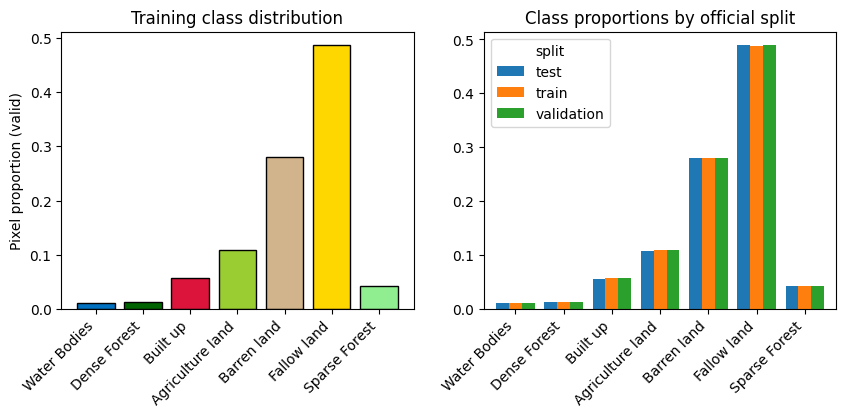

In [14]:
import matplotlib; import matplotlib.pyplot as plt
cols = [f"m{k}" for k in range(8)]
split_counts = good.groupby("split")[cols].sum()
tr = good[good.split == "train"]
px_src = tr[[f"m{k}" for k in range(1, 8)]].sum().values.astype(np.float64)           # source 1..7 == model 0..6 order
ign = int(tr.m0.sum()); valid = px_src.sum()
beta = 0.9999
stats = {"train_pixels_model_order": px_src.tolist(), "class_names_model_order": MODEL_CLASS_NAMES, "train_ignored_unclassified_pixels": ign,
         "train_ignored_fraction": ign / (ign + valid), "train_class_proportion": (px_src / valid).tolist(),
         "effective_number_beta": beta, "effective_number": ((1 - beta ** px_src) / (1 - beta)).tolist(),
         "image_level_occurrence": {MODEL_CLASS_NAMES[k]: int((tr[f"m{k+1}"] > 0).sum()) for k in range(7)}, "n_train_images": int(len(tr))}
json.dump(stats, open(f"{ROOT}/dataset_analysis/class_stats.json", "w"), indent=2)
tab = pd.DataFrame({"class": MODEL_CLASS_NAMES, "train_pixels": px_src, "proportion": px_src / valid, "images_with_class": list(stats["image_level_occurrence"].values())})
display(tab); print(f"ignored (Unclassified) share of all train pixels: {stats['train_ignored_fraction']:.3%}")
split_counts.to_csv(f"{ROOT}/dataset_analysis/class_pixels_per_split.csv")
PAL = {i: tuple(c/255 for c in ({1:(0,112,192),2:(0,100,0),3:(220,20,60),4:(154,205,50),5:(210,180,140),6:(255,215,0),7:(144,238,144)}[i])) for i in range(1, 8)}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(MODEL_CLASS_NAMES, px_src / valid, color=[PAL[i] for i in range(1, 8)], edgecolor="k"); ax[0].set_ylabel("Pixel proportion (valid)"); ax[0].set_title("Training class distribution")
plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
prop = split_counts[[f"m{k}" for k in range(1, 8)]]; prop = prop.div(prop.sum(1), axis=0)
prop.T.plot.bar(ax=ax[1], width=.8); ax[1].set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax[1].set_title("Class proportions by official split")
for ext in ("png", "eps"): fig.savefig(f"{ROOT}/dataset_analysis/class_distribution.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## 10. Training-split normalisation statistics (`normalization_stats.json`)
Computed on **training images only**, on `[0,1]`-scaled RGB. ImageNet statistics are stored separately and only used when `CFG['normalization']='imagenet'`.

In [15]:
NORM_MAX_IMAGES = 30000        # random training subset for speed; None = all training images
SCALE = json.load(open(f"{ROOT}/preprocessing/image_encoding.json"))["scale_max"]
def norm_one(p):
    a = read_image(p).astype(np.float64) / SCALE; return a.sum((0, 1)), (a ** 2).sum((0, 1)), a.shape[0] * a.shape[1]
tpaths = tr.image_path.tolist()
if NORM_MAX_IMAGES and len(tpaths) > NORM_MAX_IMAGES: tpaths = list(np.random.RandomState(SEED).choice(tpaths, NORM_MAX_IMAGES, replace=False))
with Pool(max(2, os.cpu_count())) as p: out = list(tqdm(p.imap(norm_one, tpaths, chunksize=64), total=len(tpaths), desc="normalisation"))
s1 = sum(o[0] for o in out); s2 = sum(o[1] for o in out); n = sum(o[2] for o in out)
mean = s1 / n; std = np.sqrt(s2 / n - mean ** 2)
NORM = {"computed_on": "training split only", "n_images_used": len(tpaths), "n_pixels": int(n), "scale_max": SCALE, "channel_order": ["R(B04)", "G(B03)", "B(B02)"],
        "train_mean": mean.tolist(), "train_std": std.tolist(), "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225]}
json.dump(NORM, open(f"{ROOT}/preprocessing/normalization_stats.json", "w"), indent=2); print(json.dumps(NORM, indent=1))

normalisation:   0%|          | 0/30000 [00:00<?, ?it/s]

{
 "computed_on": "training split only",
 "n_images_used": 30000,
 "n_pixels": 122880000,
 "scale_max": 255.0,
 "channel_order": [
  "R(B04)",
  "G(B03)",
  "B(B02)"
 ],
 "train_mean": [
  0.4879741223702999,
  0.4358757921645173,
  0.42800772531148124
 ],
 "train_std": [
  0.2587732283671688,
  0.25532810903021025,
  0.25463827913247916
 ],
 "imagenet_mean": [
  0.485,
  0.456,
  0.406
 ],
 "imagenet_std": [
  0.229,
  0.224,
  0.225
 ]
}


### 10b. OPTIONAL — pin normalisation statistics to the U-Net run


In [16]:
# OPTIONAL - pin the normalisation statistics to the ones the U-Net baseline was trained with (identical input pipeline).
if REUSE_PART1_FROM and os.path.exists(f"{REUSE_PART1_FROM}/preprocessing/normalization_stats.json"):
    ref = json.load(open(f"{REUSE_PART1_FROM}/preprocessing/normalization_stats.json"))
    d = max(np.abs(np.array(ref["train_mean"]) - np.array(NORM["train_mean"])).max(), np.abs(np.array(ref["train_std"]) - np.array(NORM["train_std"])).max())
    print(f"max |difference| vs the U-Net run's mean/std: {d:.2e}  -> using the U-Net run's statistics")
    NORM = ref; json.dump(NORM, open(f"{ROOT}/preprocessing/normalization_stats.json", "w"), indent=2)
else:
    print("using freshly computed statistics (set REUSE_PART1_FROM above to pin them to the U-Net run's).")


max |difference| vs the U-Net run's mean/std: 0.00e+00  -> using the U-Net run's statistics


## 11. Sample visualisation, provenance & dataset summary

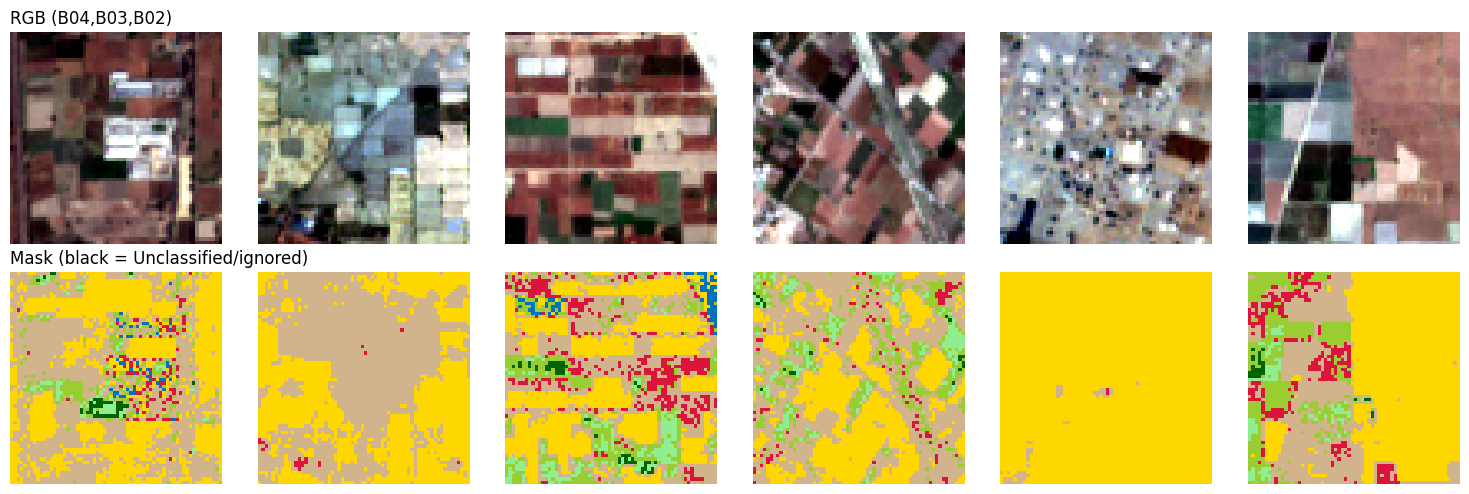

{
 "clean_pairs": {
  "test": 32079,
  "train": 149600,
  "validation": 32079
 },
 "image_sizes": {
  "64x64": 213758
 },
 "constant_image_size": true,
 "leakage_checks": {
  "img_md5_in_multiple_splits": 0,
  "img_md5_duplicated_within_one_split": 0,
  "mask_md5_in_multiple_splits": 0,
  "mask_md5_duplicated_within_one_split": 0,
  "image_filename_stems_in_multiple_splits": 0
 }
}

PART 1 COMPLETE. Compare the counts above with the published description (~213,761 samples); report any discrepancy in your paper.


In [17]:
PAL_RGB = np.array([(0,112,192),(0,100,0),(220,20,60),(154,205,50),(210,180,140),(255,215,0),(144,238,144)], np.uint8)
def colour_src(src):
    o = np.zeros(src.shape + (3,), np.uint8)
    for k in range(1, 8): o[src == k] = PAL_RGB[k-1]
    return o
sm = tr.sample(6, random_state=SEED); fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for j, (_, r) in enumerate(sm.iterrows()):
    ax[0, j].imshow(read_image(r.image_path)); ax[1, j].imshow(colour_src(decode_mask(read_mask_raw(r.mask_path), MASK_ENC))); ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title("RGB (B04,B03,B02)", loc="left"); ax[1, 0].set_title("Mask (black = Unclassified/ignored)", loc="left"); plt.tight_layout()
fig.savefig(f"{ROOT}/dataset_analysis/sample_pairs.png", dpi=200); plt.show()

summary = {"dataset": "Sen-2 LULC", "doi_data": DATASET_DOI, "doi_article": "10.1016/j.dib.2023.109724", "version_requested": DATASET_VERSION,
           "source_used": DATA_SOURCE, "download_date": RUN_STARTED, "mendeley_api_metadata_keys": sorted(DATASET_META.keys()) if DATASET_META else None,
           "pairs_found": {k: v for k, v in unmatched.items()}, "clean_pairs": good.groupby("split").size().to_dict(), "corrupt_pairs": int(len(bad)),
           "image_sizes": {f"{h}x{w}": int(c) for (h, w), c in good.groupby(["img_h", "img_w"]).size().items()}, "constant_image_size": bool(CONST_SIZE),
           "mask_encoding": MASK_ENC, "leakage_checks": leak, "geographic_independence": "NOT verifiable from patch files without coordinates; do not claim it",
           "input_channels": 3, "band_mode": "RGB", "ignored_source_label": 0, "mask_value_note": "model ids 0..6 = source 1..7"}
json.dump(summary, open(f"{ROOT}/dataset_analysis/dataset_summary.json", "w"), indent=2, default=str)
json.dump({"api_log": api_log[-10:], "official_files": OFFICIAL_FILES, "listing_error": LISTING_ERROR, "download_ok": DOWNLOAD_OK, "data_source": DATA_SOURCE,
           "started": RUN_STARTED}, open(f"{OFFICIAL_DIR}/download_report.json", "w"), indent=2, default=str)
if not os.path.exists(f"{OFFICIAL_DIR}/download_manifest.csv"): pd.DataFrame(DL_RECORDS).to_csv(f"{OFFICIAL_DIR}/download_manifest.csv", index=False)
print(json.dumps({k: summary[k] for k in ("clean_pairs", "image_sizes", "constant_image_size", "leakage_checks")}, indent=1))
print("\nPART 1 COMPLETE. Compare the counts above with the published description (~213,761 samples); report any discrepancy in your paper.")

# PART 2 — RS3Mamba: model, genuine DDP training, evaluation (same protocol as the U-Net baseline)

## 12. Central experiment configuration

Everything that defines an experiment lives in `CFG`. **Starting settings, not tuned optima.** `model='rs3mamba'` is this notebook's subject; `unet`, `unetplusplus`, `deeplabv3plus`, `segformer` remain registered so any baseline can be reproduced with this same code.
`samba`, `sam_rs`, `sasam`, `sam2_semantic` still raise `NotImplementedError` (no silent substitution). **Only the model-specific keys below differ from the U-Net notebook's `CFG`.**

Option menus — **loss:** `ce, wce, dice, ce_dice, focal, focal_dice` · **optimizer:** `adamw, adam, sgd` · **scheduler:** `cosine, plateau, onecycle, constant, warmup_cosine` ·
**class_weighting:** `none, inverse, median, effective, custom` (use with `loss='wce'` or `ce_dice`) · **augmentation:** `none, light, moderate, strong` · **normalization:** `train, imagenet, unit`.
Lovasz-Softmax is not implemented (stated rather than faked).

In [18]:
CFG = dict(
    model="rs3mamba", encoder="resnet18_vssm_tiny", pretrained=True,   # RS3Mamba; `encoder` is only a label for the experiment id. pretrained: ResNet-18 + VMamba-T ImageNet weights; False = random init
    segformer_checkpoint="nvidia/mit-b0",                               # used only when model == 'segformer' (mit-b0 / mit-b1)
    rs3mamba=dict(backbone="resnet18.fb_swsl_ig1b_ft_in1k",             # = official 'swsl_resnet18'
                  window_size=8, decode_channels=64, dropout=0.1,       # official RS3Mamba values
                  vss_drop_path=0.2, vmamba_pretrained=True,           # official stochastic-depth rate; ImageNet VMamba-T for the VSS branch
                  scan_backend="cuda",                                  # "cuda" = fused kernel (fails loudly if missing) | "torch" = exact but very slow
                  vss_checkpoint=False),                                # True = activation checkpointing in VSS layers (only needed for scan_backend="torch")
    input_channels=3, num_classes=7, input_size=None,                   # None = native resolution (reflect-padded to /32 inside the model, cropped back)
    epochs=150, patience=30, monitor="val_miou", seed=42,
    optimizer="adamw", lr=1e-4, weight_decay=1e-4, min_lr=1e-6,
    scheduler="cosine", warmup_epochs=5, plateau_patience=10,
    loss="ce_dice", focal_gamma=2.0, class_weighting="none", custom_class_weights=None,
    augmentation="moderate", normalization="train",
    batch_size=32, eval_batch_size=64, grad_accum=1, grad_clip=1.0,    # batch_size is PER GPU; effective = batch x GPUs x accum
    amp=True, num_workers=2, prefetch=2, sync_bn=False, find_unused_parameters=False, cudnn_benchmark=True,
    time_limit_hours=11.0,                                              # graceful stop before Kaggle's 12 h limit; resume from latest.pt
    resume=None, max_train_samples=None, max_eval_samples=None,        # sub-sampling ONLY for smoke tests
    progress_every=25, eval_progress_every=50,                        # progress monitoring during each epoch
    nproc=2,                                                            # processes = GPUs. 1 => single-GPU debugging fallback
    nccl_p2p_disable=False,                                             # set True if NCCL hangs at start-up on your T4 pair
)
json.dump(CFG, open(f"{ROOT}/reproducibility/default_config.json", "w"), indent=2)
json.dump({str(i): list(c) for i, c in {1:(0,112,192),2:(0,100,0),3:(220,20,60),4:(154,205,50),5:(210,180,140),6:(255,215,0),7:(144,238,144)}.items()},
          open(f"{ROOT}/preprocessing/class_colors.json", "w"), indent=2)
print(json.dumps(CFG, indent=1))

{
 "model": "rs3mamba",
 "encoder": "resnet18_vssm_tiny",
 "pretrained": true,
 "segformer_checkpoint": "nvidia/mit-b0",
 "rs3mamba": {
  "backbone": "resnet18.fb_swsl_ig1b_ft_in1k",
  "window_size": 8,
  "decode_channels": 64,
  "dropout": 0.1,
  "vss_drop_path": 0.2,
  "vmamba_pretrained": true,
  "scan_backend": "cuda",
  "vss_checkpoint": false
 },
 "input_channels": 3,
 "num_classes": 7,
 "input_size": null,
 "epochs": 150,
 "patience": 30,
 "monitor": "val_miou",
 "seed": 42,
 "optimizer": "adamw",
 "lr": 0.0001,
 "weight_decay": 0.0001,
 "min_lr": 1e-06,
 "scheduler": "cosine",
 "warmup_epochs": 5,
 "plateau_patience": 10,
 "loss": "ce_dice",
 "focal_gamma": 2.0,
 "class_weighting": "none",
 "custom_class_weights": null,
 "augmentation": "moderate",
 "normalization": "train",
 "batch_size": 32,
 "eval_batch_size": 64,
 "grad_accum": 1,
 "grad_clip": 1.0,
 "amp": true,
 "num_workers": 2,
 "prefetch": 2,
 "sync_bn": false,
 "find_unused_parameters": false,
 "cudnn_benchmark": true

## 13. Companion modules (written to `/kaggle/working/lulc_research/code/`)
`common.py`: dataset/augmentation, model registry, losses, confusion-matrix metrics, plots · `train.py`: DDP trainer/evaluator · `smoke_test.py` · plus the new `mamba_scan.py` (§3a) and `rs3mamba_model.py` (below).

In [19]:
%%writefile /kaggle/working/lulc_research/code/rs3mamba_model.py
"""rs3mamba_model.py -- RS3Mamba (Ma, Zhang & Pun, IEEE GRSL 2024) for the Sen-2 LULC benchmark.

Port of the official code (github.com/sstary/SSRS, RS3Mamba/model/{RS3Mamba,SwinUMamba}.py, Apache-2.0).
Architecture = official: ResNet-18 branch + VSS (VMamba-Tiny, depths 2-2-9-2) branch, per-stage window-attention
fusion (FusionBlock), global-local-attention decoder.  Parameter names are identical to the official ones so the
official ImageNet VMamba-Tiny checkpoint loads unchanged.

Deliberate differences (everything else is verbatim):
  1. The window size of the attention blocks is min(window_size, H, W) of the current feature map, and the reflect
     padding to a window multiple uses a 4-tuple.  The official code pads with a 2-tuple, which torch rejects for 4-D
     input, so it CRASHES for any feature map that is not a multiple of 8 (this dataset is 64x64 -> 16/8/4/2-px maps).
     For maps that are multiples of 8 the behaviour is bit-identical to the official one.
  2. torch/timm only: no einops, no monai (unused there), timm.layers instead of the deprecated timm.models.layers,
     torch.meshgrid(indexing='ij'), no duplicate registration of the ResNet stem modules, unused classes dropped.
  3. The selective scan goes through mamba_scan.py (fused CUDA kernel, or an exact pure-PyTorch fallback).
"""
import os, re, math, time, json, hashlib, urllib.request
from typing import Optional
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint as cp
import timm
from timm.layers import DropPath, trunc_normal_

import mamba_scan as MS

DEFAULTS = dict(backbone="resnet18.fb_swsl_ig1b_ft_in1k",   # = official 'swsl_resnet18'
                window_size=8, decode_channels=64, dropout=0.1, vss_drop_path=0.2,
                vmamba_pretrained=True, vmamba_ckpt=None, scan_backend="cuda", vss_checkpoint=False)
# immutable pin of the official ImageNet VMamba-Tiny weights shipped in the RS3Mamba repository
VMAMBA_URL = "https://raw.githubusercontent.com/sstary/SSRS/6aabefdd4123842afc822463e0b8be3965e39b6c/RS3Mamba/pretrain/vmamba_tiny_e292.pth"
VMAMBA_SHA256 = "dbc0cc4f5ec0e45db5fba7c939d2c7d9b617e891ac10766912a8d604c37c5e47"
VMAMBA_BYTES = 91649482


# ============================================================================ VSS (VMamba) branch
class PatchEmbed2D(nn.Module):
    def __init__(self, patch_size=4, in_chans=3, embed_dim=96, norm_layer=None):
        super().__init__()
        patch_size = (patch_size, patch_size) if isinstance(patch_size, int) else patch_size
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.norm = norm_layer(embed_dim) if norm_layer is not None else None

    def forward(self, x):
        x = self.proj(x).permute(0, 2, 3, 1)
        return self.norm(x) if self.norm is not None else x


class PatchMerging2D(nn.Module):
    def __init__(self, dim, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = norm_layer(4 * dim)

    def forward(self, x):
        B, H, W, C = x.shape
        h2, w2 = H // 2, W // 2                       # odd sizes are cropped (official behaviour)
        x = torch.cat([x[:, 0::2, 0::2][:, :h2, :w2], x[:, 1::2, 0::2][:, :h2, :w2],
                       x[:, 0::2, 1::2][:, :h2, :w2], x[:, 1::2, 1::2][:, :h2, :w2]], -1)
        return self.reduction(self.norm(x))


class SS2D(nn.Module):
    """2D selective scan: 4 scan directions (row / column, forward / reverse), fused into one scan call."""
    def __init__(self, d_model, d_state=16, d_conv=3, expand=2, dt_rank="auto", dt_min=0.001, dt_max=0.1,
                 dt_init="random", dt_scale=1.0, dt_init_floor=1e-4, dropout=0., conv_bias=True, bias=False):
        super().__init__()
        self.d_model, self.d_state, self.d_conv, self.expand = d_model, d_state, d_conv, expand
        self.d_inner = int(expand * d_model)
        self.dt_rank = math.ceil(d_model / 16) if dt_rank == "auto" else dt_rank
        self.in_proj = nn.Linear(d_model, self.d_inner * 2, bias=bias)
        self.conv2d = nn.Conv2d(self.d_inner, self.d_inner, groups=self.d_inner, bias=conv_bias,
                                kernel_size=d_conv, padding=(d_conv - 1) // 2)
        self.act = nn.SiLU()
        xp = [nn.Linear(self.d_inner, self.dt_rank + d_state * 2, bias=False) for _ in range(4)]
        self.x_proj_weight = nn.Parameter(torch.stack([t.weight for t in xp], dim=0))          # (K=4, R+2N, D)
        dts = [self.dt_init(self.dt_rank, self.d_inner, dt_scale, dt_init, dt_min, dt_max, dt_init_floor) for _ in range(4)]
        self.dt_projs_weight = nn.Parameter(torch.stack([t.weight for t in dts], dim=0))       # (4, D, R)
        self.dt_projs_bias = nn.Parameter(torch.stack([t.bias for t in dts], dim=0))           # (4, D)
        self.A_logs = self.A_log_init(d_state, self.d_inner, copies=4)                          # (4*D, N)
        self.Ds = self.D_init(self.d_inner, copies=4)                                           # (4*D,)
        self.out_norm = nn.LayerNorm(self.d_inner)
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=bias)
        self.dropout = nn.Dropout(dropout) if dropout > 0. else None

    @staticmethod
    def dt_init(dt_rank, d_inner, dt_scale=1.0, dt_init="random", dt_min=0.001, dt_max=0.1, dt_init_floor=1e-4):
        dt_proj = nn.Linear(dt_rank, d_inner, bias=True)
        std = dt_rank ** -0.5 * dt_scale
        if dt_init == "constant":
            nn.init.constant_(dt_proj.weight, std)
        elif dt_init == "random":
            nn.init.uniform_(dt_proj.weight, -std, std)
        else:
            raise NotImplementedError(dt_init)
        dt = torch.exp(torch.rand(d_inner) * (math.log(dt_max) - math.log(dt_min)) + math.log(dt_min)).clamp(min=dt_init_floor)
        with torch.no_grad():
            dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))          # inverse softplus
        return dt_proj

    @staticmethod
    def A_log_init(d_state, d_inner, copies=1):
        A = torch.arange(1, d_state + 1, dtype=torch.float32).unsqueeze(0).expand(d_inner, -1).contiguous()
        A_log = torch.log(A).unsqueeze(0).expand(copies, -1, -1).reshape(copies * d_inner, d_state).contiguous()
        p = nn.Parameter(A_log); p._no_weight_decay = True
        return p

    @staticmethod
    def D_init(d_inner, copies=1):
        p = nn.Parameter(torch.ones(copies * d_inner)); p._no_weight_decay = True
        return p

    def forward_core(self, x):
        B, C, H, W = x.shape
        L, K = H * W, 4
        x_hwwh = torch.stack([x.reshape(B, -1, L), torch.transpose(x, 2, 3).contiguous().reshape(B, -1, L)], dim=1).reshape(B, 2, -1, L)
        xs = torch.cat([x_hwwh, torch.flip(x_hwwh, dims=[-1])], dim=1)                        # (B,K,D,L)
        x_dbl = torch.einsum("b k d l, k c d -> b k c l", xs.reshape(B, K, -1, L), self.x_proj_weight)
        dts, Bs, Cs = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=2)
        dts = torch.einsum("b k r l, k d r -> b k d l", dts.reshape(B, K, -1, L), self.dt_projs_weight)
        xs = xs.float().reshape(B, -1, L)
        dts = dts.contiguous().float().reshape(B, -1, L)
        Bs = Bs.float().reshape(B, K, -1, L).contiguous()
        Cs = Cs.float().reshape(B, K, -1, L).contiguous()
        Ds = self.Ds.float().reshape(-1)
        As = -torch.exp(self.A_logs.float()).reshape(-1, self.d_state)
        out_y = MS.selective_scan(xs, dts, As, Bs, Cs, Ds, self.dt_projs_bias.float().reshape(-1)).reshape(B, K, -1, L)
        inv_y = torch.flip(out_y[:, 2:4], dims=[-1]).reshape(B, 2, -1, L)
        wh_y = torch.transpose(out_y[:, 1].reshape(B, -1, W, H), 2, 3).contiguous().reshape(B, -1, L)
        invwh_y = torch.transpose(inv_y[:, 1].reshape(B, -1, W, H), 2, 3).contiguous().reshape(B, -1, L)
        return out_y[:, 0], inv_y[:, 0], wh_y, invwh_y

    def forward(self, x):
        B, H, W, C = x.shape
        x, z = self.in_proj(x).chunk(2, dim=-1)
        x = self.act(self.conv2d(x.permute(0, 3, 1, 2).contiguous()))
        y1, y2, y3, y4 = self.forward_core(x)
        y = (y1 + y2 + y3 + y4).transpose(1, 2).contiguous().reshape(B, H, W, -1)
        y = self.out_norm(y) * F.silu(z)
        out = self.out_proj(y)
        return self.dropout(out) if self.dropout is not None else out


class VSSBlock(nn.Module):
    def __init__(self, hidden_dim=0, drop_path=0., norm_layer=None, attn_drop_rate=0., d_state=16):
        super().__init__()
        norm_layer = norm_layer or (lambda d: nn.LayerNorm(d, eps=1e-6))
        self.ln_1 = norm_layer(hidden_dim)
        self.self_attention = SS2D(d_model=hidden_dim, dropout=attn_drop_rate, d_state=d_state)
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        return x + self.drop_path(self.self_attention(self.ln_1(x)))


class VSSLayer(nn.Module):
    def __init__(self, dim, depth, attn_drop=0., drop_path=0., norm_layer=None, use_checkpoint=False, d_state=16):
        super().__init__()
        self.use_checkpoint = use_checkpoint
        self.blocks = nn.ModuleList([VSSBlock(dim, drop_path[i] if isinstance(drop_path, list) else drop_path,
                                              norm_layer, attn_drop, d_state) for i in range(depth)])

    def forward(self, x):
        for blk in self.blocks:
            x = cp.checkpoint(blk, x, use_reentrant=False) if (self.use_checkpoint and self.training) else blk(x)
        return x


class VSSMEncoder(nn.Module):
    def __init__(self, patch_size=4, in_chans=3, depths=(2, 2, 9, 2), dims=(96, 192, 384, 768), d_state=16,
                 drop_rate=0., attn_drop_rate=0., drop_path_rate=0.2, use_checkpoint=False):
        super().__init__()
        self.num_layers, self.dims = len(depths), list(dims)
        self.patch_embed = PatchEmbed2D(patch_size, in_chans, dims[0], norm_layer=nn.LayerNorm)
        self.pos_drop = nn.Dropout(p=drop_rate)
        dpr = [v.item() for v in torch.linspace(0, drop_path_rate, sum(depths))]
        self.layers, self.downsamples = nn.ModuleList(), nn.ModuleList()
        for i in range(self.num_layers):
            self.layers.append(VSSLayer(dims[i], depths[i], attn_drop_rate, dpr[sum(depths[:i]):sum(depths[:i + 1])],
                                        None, use_checkpoint, d_state))
            if i < self.num_layers - 1:
                self.downsamples.append(PatchMerging2D(dims[i]))
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.02)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0); nn.init.constant_(m.weight, 1.0)

    def forward(self, x):
        outs = [x]
        x = self.pos_drop(self.patch_embed(x))
        for s, layer in enumerate(self.layers):
            x = layer(x)
            outs.append(x.permute(0, 3, 1, 2))
            if s < len(self.downsamples):
                x = self.downsamples[s](x)
        return outs


# ============================================================================ CNN / attention building blocks
def _pad_same(k, s, d):
    return ((s - 1) + d * (k - 1)) // 2


class ConvBNReLU(nn.Sequential):
    def __init__(self, i, o, kernel_size=3, dilation=1, stride=1, norm_layer=nn.BatchNorm2d, bias=False):
        super().__init__(nn.Conv2d(i, o, kernel_size, bias=bias, dilation=dilation, stride=stride,
                                   padding=_pad_same(kernel_size, stride, dilation)), norm_layer(o), nn.ReLU6())


class ConvBN(nn.Sequential):
    def __init__(self, i, o, kernel_size=3, dilation=1, stride=1, norm_layer=nn.BatchNorm2d, bias=False):
        super().__init__(nn.Conv2d(i, o, kernel_size, bias=bias, dilation=dilation, stride=stride,
                                   padding=_pad_same(kernel_size, stride, dilation)), norm_layer(o))


class Conv(nn.Sequential):
    def __init__(self, i, o, kernel_size=3, dilation=1, stride=1, bias=False):
        super().__init__(nn.Conv2d(i, o, kernel_size, bias=bias, dilation=dilation, stride=stride,
                                   padding=_pad_same(kernel_size, stride, dilation)))


class SeparableConvBN(nn.Sequential):
    def __init__(self, i, o, kernel_size=3, stride=1, dilation=1, norm_layer=nn.BatchNorm2d):
        super().__init__(nn.Conv2d(i, i, kernel_size, stride=stride, dilation=dilation,
                                   padding=_pad_same(kernel_size, stride, dilation), groups=i, bias=False),
                         norm_layer(o), nn.Conv2d(i, o, kernel_size=1, bias=False))


class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.ReLU6, drop=0.):
        super().__init__()
        out_features, hidden_features = out_features or in_features, hidden_features or in_features
        self.fc1 = nn.Conv2d(in_features, hidden_features, 1, 1, 0, bias=True)
        self.act = act_layer()
        self.fc2 = nn.Conv2d(hidden_features, out_features, 1, 1, 0, bias=True)
        self.drop = nn.Dropout(drop, inplace=True)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))


_REL_IDX = {}


def _rel_index(w, ws, device):
    """relative-position index of a w x w window into the (2ws-1)^2 bias table (identical to official when w == ws)."""
    key = (w, ws, device.type, device.index)
    if key not in _REL_IDX:
        c = torch.stack(torch.meshgrid(torch.arange(w), torch.arange(w), indexing="ij")).flatten(1)
        r = (c[:, :, None] - c[:, None, :]).permute(1, 2, 0).contiguous()
        _REL_IDX[key] = ((r[:, :, 0] + ws - 1) * (2 * ws - 1) + (r[:, :, 1] + ws - 1)).to(device)
    return _REL_IDX[key]


class _WindowAttention(nn.Module):
    """Shared implementation of the official GlobalLocalAttention (x == y) and FusionAttention (global from x, local from y)."""
    def __init__(self, dim, local_dim, num_heads, qkv_bias, window_size):
        super().__init__()
        self.num_heads, self.scale, self.ws = num_heads, (dim // num_heads) ** -0.5, window_size
        self.qkv = Conv(dim, 3 * dim, kernel_size=1, bias=qkv_bias)
        self.local1 = ConvBN(local_dim, dim, kernel_size=3)
        self.local2 = ConvBN(local_dim, dim, kernel_size=1)
        self.proj = SeparableConvBN(dim, dim, kernel_size=window_size)
        self.attn_x = nn.AvgPool2d(kernel_size=(window_size, 1), stride=1, padding=(window_size // 2 - 1, 0))
        self.attn_y = nn.AvgPool2d(kernel_size=(1, window_size), stride=1, padding=(0, window_size // 2 - 1))
        self.relative_position_bias_table = nn.Parameter(torch.zeros((2 * window_size - 1) ** 2, num_heads))
        trunc_normal_(self.relative_position_bias_table, std=.02)

    def _attend(self, x, y):
        B, C, H, W = x.shape
        local = self.local2(y) + self.local1(y)
        w = max(1, min(self.ws, H, W))                                 # <- the only functional change (see module docstring)
        if W % w or H % w:                                             # 4-tuple: 2-tuple reflect pads are unsupported on 4-D input
            x = F.pad(x, (0, (-W) % w, 0, (-H) % w), mode="reflect")
        Hp, Wp = x.shape[-2:]
        nh, d, hh, ww = self.num_heads, C // self.num_heads, Hp // w, Wp // w
        qkv = self.qkv(x).reshape(B, 3, nh, d, hh, w, ww, w).permute(1, 0, 4, 6, 2, 5, 7, 3).reshape(3, B * hh * ww, nh, w * w, d)
        q, k, v = qkv[0], qkv[1], qkv[2]
        dots = (q @ k.transpose(-2, -1)) * self.scale
        bias = self.relative_position_bias_table[_rel_index(w, self.ws, x.device).reshape(-1)].reshape(w * w, w * w, -1)
        dots = dots + bias.permute(2, 0, 1).contiguous().unsqueeze(0)
        attn = dots.softmax(dim=-1) @ v
        attn = attn.reshape(B, hh, ww, nh, w, w, d).permute(0, 3, 6, 1, 4, 2, 5).reshape(B, nh * d, Hp, Wp)[:, :, :H, :W]
        out = self.attn_x(F.pad(attn, (0, 0, 0, 1), mode="reflect")) + self.attn_y(F.pad(attn, (0, 1, 0, 0), mode="reflect"))
        out = self.proj(F.pad(out + local, (0, 1, 0, 1), mode="reflect"))
        return out[:, :, :H, :W]


class GlobalLocalAttention(_WindowAttention):
    def __init__(self, dim=256, num_heads=16, qkv_bias=False, window_size=8):
        super().__init__(dim, dim, num_heads, qkv_bias, window_size)

    def forward(self, x):
        return self._attend(x, x)


class FusionAttention(_WindowAttention):
    def __init__(self, dim=256, ssmdims=256, num_heads=16, qkv_bias=False, window_size=8):
        super().__init__(dim, ssmdims, num_heads, qkv_bias, window_size)

    def forward(self, x, y):
        return self._attend(x, y)


class Block(nn.Module):
    def __init__(self, dim=256, num_heads=16, mlp_ratio=4., qkv_bias=False, drop=0., drop_path=0.,
                 act_layer=nn.ReLU6, norm_layer=nn.BatchNorm2d, window_size=8):
        super().__init__()
        self.norm1 = norm_layer(dim)
        self.attn = GlobalLocalAttention(dim, num_heads, qkv_bias, window_size)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        self.mlp = Mlp(dim, int(dim * mlp_ratio), dim, act_layer, drop)
        self.norm2 = norm_layer(dim)

    def forward(self, x):
        x = x + self.drop_path(self.attn(self.norm1(x)))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class FusionBlock(nn.Module):
    def __init__(self, dim=256, ssmdims=256, num_heads=16, mlp_ratio=4., qkv_bias=False, drop=0., drop_path=0.,
                 act_layer=nn.ReLU6, norm_layer=nn.BatchNorm2d, window_size=8):
        super().__init__()
        self.normx, self.normy = norm_layer(dim), norm_layer(ssmdims)
        self.attn = FusionAttention(dim, ssmdims, num_heads, qkv_bias, window_size)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        self.mlp = Mlp(dim, int(dim * mlp_ratio), dim, act_layer, drop)
        self.norm2 = norm_layer(dim)

    def forward(self, x, y):
        x = x + self.drop_path(self.attn(self.normx(x), self.normy(y)))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class WF(nn.Module):
    def __init__(self, in_channels=128, decode_channels=128, eps=1e-8):
        super().__init__()
        self.pre_conv = Conv(in_channels, decode_channels, kernel_size=1)
        self.weights = nn.Parameter(torch.ones(2, dtype=torch.float32))
        self.eps = eps
        self.post_conv = ConvBNReLU(decode_channels, decode_channels, kernel_size=3)

    def forward(self, x, res):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        w = F.relu(self.weights); w = w / (w.sum(0) + self.eps)
        return self.post_conv(w[0] * self.pre_conv(res) + w[1] * x)


class FeatureRefinementHead(nn.Module):
    def __init__(self, in_channels=64, decode_channels=64):
        super().__init__()
        self.pre_conv = Conv(in_channels, decode_channels, kernel_size=1)
        self.weights = nn.Parameter(torch.ones(2, dtype=torch.float32))
        self.eps = 1e-8
        self.post_conv = ConvBNReLU(decode_channels, decode_channels, kernel_size=3)
        self.pa = nn.Sequential(nn.Conv2d(decode_channels, decode_channels, 3, padding=1, groups=decode_channels), nn.Sigmoid())
        self.ca = nn.Sequential(nn.AdaptiveAvgPool2d(1), Conv(decode_channels, decode_channels // 16, kernel_size=1), nn.ReLU6(),
                                Conv(decode_channels // 16, decode_channels, kernel_size=1), nn.Sigmoid())
        self.shortcut = ConvBN(decode_channels, decode_channels, kernel_size=1)
        self.proj = SeparableConvBN(decode_channels, decode_channels, kernel_size=3)
        self.act = nn.ReLU6()

    def forward(self, x, res):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        w = F.relu(self.weights); w = w / (w.sum(0) + self.eps)
        x = self.post_conv(w[0] * self.pre_conv(res) + w[1] * x)
        shortcut = self.shortcut(x)
        x = self.pa(x) * x + self.ca(x) * x
        return self.act(self.proj(x) + shortcut)


class Decoder(nn.Module):
    def __init__(self, encoder_channels=(64, 128, 256, 512), decode_channels=64, dropout=0.1, window_size=8, num_classes=6):
        super().__init__()
        self.pre_conv = ConvBN(encoder_channels[-1], decode_channels, kernel_size=1)
        self.b4 = Block(decode_channels, 8, window_size=window_size)
        self.b3 = Block(decode_channels, 8, window_size=window_size)
        self.p3 = WF(encoder_channels[-2], decode_channels)
        self.b2 = Block(decode_channels, 8, window_size=window_size)
        self.p2 = WF(encoder_channels[-3], decode_channels)
        self.p1 = FeatureRefinementHead(encoder_channels[-4], decode_channels)
        self.segmentation_head = nn.Sequential(ConvBNReLU(decode_channels, decode_channels), nn.Dropout2d(p=dropout, inplace=True),
                                               Conv(decode_channels, num_classes, kernel_size=1))

    def forward(self, res1, res2, res3, res4, h, w):
        x = self.b4(self.pre_conv(res4))
        x = self.b3(self.p3(x, res3))
        x = self.b2(self.p2(x, res2))
        x = self.segmentation_head(self.p1(x, res1))
        return F.interpolate(x, size=(h, w), mode="bilinear", align_corners=False)


# ============================================================================ RS3Mamba
class RS3Mamba(nn.Module):
    def __init__(self, decode_channels=64, dropout=0.1, backbone_name="resnet18.fb_swsl_ig1b_ft_in1k", pretrained=True,
                 window_size=8, num_classes=6, vss_drop_path=0.2, use_checkpoint=False):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, features_only=True, output_stride=32, out_indices=(1, 2, 3, 4),
                                          pretrained=pretrained)
        self.stem = nn.Sequential(nn.Conv2d(3, 48, kernel_size=7, stride=2, padding=3), nn.InstanceNorm2d(48, eps=1e-5, affine=True))
        self.vssm_encoder = VSSMEncoder(patch_size=2, in_chans=48, drop_path_rate=vss_drop_path, use_checkpoint=use_checkpoint)
        enc_ch = self.backbone.feature_info.channels()
        ssm_dims = [96, 192, 384, 768]
        self.decoder = Decoder(enc_ch, decode_channels, dropout, window_size, num_classes)
        self.Fuse = nn.ModuleList([FusionBlock(enc_ch[i], ssm_dims[i], window_size=window_size) for i in range(4)])

    def forward(self, x):
        h, w = x.shape[-2:]
        vss = self.vssm_encoder(self.stem(x))              # 48@/2, 96@/4, 192@/8, 384@/16, 768@/32
        b = self.backbone
        x = b.maxpool(b.act1(b.bn1(b.conv1(x))))
        ress = []
        for i, layer in enumerate((b.layer1, b.layer2, b.layer3, b.layer4)):
            x = self.Fuse[i](layer(x), vss[i + 1])
            ress.append(x)
        return self.decoder(ress[0], ress[1], ress[2], ress[3], h, w)


# ============================================================================ pretrained weights
def fetch_vmamba_tiny(dst, retries=4):
    """Download (pinned commit) + verify the official ImageNet VMamba-Tiny weights.  Idempotent."""
    os.makedirs(os.path.dirname(dst), exist_ok=True)

    def sha(p):
        h = hashlib.sha256()
        with open(p, "rb") as f:
            for b in iter(lambda: f.read(1 << 22), b""):
                h.update(b)
        return h.hexdigest()
    if os.path.exists(dst) and os.path.getsize(dst) == VMAMBA_BYTES and sha(dst) == VMAMBA_SHA256:
        return dst
    for a in range(retries):
        try:
            urllib.request.urlretrieve(VMAMBA_URL, dst + ".part")
            if os.path.getsize(dst + ".part") != VMAMBA_BYTES or sha(dst + ".part") != VMAMBA_SHA256:
                raise IOError("size/sha256 mismatch for downloaded VMamba-Tiny checkpoint")
            os.replace(dst + ".part", dst)
            return dst
        except Exception as e:
            print(f"  download attempt {a + 1}/{retries} failed: {e!r}"); time.sleep(3 * (a + 1))
    raise RuntimeError(f"could not obtain {VMAMBA_URL}; download it manually to {dst}")


def load_vmamba_tiny(model, path):
    """Official mapping (RS3Mamba.load_pretrained_ckpt): VMamba-T keys -> model.vssm_encoder.*, `layers.i.downsample` ->
    `downsamples.i`; classifier/stem-dependent tensors are skipped.  (The official skip list names patch_embed.norm.weight
    twice, so patch_embed.norm.BIAS is loaded and the weight is not -- reproduced as-is.)  Returns a report dict."""
    skip = {"norm.weight", "norm.bias", "head.weight", "head.bias", "patch_embed.proj.weight", "patch_embed.proj.bias",
            "patch_embed.norm.weight"}
    try:
        ck = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        ck = torch.load(path, map_location="cpu", weights_only=False)   # checkpoint from the pinned, sha256-verified file
    sd = model.state_dict()
    loaded, skipped, unmatched = [], [], []
    for k, v in ck["model"].items():
        if k in skip:
            skipped.append(k); continue
        kr = "vssm_encoder." + k
        if "downsample" in kr:
            i = int(re.findall(r"layers\.(\d+)\.downsample", kr)[0])
            kr = kr.replace(f"layers.{i}.downsample", f"downsamples.{i}")
        if kr in sd and sd[kr].shape == v.shape:
            sd[kr] = v; loaded.append(kr)
        else:
            unmatched.append(k)
    model.load_state_dict(sd)
    enc_keys = [k for k in sd if k.startswith("vssm_encoder.layers.") or k.startswith("vssm_encoder.downsamples.")]
    cov = len(set(loaded) & set(enc_keys)) / max(1, len(enc_keys))
    rep = dict(ckpt_tensors=len(ck["model"]), loaded=len(loaded), skipped=skipped, unmatched=unmatched[:10],
               n_unmatched=len(unmatched), vss_layer_tensor_coverage=cov)
    if cov < 0.99:
        raise RuntimeError(f"VMamba-Tiny weights cover only {cov:.1%} of the VSS layers - key mapping failed: {rep}")
    return rep


def build_rs3mamba(cfg, pretrained, root):
    """-> (nn.Module, meta dict).  `pretrained=False` never touches the network or the checkpoint (used for test mode)."""
    rc = {**DEFAULTS, **cfg.get("rs3mamba", {})}
    scan = MS.set_backend(rc["scan_backend"])
    net = RS3Mamba(decode_channels=rc["decode_channels"], dropout=rc["dropout"], backbone_name=rc["backbone"],
                   pretrained=bool(pretrained), window_size=rc["window_size"], num_classes=cfg["num_classes"],
                   vss_drop_path=rc["vss_drop_path"], use_checkpoint=rc["vss_checkpoint"])
    meta = dict(source="official RS3Mamba architecture (sstary/SSRS), local port rs3mamba_model.py", scan_backend=scan["backend"],
                scan_detail=scan["detail"], rs3mamba_config=rc)
    if not pretrained:
        meta["pretrained_provenance"] = "random init"
        return net, meta
    prov = [f"timm '{rc['backbone']}' (ResNet-18 branch)"]
    if rc["vmamba_pretrained"]:
        path = rc["vmamba_ckpt"] or f"{root}/pretrained/vmamba_tiny_e292.pth"
        if not os.path.exists(path):
            raise FileNotFoundError(f"{path} missing - run the 'pretrained weights' cell of the notebook first "
                                    "(done outside the DDP processes to avoid concurrent downloads)")
        meta["vmamba_load_report"] = load_vmamba_tiny(net, path)
        prov.append(f"ImageNet-1k VMamba-Tiny (official RS3Mamba repo, sha256 {VMAMBA_SHA256[:12]}...) for the VSS branch")
    else:
        prov.append("VSS branch random init")
    meta["pretrained_provenance"] = "; ".join(prov) + "; decoder/fusion/stem re-initialised"
    return net, meta


Writing /kaggle/working/lulc_research/code/rs3mamba_model.py


In [20]:
%%writefile /kaggle/working/lulc_research/code/common.py
"""common.py -- dataset, models, losses, metrics, plotting for the Sen-2 LULC benchmark (Part 2)."""
import os, sys, json, time, math, random, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from io_utils import (NUM_CLASSES, IGNORE_INDEX, CLASS_NAMES_SRC, MODEL_CLASS_NAMES, LUT_SRC2MODEL,
                      SRC_FROM_MODEL, read_image, read_mask_raw, decode_mask)

ROOT = os.environ.get("LULC_ROOT", "/kaggle/working/lulc_research")
# One fixed palette used in EVERY figure (source id -> RGB). Saved to preprocessing/class_colors.json by Part 2.
CLASS_COLORS_SRC = {1: (0, 112, 192), 2: (0, 100, 0), 3: (220, 20, 60), 4: (154, 205, 50),
                    5: (210, 180, 140), 6: (255, 215, 0), 7: (144, 238, 144)}
MODEL_COLORS = np.array([CLASS_COLORS_SRC[i] for i in range(1, 8)], dtype=np.uint8)
IGNORE_COLOR = (0, 0, 0)


def load_json(p):
    with open(p) as f:
        return json.load(f)


def save_json(obj, p):
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=str)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def colorize(mask_model):
    """model-id mask (255=ignore) -> HxWx3 uint8 using the shared palette."""
    out = np.zeros(mask_model.shape + (3,), np.uint8)
    out[:] = IGNORE_COLOR
    for k in range(NUM_CLASSES):
        out[mask_model == k] = MODEL_COLORS[k]
    return out


# ----------------------------------------------------------------------------- dataset
AUG_LEVELS = {
    "none":     dict(flip=False, rot=False, bc=0.0, gain=0.0, noise=0.0, blur=0.0),
    "light":    dict(flip=True,  rot=False, bc=0.0, gain=0.0, noise=0.0, blur=0.0),
    "moderate": dict(flip=True,  rot=True,  bc=0.10, gain=0.0, noise=0.0, blur=0.0),
    "strong":   dict(flip=True,  rot=True,  bc=0.20, gain=0.05, noise=0.01, blur=0.2),
}


class LULCDataset(Dataset):
    """Reads (image, mask) pairs from a manifest CSV (columns: id,image_path,mask_path,split).
    Image: RGB scaled to [0,1] by image_encoding.scale_max, then normalised.  Mask: source ids -> model ids (255 ignore).
    Geometric augmentation is applied identically to image and mask; masks are only ever resized with nearest-neighbour."""

    def __init__(self, manifest_csv, cfg, train=False, max_samples=None):
        self.df = pd.read_csv(manifest_csv)
        if max_samples:
            self.df = self.df.sample(n=min(max_samples, len(self.df)), random_state=cfg["seed"]).sort_index().reset_index(drop=True)
        self.ip = self.df["image_path"].tolist(); self.mp = self.df["mask_path"].tolist()
        pre = f"{ROOT}/preprocessing"
        self.enc = load_json(f"{pre}/mask_encoding.json")
        self.scale = float(load_json(f"{pre}/image_encoding.json")["scale_max"])
        nm = cfg["normalization"]
        stats = load_json(f"{ROOT}/preprocessing/normalization_stats.json")
        if nm == "train":
            self.mean, self.std = np.array(stats["train_mean"], np.float32), np.array(stats["train_std"], np.float32)
        elif nm == "imagenet":
            self.mean, self.std = np.array(stats["imagenet_mean"], np.float32), np.array(stats["imagenet_std"], np.float32)
        elif nm == "unit":
            self.mean, self.std = np.zeros(3, np.float32), np.ones(3, np.float32)
        else:
            raise ValueError(nm)
        self.train = train
        self.aug = AUG_LEVELS[cfg["augmentation"]] if train else AUG_LEVELS["none"]
        self.input_size = cfg.get("input_size")  # None = native resolution

    def __len__(self):
        return len(self.ip)

    def _resize(self, img, msk):
        import cv2
        s = self.input_size
        if s and (img.shape[0] != s or img.shape[1] != s):
            img = cv2.resize(img, (s, s), interpolation=cv2.INTER_LINEAR)
            msk = cv2.resize(msk, (s, s), interpolation=cv2.INTER_NEAREST)   # nearest: never creates new class ids
        return img, msk

    def __getitem__(self, i):
        img = read_image(self.ip[i]).astype(np.float32) / self.scale
        msk = LUT_SRC2MODEL[decode_mask(read_mask_raw(self.mp[i]), self.enc)]
        if img.shape[:2] != msk.shape[:2]:
            raise ValueError(f"image/mask shape mismatch: {self.ip[i]} {img.shape} vs {msk.shape}")
        img, msk = self._resize(img, msk)
        a = self.aug
        if self.train:
            if a["flip"]:
                if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
                if random.random() < 0.5: img, msk = img[::-1], msk[::-1]
            if a["rot"]:
                k = random.choice([0, 1, 2, 3] if img.shape[0] == img.shape[1] else [0, 2])
                if k: img, msk = np.rot90(img, k), np.rot90(msk, k)
            if a["bc"] > 0 and random.random() < 0.5:
                c = 1 + random.uniform(-a["bc"], a["bc"]); b = random.uniform(-a["bc"], a["bc"]) * 0.5
                img = (img - 0.5) * c + 0.5 + b
            if a["gain"] > 0 and random.random() < 0.5:
                img = img * (1 + np.random.uniform(-a["gain"], a["gain"], size=(1, 1, 3))).astype(np.float32)
            if a["blur"] > 0 and random.random() < a["blur"]:
                import cv2
                img = cv2.GaussianBlur(np.ascontiguousarray(img), (3, 3), 0)
            if a["noise"] > 0:
                img = img + np.random.normal(0, a["noise"], img.shape).astype(np.float32)
            img = np.clip(img, 0.0, 1.0)
        img = (img - self.mean) / self.std
        x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1), dtype=np.float32))
        y = torch.from_numpy(np.ascontiguousarray(msk).astype(np.int64))
        return x, y, i


class ShardSampler(torch.utils.data.Sampler):
    """Evaluation sampler: rank r takes indices r, r+W, r+2W, ... with NO padding/duplication
    (DistributedSampler pads with repeats, which would double-count samples in the confusion matrix)."""
    def __init__(self, n, rank, world):
        self.idx = list(range(rank, n, world))
    def __iter__(self):
        return iter(self.idx)
    def __len__(self):
        return len(self.idx)


# ----------------------------------------------------------------------------- models
class SegWrapper(nn.Module):
    """Uniform interface: [B,3,H,W] -> [B,7,H,W]. Reflect-pads to a multiple of `multiple`, crops back, and
    bilinearly resizes logits (differentiable) if the net outputs a lower resolution."""
    def __init__(self, net, kind, multiple=32):
        super().__init__(); self.net, self.kind, self.m = net, kind, multiple

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % self.m, (-W) % self.m
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="reflect")
        out = self.net(pixel_values=x) if self.kind == "segformer" else self.net(x)
        out = out.logits if hasattr(out, "logits") else out
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out[..., :H, :W]


def _smp(arch, cfg, pretrained):
    import segmentation_models_pytorch as smp
    cls = {"unet": smp.Unet, "unetplusplus": smp.UnetPlusPlus, "deeplabv3plus": smp.DeepLabV3Plus}[arch]
    w = "imagenet" if pretrained else None
    net = cls(encoder_name=cfg["encoder"], encoder_weights=w, in_channels=3, classes=NUM_CLASSES)
    expected = {"unet": "Unet", "unetplusplus": "UnetPlusPlus", "deeplabv3plus": "DeepLabV3Plus"}[arch]
    assert type(net).__name__ == expected, f"expected {expected}, got {type(net).__name__}"
    return net


def build_model(cfg, pretrained=None):
    """Registry. Heavy imports happen only for the selected model. Raises (never substitutes) for unimplemented ones."""
    name = cfg["model"]
    pre = cfg["pretrained"] if pretrained is None else pretrained
    meta = {"model": name, "pretrained_requested": bool(pre)}
    if name in ("unet", "unetplusplus", "deeplabv3plus"):
        net = _smp(name, cfg, pre)
        meta["source"] = "segmentation_models_pytorch " + __import__("segmentation_models_pytorch").__version__
        meta["pretrained_provenance"] = f"smp encoder weights 'imagenet' for {cfg['encoder']}" if pre else "random init"
        if name == "deeplabv3plus":
            mods = [n.lower() for n, _ in net.named_modules()]
            meta["has_aspp"] = any("aspp" in m for m in mods)
            assert meta["has_aspp"], "DeepLabV3+ decoder without ASPP?"
        model = SegWrapper(net, "smp", 32)
    elif name == "segformer":
        from transformers import SegformerForSemanticSegmentation, SegformerConfig
        id2label = {i: n for i, n in enumerate(MODEL_CLASS_NAMES)}
        if pre:
            net = SegformerForSemanticSegmentation.from_pretrained(
                cfg["segformer_checkpoint"], num_labels=NUM_CLASSES, id2label=id2label,
                label2id={v: k for k, v in id2label.items()}, ignore_mismatched_sizes=True)
            meta["pretrained_provenance"] = f"HF hub '{cfg['segformer_checkpoint']}' (encoder; classifier re-initialised for 7 classes)"
        else:
            c = SegformerConfig.from_pretrained(cfg["segformer_checkpoint"], num_labels=NUM_CLASSES)
            net = SegformerForSemanticSegmentation(c); meta["pretrained_provenance"] = "random init"
        import transformers; meta["source"] = "transformers " + transformers.__version__
        model = SegWrapper(net, "segformer", 32)
    elif name == "rs3mamba":
        import rs3mamba_model as RM          # official RS3Mamba architecture (see module docstring for the documented differences)
        net, rmeta = RM.build_rs3mamba(cfg, pre, ROOT)
        meta.update(rmeta)
        model = SegWrapper(net, "plain", 32)
    elif name in ("samba", "sam_rs", "sasam", "sam2_semantic"):
        raise NotImplementedError(f"'{name}' is implemented in Part 4 (requires inspecting the official repository and "
                                  f"verifying mamba_ssm/CUDA compatibility). It is deliberately NOT replaced by another model.")
    else:
        raise ValueError(f"unknown model '{name}'")
    meta["params_total"] = sum(p.numel() for p in model.parameters())
    meta["params_trainable"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, meta


# ----------------------------------------------------------------------------- losses
class SegLoss(nn.Module):
    """ce | wce | dice | ce_dice | focal | focal_dice.   'wce' = CE with class weights.
    Dice: soft dice computed over the batch, averaged over classes PRESENT in the batch ground truth; ignore pixels excluded.
    Lovasz-Softmax is intentionally not offered (not implemented here)."""
    def __init__(self, name, weights=None, gamma=2.0):
        super().__init__()
        self.name, self.gamma = name, gamma
        self.register_buffer("w", None if weights is None else torch.as_tensor(weights, dtype=torch.float32))
        assert name in ("ce", "wce", "dice", "ce_dice", "focal", "focal_dice"), name
        if name == "wce": assert weights is not None, "wce needs class weights"

    def dice(self, logits, y):
        valid = (y != IGNORE_INDEX)
        t = y.clone(); t[~valid] = 0
        p = logits.softmax(1) * valid.unsqueeze(1)
        oh = F.one_hot(t, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
        inter = (p * oh).sum((0, 2, 3)); card = (p + oh).sum((0, 2, 3)); present = oh.sum((0, 2, 3)) > 0
        d = 1 - (2 * inter + 1e-6) / (card + 1e-6)
        return d[present].mean() if present.any() else logits.sum() * 0

    def focal(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX, reduction="none")
        valid = (y != IGNORE_INDEX)
        pt = torch.exp(-F.cross_entropy(logits, y, ignore_index=IGNORE_INDEX, reduction="none"))
        f = ((1 - pt) ** self.gamma) * ce
        return f[valid].sum() / valid.sum().clamp(min=1)

    def forward(self, logits, y):
        logits = logits.float(); n = self.name
        if n in ("ce", "wce"): return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX)
        if n == "dice": return self.dice(logits, y)
        if n == "ce_dice": return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX) + self.dice(logits, y)
        if n == "focal": return self.focal(logits, y)
        return self.focal(logits, y) + self.dice(logits, y)


def class_weights(mode, stats_json, custom=None, beta=0.9999):
    """Weights in MODEL class order (mean-normalised to 1). Treated as an experimental factor, not a default."""
    if mode in (None, "none"): return None
    if mode == "custom": return np.array(custom, np.float32)
    px = np.array(load_json(stats_json)["train_pixels_model_order"], np.float64)
    if mode == "inverse": w = 1.0 / px
    elif mode == "median": f = px / px.sum(); w = np.median(f) / f
    elif mode == "effective": w = (1 - beta) / (1 - beta ** px)
    else: raise ValueError(mode)
    return (w / w.mean()).astype(np.float32)


# ----------------------------------------------------------------------------- metrics (global confusion matrix)
def confusion_from(pred, target):
    """rows = ground truth, cols = prediction; ignore pixels dropped."""
    v = target != IGNORE_INDEX
    idx = target[v] * NUM_CLASSES + pred[v]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def per_image_stats(pred, target):
    """Per-image OA / mIoU / macro-F1 from per-image confusion matrices (classes with GT+pred pixels==0 are skipped)."""
    B = pred.shape[0]; C = NUM_CLASSES
    v = target != IGNORE_INDEX
    off = torch.arange(B, device=pred.device).view(B, 1, 1) * C * C
    idx = (off + target * C + pred)[v]
    cm = torch.bincount(idx, minlength=B * C * C).reshape(B, C, C).double()
    tp = torch.diagonal(cm, dim1=1, dim2=2); gt = cm.sum(2); pr = cm.sum(1); un = gt + pr - tp
    iou = torch.where(un > 0, tp / un.clamp(min=1), torch.full_like(tp, float("nan")))
    f1d = gt + pr
    f1 = torch.where(f1d > 0, 2 * tp / f1d.clamp(min=1), torch.full_like(tp, float("nan")))
    tot = cm.sum((1, 2))
    acc = torch.where(tot > 0, tp.sum(1) / tot.clamp(min=1), torch.full_like(tot, float("nan")))
    return (torch.nanmean(iou, 1).cpu().numpy(), torch.nanmean(f1, 1).cpu().numpy(),
            acc.cpu().numpy(), tot.cpu().numpy())


def metrics_from_cm(cm):
    """All metrics from the *aggregate* confusion matrix. Conventions: a class's IoU/F1 is NaN if it has neither GT nor
    predicted pixels; precision NaN if never predicted; recall NaN if absent from GT. Macro means use nanmean over
    classes that are defined (i.e. averaged over the full dataset, never over per-batch values)."""
    cm = np.asarray(cm, np.float64)
    tp = np.diag(cm); gt = cm.sum(1); pr = cm.sum(0); un = gt + pr - tp; tot = cm.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(un > 0, tp / un, np.nan)
        prec = np.where(pr > 0, tp / pr, np.nan)
        rec = np.where(gt > 0, tp / gt, np.nan)
        f1 = np.where(gt + pr > 0, 2 * tp / (gt + pr), np.nan)
        oa = tp.sum() / tot if tot > 0 else np.nan
        pe = (gt * pr).sum() / tot ** 2 if tot > 0 else np.nan
        kappa = (oa - pe) / (1 - pe) if tot > 0 and pe < 1 else np.nan
        fw = np.nansum((gt / tot) * iou) if tot > 0 else np.nan
    g = dict(oa=oa, miou=np.nanmean(iou), macro_f1=np.nanmean(f1), macro_precision=np.nanmean(prec),
             macro_recall=np.nanmean(rec), fw_iou=fw, kappa=kappa, valid_pixels=int(tot))
    pc = pd.DataFrame({"class_id": np.arange(1, 8), "class_name": MODEL_CLASS_NAMES, "support_pixels": gt.astype(np.int64),
                       "predicted_pixels": pr.astype(np.int64), "iou": iou, "f1_dice": f1, "precision": prec, "recall": rec})
    return g, pc


# ----------------------------------------------------------------------------- plotting
def _save(fig, base, dpi=300):
    fig.savefig(base + ".png", dpi=dpi, bbox_inches="tight")
    fig.savefig(base + ".eps", bbox_inches="tight")   # EPS has no transparency; figures use opaque backgrounds
    import matplotlib.pyplot as plt; plt.close(fig)


def history_figures(hist, outdir):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    for key, ttl, ylab in [("loss", "Loss", "Loss"), ("miou", "Mean IoU", "mIoU"), ("macro_f1", "Macro F1 (Dice)", "F1")]:
        fig, ax = plt.subplots(figsize=(5, 3.4))
        ax.plot(hist["epoch"], hist[f"train_{key}"], label="Train"); ax.plot(hist["epoch"], hist[f"val_{key}"], label="Validation")
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylab); ax.set_title(ttl); ax.legend(); ax.grid(alpha=.3)
        _save(fig, f"{outdir}/curve_{key}")
    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.plot(hist["epoch"], hist["lr"]); ax.set_yscale("log")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate"); ax.set_title("Learning-rate schedule"); ax.grid(alpha=.3)
    _save(fig, f"{outdir}/curve_lr")


def eval_figures(cm, pc, outdir, prefix):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    cm = np.asarray(cm, np.float64)
    for norm in (False, True):
        m = cm / np.maximum(cm.sum(1, keepdims=True), 1) if norm else cm
        fig, ax = plt.subplots(figsize=(6.2, 5.4)); im = ax.imshow(m, cmap="Blues")
        ax.set_xticks(range(7)); ax.set_yticks(range(7))
        ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(MODEL_CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Reference"); ax.set_title(f"{prefix} confusion matrix" + (" (row-normalised)" if norm else ""))
        for i in range(7):
            for j in range(7):
                v = m[i, j]; txt = f"{v:.2f}" if norm else (f"{v:.2e}" if v >= 1e5 else f"{int(v)}")
                ax.text(j, i, txt, ha="center", va="center", fontsize=6, color="white" if v > m.max() * .6 else "black")
        fig.colorbar(im, ax=ax, fraction=.046); _save(fig, f"{outdir}/{prefix}_confusion_{'normalized' if norm else 'raw'}")
    cols = [tuple(c / 255 for c in CLASS_COLORS_SRC[i]) for i in range(1, 8)]
    for key, ttl in [("iou", "Per-class IoU"), ("f1_dice", "Per-class F1 / Dice")]:
        fig, ax = plt.subplots(figsize=(6, 3.6)); ax.bar(MODEL_CLASS_NAMES, pc[key].fillna(0), color=cols, edgecolor="k")
        ax.set_ylim(0, 1); ax.set_ylabel(key.upper()); ax.set_title(f"{prefix}: {ttl}"); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        _save(fig, f"{outdir}/{prefix}_per_class_{key}")
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); x = np.arange(7)
    ax.bar(x - .2, pc["precision"].fillna(0), .4, label="Precision"); ax.bar(x + .2, pc["recall"].fillna(0), .4, label="Recall")
    ax.set_xticks(x); ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_ylim(0, 1); ax.legend(); ax.set_title(f"{prefix}: precision / recall")
    _save(fig, f"{outdir}/{prefix}_per_class_precision_recall")


def save_eval_outputs(prefix, cm, loss, per_img_df, meta, outdir, fig_dir):
    """Writes {prefix}_metrics.csv, _per_class_metrics.csv, _confusion_matrix.csv, _confusion_matrix_normalized.csv,
    _per_image_results.csv and figures. prefix is 'validation' or 'test'."""
    cm = np.asarray(cm); g, pc = metrics_from_cm(cm)
    row = {**meta, "split": prefix, "loss": loss, **g}
    pd.DataFrame([row]).to_csv(f"{outdir}/{prefix}_metrics.csv", index=False)
    pc.to_csv(f"{outdir}/{prefix}_per_class_metrics.csv", index=False)
    lab = [f"{i}:{n}" for i, n in zip(range(1, 8), MODEL_CLASS_NAMES)]
    pd.DataFrame(cm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix.csv")
    nm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    pd.DataFrame(nm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix_normalized.csv")
    if per_img_df is not None:
        per_img_df.to_csv(f"{outdir}/{prefix}_per_image_results.csv", index=False)
    eval_figures(cm, pc, fig_dir, prefix)
    return g, pc


def env_info():
    info = {"python": platform.python_version(), "platform": platform.platform(), "torch": torch.__version__,
            "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(), "n_gpus": torch.cuda.device_count(),
            "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}
    for m in ("segmentation_models_pytorch", "transformers", "timm", "numpy", "pandas", "cv2", "rasterio"):
        try: info[m] = __import__(m).__version__
        except Exception: info[m] = None
    try:
        import importlib.metadata as _im; info["mamba_ssm"] = _im.version("mamba_ssm")
    except Exception: info["mamba_ssm"] = None
    return info


def count_flops(core, x0):
    """Forward FLOPs of one image: torch FlopCounterMode (matmul/conv) + the ANALYTIC selective-scan term for Mamba models
    (the fused CUDA scan is invisible to the counter; mamba_scan.flop_mode skips the scan and accumulates 9*B*L*D*N + B*L*D).
    -> (total_flops, detail).  For models without a scan the extra term is 0 and the result equals the plain FlopCounterMode count."""
    from torch.utils.flop_counter import FlopCounterMode
    MS = sys.modules.get("mamba_scan"); core.eval()
    if MS is not None: MS.flop_mode(True)
    try:
        with torch.no_grad(), FlopCounterMode(display=False) as fc: core(x0)
        counted = fc.get_total_flops()
    finally:
        extra = MS.flop_mode(False) if MS is not None else 0
    return counted + extra, {"flop_counter_mode": counted, "analytic_selective_scan": extra, "convention": "FLOPs = 2 x MACs for matmul/conv; scan = 9*B*L*D*N + B*L*D (VMamba)"}


Writing /kaggle/working/lulc_research/code/common.py


In [21]:
%%writefile /kaggle/working/lulc_research/code/train.py
"""train.py -- DDP training / evaluation for Sen-2 LULC semantic segmentation.
Launch (2 GPUs):  torchrun --standalone --nproc_per_node=2 train.py --config <exp>/config.json --mode train
Single-GPU / CPU debugging fallback:  python train.py --config <exp>/config.json --mode train
Modes: train (train + validation, uses VAL only) | test (evaluates best checkpoint on the held-out TEST split)."""
import os, sys, json, time, math, argparse, subprocess, contextlib, datetime
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.distributed as dist
from torch.utils.data import DataLoader
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json, save_json


class RotatingSubsetSampler(torch.utils.data.Sampler):
    """Uniform subset WITHOUT replacement, newly drawn each epoch.

    All DDP ranks share the same epoch-specific permutation and receive
    disjoint shards of equal length. The sample budget is rounded DOWN to
    full batches on every rank so DDP never has uneven training steps.
    """
    def __init__(self, dataset_size, budget, world, rank, seed, batch_size):
        self.dataset_size = int(dataset_size)
        self.world = int(world)
        self.rank = int(rank)
        self.seed = int(seed)
        self.epoch = 0
        unit = int(batch_size) * self.world
        self.n_selected = (min(self.dataset_size, int(budget)) // unit) * unit
        if self.n_selected < unit:
            raise ValueError(f"max_train_samples={budget} is too small for {world} GPUs x batch_size={batch_size}")

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

    def __iter__(self):
        gen = torch.Generator()
        gen.manual_seed(self.seed + self.epoch)
        chosen = torch.randperm(self.dataset_size, generator=gen)[:self.n_selected]
        return iter(chosen[self.rank::self.world].tolist())

    def __len__(self):
        return self.n_selected // self.world


def setup_dist():
    ddp = "RANK" in os.environ and "WORLD_SIZE" in os.environ and int(os.environ["WORLD_SIZE"]) > 1
    if torch.cuda.is_available():
        local = int(os.environ.get("LOCAL_RANK", 0)); torch.cuda.set_device(local); dev = torch.device("cuda", local)
    else:
        local = 0; dev = torch.device("cpu")
    if ddp:
        dist.init_process_group("nccl" if dev.type == "cuda" else "gloo", timeout=datetime.timedelta(minutes=30))
    rank = dist.get_rank() if ddp else 0; world = dist.get_world_size() if ddp else 1
    return ddp, rank, world, local, dev


def allreduce(t, ddp):
    if ddp: dist.all_reduce(t, op=dist.ReduceOp.SUM)
    return t


def gather_obj(obj, ddp, world):
    if not ddp: return [obj]
    out = [None] * world; dist.all_gather_object(out, obj); return out


def nvidia_smi_snapshot():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=index,name,utilization.gpu,memory.used,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True, timeout=20)
        return r.stdout.strip().splitlines()
    except Exception as e:
        return [f"nvidia-smi failed: {e!r}"]


def make_scheduler(cfg, opt, steps_per_epoch):
    s, E = cfg["scheduler"], cfg["epochs"]
    if s == "cosine": return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E, eta_min=cfg["min_lr"]), "epoch"
    if s == "plateau": return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=cfg["plateau_patience"]), "plateau"
    if s == "onecycle": return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=E * steps_per_epoch), "step"
    if s == "constant": return torch.optim.lr_scheduler.LambdaLR(opt, lambda e: 1.0), "epoch"
    if s == "warmup_cosine":
        W = cfg["warmup_epochs"]; floor = cfg["min_lr"] / cfg["lr"]
        f = lambda e: (e + 1) / W if e < W else max(floor, 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, E - W))))
        return torch.optim.lr_scheduler.LambdaLR(opt, f), "epoch"
    raise ValueError(s)


@torch.no_grad()
def evaluate(core, loader, criterion, dev, amp, ddp, world, per_image=False, progress_every=0, rank=0):
    """core = UNWRAPPED model (a DDP forward would broadcast buffers = a collective that deadlocks with uneven shards)."""
    core.eval(); N = C.NUM_CLASSES
    cm = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev); recs = []
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for j, (x, y, idx) in enumerate(loader):
        x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
            logits = core(x)
        loss = criterion(logits, y); pred = logits.argmax(1)
        ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
        cm += C.confusion_from(pred, y)
        if progress_every and rank == 0 and (j + 1) % progress_every == 0:
            print(f"[r0] evaluation: {j + 1}/{len(loader)} batches ({time.time()-t0:.0f}s elapsed)", flush=True)
        if per_image:
            mi, f1, acc, vp = C.per_image_stats(pred, y)
            recs.append(pd.DataFrame({"ds_index": idx.numpy(), "iou": mi, "f1": f1, "accuracy": acc, "valid_pixels": vp}))
    if dev.type == "cuda": torch.cuda.synchronize()
    wall = time.time() - t0
    allreduce(cm, ddp); allreduce(ls, ddp)
    walls = gather_obj(wall, ddp, world)
    df = None
    if per_image:
        mine = pd.concat(recs) if recs else pd.DataFrame(columns=["ds_index", "iou", "f1", "accuracy", "valid_pixels"])
        parts = gather_obj(mine, ddp, world); df = pd.concat(parts).sort_values("ds_index").reset_index(drop=True)
    return cm.cpu().numpy(), float(ls[0] / ls[1]), int(ls[1].item()), max(walls), df


def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--mode", default="train", choices=["train", "test"])
    args = ap.parse_args(); cfg = load_json(args.config)
    ddp, rank, world, local, dev = setup_dist(); is0 = rank == 0
    amp = bool(cfg["amp"]) and dev.type == "cuda"
    C.seed_everything(cfg["seed"])
    torch.backends.cudnn.benchmark = bool(cfg["cudnn_benchmark"])
    exp = cfg["exp_dir"]; os.makedirs(exp, exist_ok=True); fig_dir = f"{exp}/figures"
    log = lambda *a: print(f"[r{rank}]", *a, flush=True) if is0 else None
    if is0 and args.mode == "train": save_json(C.env_info(), f"{exp}/environment.json")
    log(f"mode={args.mode} ddp={ddp} world={world} device={dev} amp={amp} model={cfg['model']}/{cfg.get('encoder')} exp={os.path.basename(exp)}")

    # ---------------- data
    spl = f"{ROOT}/splits"
    def loader_for(split, train, full=False):
        # Only training-time validation can use a fixed subset. TEST and final
        # validation always use every image in their official splits.
        eval_cap = None if train or full or split == "test" else cfg.get("max_eval_samples")
        ds = C.LULCDataset(f"{spl}/{split}_manifest.csv", cfg, train=train, max_samples=eval_cap)
        nw = cfg["num_workers"]
        kw = dict(num_workers=nw, pin_memory=dev.type == "cuda", persistent_workers=nw > 0, prefetch_factor=cfg["prefetch"] if nw > 0 else None)
        g = torch.Generator(); g.manual_seed(cfg["seed"] + rank)
        wif = lambda wid: (np.random.seed(cfg["seed"] + rank * 1000 + wid), __import__("random").seed(cfg["seed"] + rank * 1000 + wid))
        if train:
            if cfg.get("max_train_samples"):
                smp_ = RotatingSubsetSampler(len(ds), cfg["max_train_samples"], world, rank, cfg["seed"], cfg["batch_size"])
            else:
                smp_ = (torch.utils.data.distributed.DistributedSampler(
                    ds, world, rank, shuffle=True, seed=cfg["seed"], drop_last=True) if ddp else None)
            ld = DataLoader(ds, batch_size=cfg["batch_size"], sampler=smp_, shuffle=smp_ is None, drop_last=True,
                            worker_init_fn=wif, generator=g, **kw)
            return ds, smp_, ld
        return ds, None, DataLoader(ds, batch_size=cfg["eval_batch_size"], sampler=C.ShardSampler(len(ds), rank, world),
                                    worker_init_fn=wif, **kw)

    # ---------------- model / loss
    model, meta = C.build_model(cfg, pretrained=False if args.mode == "test" else None)
    model = model.to(dev)
    if ddp and cfg["sync_bn"] and dev.type == "cuda": model = nn.SyncBatchNorm.convert_sync_batchnorm(model)
    w = C.class_weights(cfg["class_weighting"], f"{ROOT}/dataset_analysis/class_stats.json", cfg.get("custom_class_weights"))
    criterion = C.SegLoss(cfg["loss"], w, cfg["focal_gamma"]).to(dev)
    model_id = f"{cfg['model']}_{cfg.get('encoder', '')}".strip("_")
    base_meta = {"experiment_id": cfg["exp_id"], "model_id": model_id, "seed": cfg["seed"], "params_total": meta["params_total"]}

    # ======================================================================= TEST MODE
    if args.mode == "test":
        ck = torch.load(cfg.get("checkpoint") or f"{exp}/checkpoints/best.pt", map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"]); core = model
        ds, _, ld = loader_for("test", False)
        cm, loss, n, wall, df = evaluate(core, ld, criterion, dev, amp, ddp, world, per_image=True,
                                        progress_every=cfg.get("eval_progress_every", 50), rank=rank)
        if is0:
            df = df.join(ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "test"); df.insert(2, "model_id", model_id)
            df = df.rename(columns={"id": "image_id"})
            g, pc = C.save_eval_outputs("test", cm, loss, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
            rt = load_json(f"{exp}/runtime.json") if os.path.exists(f"{exp}/runtime.json") else {}
            rt.update({"test_eval_wall_s": wall, "test_images": n, "inference_throughput_img_per_s": n / wall, "inference_world_size": world})
            save_json(rt, f"{exp}/runtime.json")
            print(f"TEST  OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f}", flush=True)
        if ddp: dist.barrier(); dist.destroy_process_group()
        return

    # ======================================================================= TRAIN MODE
    tr_ds, tr_sampler, tr_ld = loader_for("train", True)
    va_ds, _, va_ld = loader_for("validation", False)
    steps_per_epoch = math.ceil(len(tr_ld) / cfg["grad_accum"])
    log(f"train dataset={len(tr_ds)} images, sampled per epoch={len(tr_ld) * cfg['batch_size'] * world} "
        f"(per-rank batches={len(tr_ld)}), validation subset={len(va_ds)} of 32079 images; effective batch="
        f"{cfg['batch_size'] * world * cfg['grad_accum']} (= {cfg['batch_size']} x {world} GPUs x {cfg['grad_accum']} accum), params={meta['params_total']:,}")
    core = model
    if ddp: model = nn.parallel.DistributedDataParallel(core, device_ids=[local] if dev.type == "cuda" else None,
                                                         find_unused_parameters=cfg["find_unused_parameters"])
    params = [p for p in core.parameters() if p.requires_grad]
    if cfg["optimizer"] == "adamw": opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "adam": opt = torch.optim.Adam(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "sgd": opt = torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"], nesterov=True)
    else: raise ValueError(cfg["optimizer"])
    sched, sched_kind = make_scheduler(cfg, opt, steps_per_epoch)
    try: scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=amp)

    ck_dir = f"{exp}/checkpoints"; os.makedirs(ck_dir, exist_ok=True)
    hist, start, best, best_ep, bad, cum_samples = [], 0, -1e9, -1, 0, 0
    if cfg.get("resume"):
        ck = torch.load(cfg["resume"], map_location=dev, weights_only=False)
        core.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"]); sched.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        hist, start, best, best_ep, bad, cum_samples = ck["history"], ck["epoch"] + 1, ck["best_score"], ck["best_epoch"], ck["bad_epochs"], ck["cum_samples"]
        torch.set_rng_state(ck["rng"]["torch"].cpu()); np.random.set_state(ck["rng"]["numpy"]); __import__("random").setstate(ck["rng"]["python"])
        # A resume may target a NEW experiment directory. In that case, the
        # new latest.pt still remembers the earlier best_score but best.pt is
        # absent unless copied. Always preserve the actual prior best model;
        # using latest.pt as "best" would misreport model selection.
        if is0:
            old_best = os.path.join(os.path.dirname(os.path.abspath(cfg["resume"])), "best.pt")
            new_best = os.path.join(ck_dir, "best.pt")
            if os.path.realpath(old_best) != os.path.realpath(new_best):
                if not os.path.isfile(old_best):
                    raise FileNotFoundError(f"Cannot resume into a new directory: previous best checkpoint is missing: {old_best}")
                import shutil
                shutil.copy2(old_best, new_best)
                log(f"Carried forward best checkpoint: {old_best} -> {new_best}")
            elif not os.path.isfile(new_best):
                raise FileNotFoundError(f"Resume checkpoint found, but best.pt is missing: {new_best}")
        if ddp: dist.barrier()   # all ranks wait for rank 0 to finish copying
        log(f"RESUMED from {cfg['resume']} -> starting at epoch {start + 1}")

    N = C.NUM_CLASSES; accum = cfg["grad_accum"]; t_start = time.time(); my_samples = 0; smi = None; mon = cfg["monitor"]
    if dev.type == "cuda": torch.cuda.reset_peak_memory_stats()
    stop_flag = torch.zeros(1, device=dev)
    for epoch in range(start, cfg["epochs"]):
        t_ep = time.time(); model.train()
        if tr_sampler is not None: tr_sampler.set_epoch(epoch)       # different shuffle every epoch
        cm_tr = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev)
        opt.zero_grad(set_to_none=True)
        for i, (x, y, _) in enumerate(tr_ld):
            x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
            do_step = ((i + 1) % accum == 0) or (i + 1 == len(tr_ld))
            ctx = model.no_sync() if (ddp and not do_step) else contextlib.nullcontext()
            with ctx:
                with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
                    logits = model(x)
                loss = criterion(logits, y)
                scaler.scale(loss / accum).backward()
            if do_step:
                if cfg["grad_clip"] > 0:
                    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, cfg["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                if sched_kind == "step": sched.step()
            with torch.no_grad():
                cm_tr += C.confusion_from(logits.argmax(1), y); ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
            my_samples += x.size(0)
            progress_every = int(cfg.get("progress_every", 25))
            if is0 and progress_every > 0 and ((i + 1) % progress_every == 0 or i + 1 == len(tr_ld)):
                elapsed = time.time() - t_ep
                remaining_min = elapsed / (i + 1) * (len(tr_ld) - i - 1) / 60
                log(f"epoch {epoch+1}/{cfg['epochs']} train batch {i+1}/{len(tr_ld)} "
                    f"loss={loss.item():.4f} elapsed={elapsed/60:.1f}min "
                    f"remaining_train≈{remaining_min:.1f}min (validation additional)")
            if epoch == start and i == min(20, len(tr_ld) - 1) and is0 and dev.type == "cuda":
                smi = nvidia_smi_snapshot(); log("nvidia-smi snapshot during training (all GPUs):\n  " + "\n  ".join(smi))
        allreduce(cm_tr, ddp); allreduce(ls, ddp)
        tr_g, _ = C.metrics_from_cm(cm_tr.cpu().numpy()); tr_loss = float(ls[0] / ls[1]); ep_samples = int(ls[1].item()); cum_samples += ep_samples
        log(f"epoch {epoch+1} training finished; evaluating {len(va_ds)} validation images ...")
        cm_v, v_loss, _, _, _ = evaluate(core, va_ld, criterion, dev, amp, ddp, world,
                                       progress_every=cfg.get("eval_progress_every", 50), rank=rank)
        v_g, _ = C.metrics_from_cm(cm_v)
        score = {"val_miou": v_g["miou"], "val_f1": v_g["macro_f1"], "val_oa": v_g["oa"], "val_loss": -v_loss}[mon]
        lr_now = opt.param_groups[0]["lr"]
        if sched_kind == "epoch": sched.step()
        elif sched_kind == "plateau": sched.step(v_g["miou"])
        peaks = gather_obj(torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0, ddp, world)
        improved = score > best + 1e-6
        if is0:
            if improved: best, best_ep, bad = score, epoch, 0
            else: bad += 1
            row = dict(epoch=epoch + 1, train_loss=tr_loss, val_loss=v_loss, train_oa=tr_g["oa"], val_oa=v_g["oa"], train_miou=tr_g["miou"],
                       val_miou=v_g["miou"], train_macro_f1=tr_g["macro_f1"], val_macro_f1=v_g["macro_f1"], lr=lr_now,
                       epoch_time_s=time.time() - t_ep, peak_mem_mb_max=max(peaks), peak_mem_mb_per_rank=json.dumps([round(p) for p in peaks]),
                       samples_this_epoch=ep_samples, cum_samples=cum_samples, best_epoch=best_ep + 1, bad_epochs=bad)
            hist.append(row); pd.DataFrame(hist).to_csv(f"{exp}/train_history.csv", index=False)
            state = dict(model=core.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                         best_score=best, best_epoch=best_ep, bad_epochs=bad, cum_samples=cum_samples, history=hist, cfg=cfg, model_meta=meta,
                         label_mapping=load_json(f"{ROOT}/preprocessing/label_mapping.json"),
                         normalization=load_json(f"{ROOT}/preprocessing/normalization_stats.json"),
                         rng=dict(torch=torch.get_rng_state(), numpy=np.random.get_state(), python=__import__("random").getstate()))
            torch.save(state, f"{ck_dir}/latest.pt")
            if improved: torch.save(state, f"{ck_dir}/best.pt")
            bestmark = "*best*" if improved else "bad %d/%d" % (bad, cfg["patience"])
            print(f"Ep {epoch + 1:3d}/{cfg['epochs']} | loss {tr_loss:.4f}/{v_loss:.4f} | OA {tr_g['oa']:.4f}/{v_g['oa']:.4f} | mIoU {tr_g['miou']:.4f}/"
                  f"{v_g['miou']:.4f} | F1(val) {v_g['macro_f1']:.4f} | lr {lr_now:.2e} | {row['epoch_time_s']:.0f}s | peakMB {[round(p) for p in peaks]} "
                  f"| {bestmark}", flush=True)
            stop = bad >= cfg["patience"] or (time.time() - t_start) / 3600 > cfg["time_limit_hours"]
            if stop and bad < cfg["patience"]: print("Wall-clock limit reached: stopping gracefully; resume from latest.pt", flush=True)
            stop_flag.fill_(1.0 if stop else 0.0)
        if ddp: dist.broadcast(stop_flag, src=0)                       # synchronized early stopping
        if stop_flag.item() > 0: break

    train_time = time.time() - t_start
    # ---------------- per-rank participation report (proof that BOTH GPUs did work)
    rep = dict(rank=rank, local_rank=local, world_size=world, pid=os.getpid(), device=str(dev),
               cuda_current_device=torch.cuda.current_device() if dev.type == "cuda" else None,
               gpu_name=torch.cuda.get_device_name(local) if dev.type == "cuda" else "cpu",
               train_samples_processed_by_this_rank=my_samples,
               peak_mem_allocated_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0)
    reps = gather_obj(rep, ddp, world)
    # ---------------- final validation with best checkpoint (VALIDATION only)
    ck = torch.load(f"{ck_dir}/best.pt", map_location=dev, weights_only=False); core.load_state_dict(ck["model"])
    if cfg.get("full_val_at_end", True):
        va_ds, _, va_ld = loader_for("validation", False, full=True)
        log(f"FINAL validation on all {len(va_ds)} images (best checkpoint selected on the fixed validation subset)")
    else:
        log(f"SMOKE ONLY: final validation limited to {len(va_ds)} images")
    cm, vl, n, wall, df = evaluate(core, va_ld, criterion, dev, amp, ddp, world, per_image=True,
                                  progress_every=cfg.get("eval_progress_every", 50), rank=rank)
    if is0:
        df = df.join(va_ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "validation"); df.insert(2, "model_id", model_id)
        df = df.rename(columns={"id": "image_id"})
        g, pc = C.save_eval_outputs("validation", cm, vl, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
        C.history_figures(pd.DataFrame(hist), fig_dir)
        flops, flops_detail = None, None
        try:
            x0 = va_ds[0][0].unsqueeze(0).to(dev)
            flops, flops_detail = C.count_flops(core, x0)          # FlopCounterMode (+ analytic selective-scan term for Mamba models)
        except Exception as e: print("FLOP counting unavailable:", repr(e))
        save_json({"ranks": reps, "nvidia_smi_snapshot": smi, "world_size": world}, f"{exp}/rank_report.json")
        save_json({"train_time_s": train_time, "epochs_run": len(hist), "best_epoch": best_ep + 1, "avg_epoch_time_s": float(np.mean([h["epoch_time_s"] for h in hist])) if hist else None,
                   "peak_mem_mb_max": max(r["peak_mem_allocated_mb"] for r in reps), "params_total": meta["params_total"], "params_trainable": meta["params_trainable"],
                   "forward_flops_per_image": flops, "forward_macs_per_image_approx": flops / 2 if flops else None, "flops_detail": flops_detail, "val_eval_wall_s": wall,
                   "val_images": n, "val_throughput_img_per_s": n / wall, "world_size": world, "effective_batch": cfg["batch_size"] * world * accum,
                   "samples_per_rank": [r["train_samples_processed_by_this_rank"] for r in reps], "model_meta": meta}, f"{exp}/runtime.json")
        print(f"\nBEST epoch {ck['epoch'] + 1} | VAL OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f} | train {train_time / 60:.1f} min", flush=True)
        print("RANK REPORT:\n" + "\n".join(json.dumps(r) for r in reps), flush=True)
    if ddp: dist.barrier(); dist.destroy_process_group()


if __name__ == "__main__":
    main()


Writing /kaggle/working/lulc_research/code/train.py


In [22]:
%%writefile /kaggle/working/lulc_research/code/smoke_test.py
"""smoke_test.py -- run in a SUBPROCESS (keeps CUDA contexts out of the notebook kernel).
  python smoke_test.py --config cfg.json --stage data
  python smoke_test.py --config cfg.json --stage scan                      (fused CUDA scan vs exact PyTorch reference, fwd + grads)
  python smoke_test.py --config cfg.json --stage models --models rs3mamba  (build with real pretrained weights, fwd/bwd at the native size + 128 px)"""
import os, sys, json, time, argparse, copy
import numpy as np, pandas as pd, torch
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json

ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--stage", required=True, choices=["data", "scan", "models"])
ap.add_argument("--models", nargs="*", default=["rs3mamba"]); a = ap.parse_args()
cfg = load_json(a.config)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if a.stage == "data":
    for split in ("train", "validation", "test"):
        ds = C.LULCDataset(f"{ROOT}/splits/{split}_manifest.csv", cfg, train=(split == "train"))
        x, y, i = ds[0]
        u = torch.unique(y).tolist()
        assert x.shape[0] == 3 and x.dtype == torch.float32 and y.dtype == torch.int64 and x.shape[-2:] == y.shape, (x.shape, y.shape)
        assert set(u) <= set(range(7)) | {255}, f"invalid class ids in mask: {u}"
        # augmentation must not create new class ids and must keep image/mask aligned in shape
        if split == "train":
            for k in range(30):
                x2, y2, _ = ds[k % len(ds)]; assert x2.shape[-2:] == y2.shape; assert set(torch.unique(y2).tolist()) <= set(range(7)) | {255}
        b = next(iter(torch.utils.data.DataLoader(ds, batch_size=4, num_workers=0)))
        print(f"[{split}] n={len(ds)} sample x={tuple(x.shape)} mask_ids={u} batch={tuple(b[0].shape)} x.mean={x.mean():.3f} x.std={x.std():.3f}")
    print("DATA SMOKE TEST PASSED")
elif a.stage == "scan":
    import mamba_scan as MS
    assert dev.type == "cuda", "the scan self-test needs a GPU"
    info = MS.set_backend(cfg.get("rs3mamba", {}).get("scan_backend", "cuda")); print("backend:", info)
    res = [MS.selftest("cuda"), MS.selftest("cuda", B=2, K=4, D=192, N=16, L=256)]     # 2nd = stage-1 shape of RS3Mamba on 64-px tiles
    for r in res: print(json.dumps(r))
    json.dump(dict(backend=info, results=res), open(f"{ROOT}/reproducibility/mamba_scan_selftest.json", "w"), indent=2)
    assert all(r["ok"] for r in res), "scan kernel disagrees with the exact PyTorch reference"
    print("SCAN SMOKE TEST PASSED (backend:", info["backend"] + ")")
else:
    rows = []
    ds0 = C.LULCDataset(f"{ROOT}/splits/train_manifest.csv", cfg, train=False)
    native = int(cfg.get("input_size") or ds0[0][0].shape[-1])
    for name in a.models:
        c = copy.deepcopy(cfg); c["model"] = name
        if name == "segformer": c["encoder"] = c["segformer_checkpoint"].split("/")[-1]
        elif name in ("unet", "unetplusplus", "deeplabv3plus") and name != cfg["model"]: c["encoder"] = "resnet34"
        r = {"model": name}
        try:
            torch.cuda.reset_peak_memory_stats() if dev.type == "cuda" else None
            model, meta = C.build_model(c); model = model.to(dev).train()
            crit = C.SegLoss(c["loss"], None).to(dev); opt = torch.optim.AdamW(model.parameters(), 1e-4)
            for H in sorted({native, 128}):
                x = torch.randn(2, 3, H, H, device=dev); y = torch.randint(0, 7, (2, H, H), device=dev); y[:, :8, :8] = 255
                opt.zero_grad(set_to_none=True)
                with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
                    out = model(x)
                assert out.shape == (2, 7, H, H), out.shape
                loss = crit(out, y); loss.backward(); gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
                assert torch.isfinite(loss) and torch.isfinite(gn), (H, float(loss), float(gn))
            unused = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]   # DDP(find_unused_parameters=False) would hang/raise
            if name == "rs3mamba": assert not unused, f"parameters that received no gradient: {unused[:5]}"
            model.eval()
            with torch.no_grad(): assert torch.isfinite(model(torch.randn(2, 3, native, native, device=dev))).all()
            r.update(status="OK", out_shape=str(tuple(out.shape)), loss=float(loss), params_M=meta["params_total"] / 1e6, sizes_tested=str(sorted({native, 128})),
                     peak_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else None, unused_params=len(unused),
                     pretrained=meta["pretrained_provenance"], scan=meta.get("scan_backend"), class_=type(model.net).__name__, aspp=meta.get("has_aspp"))
        except Exception as e:
            import traceback; traceback.print_exc(); r.update(status="FAIL", error=repr(e)[:300])
        rows.append(r); print(r, flush=True)
        del model; torch.cuda.empty_cache() if dev.type == "cuda" else None
    df = pd.DataFrame(rows); print(df.to_string()); df.to_csv(f"{ROOT}/reproducibility/model_smoke_test.csv", index=False)
    print("MODEL SMOKE TEST:", "PASSED" if (df.status == "OK").all() else "SOME MODELS FAILED (see above)")
    assert (df.status == "OK").all()


Writing /kaggle/working/lulc_research/code/smoke_test.py


## 14. Experiment helpers
`new_experiment()` creates a **unique** directory (`model_encoder_seedN_timestamp`) and never overwrites; `launch()` runs a *real* multi-process job with `torchrun`.

In [23]:
import glob, copy
CODE = f"{ROOT}/code"
def new_experiment(overrides=None, tag=""):
    c = copy.deepcopy(CFG); c.update(overrides or {})
    enc = c["segformer_checkpoint"].split("/")[-1] if c["model"] == "segformer" else c["encoder"]
    if c["model"] == "segformer": c["encoder"] = enc
    ts = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    c["exp_id"] = f"{c['model']}_{enc}_seed{c['seed']}{tag}_{ts}"; c["exp_dir"] = f"{ROOT}/experiments/{c['exp_id']}"
    os.makedirs(c["exp_dir"], exist_ok=False); json.dump(c, open(f"{c['exp_dir']}/config.json", "w"), indent=2)
    return c

def launch(c, mode="train"):
    env = dict(os.environ, LULC_ROOT=ROOT, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1")
    if c.get("nccl_p2p_disable"): env["NCCL_P2P_DISABLE"] = "1"
    cmd = (["torchrun", "--standalone", f"--nproc_per_node={c['nproc']}"] if c["nproc"] > 1 else [sys.executable])
    cmd += [f"{CODE}/train.py", "--config", f"{c['exp_dir']}/config.json", "--mode", mode]
    print("$", " ".join(cmd)); t0 = time.time()
    with open(f"{c['exp_dir']}/{mode}_log.txt", "w") as log:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
        for line in p.stdout: print(line, end=""); log.write(line)
        p.wait()
    print(f"\nexit code {p.returncode} | {(time.time()-t0)/60:.1f} min")
    return p.returncode

def check_dual_gpu(c):
    """Fail loudly unless every rank processed data on a distinct GPU."""
    r = json.load(open(f"{c['exp_dir']}/rank_report.json")); df = pd.DataFrame(r["ranks"]); display(df)
    print("nvidia-smi snapshot taken during training:"); print("\n".join(r.get("nvidia_smi_snapshot") or ["(none)"]))
    assert len(df) == c["nproc"], "rank report incomplete"
    if c["nproc"] > 1:
        assert df.cuda_current_device.nunique() == len(df), "ranks did not use distinct GPUs"
        assert (df.train_samples_processed_by_this_rank > 0).all(), "a rank processed no samples"
        print(f"VERIFIED: {len(df)} ranks, distinct GPUs {df.cuda_current_device.tolist()}, samples per rank {df.train_samples_processed_by_this_rank.tolist()}, "
              f"peak MB {df.peak_mem_allocated_mb.round().tolist()}")

## 14b. Pretrained weights (downloaded & verified once, outside the DDP processes)
VMamba-Tiny ImageNet checkpoint from the official RS3Mamba repository (immutable commit, size + SHA-256 verified) and the timm ResNet-18 weights. Nothing is substituted: a failed download stops here.

In [24]:
# Download + verify pretrained weights ONCE, outside the DDP processes (two ranks must not download the same file concurrently).
sys.path.insert(0, CODE)
import importlib, rs3mamba_model as RM; importlib.reload(RM)
import timm
vm_path = RM.fetch_vmamba_tiny(f"{ROOT}/pretrained/vmamba_tiny_e292.pth")
_ = timm.create_model(CFG["rs3mamba"]["backbone"], features_only=True, pretrained=True)     # fills the HF-hub cache; CPU only
del _
PRETRAINED = dict(
    vmamba_tiny=dict(path=vm_path, bytes=os.path.getsize(vm_path), sha256=RM.VMAMBA_SHA256, url=RM.VMAMBA_URL,
                     note="ImageNet-1k VMamba-Tiny as shipped with the official RS3Mamba repository (commit pinned)"),
    resnet18_branch=dict(timm_model=CFG["rs3mamba"]["backbone"], note="semi-weakly-supervised (IG-1B) pre-training, ImageNet-1k fine-tuned"))
json.dump(PRETRAINED, open(f"{ROOT}/reproducibility/pretrained_weights.json", "w"), indent=2)
print(json.dumps(PRETRAINED, indent=1))


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

{
 "vmamba_tiny": {
  "path": "/kaggle/working/lulc_research/pretrained/vmamba_tiny_e292.pth",
  "bytes": 91649482,
  "sha256": "dbc0cc4f5ec0e45db5fba7c939d2c7d9b617e891ac10766912a8d604c37c5e47",
  "url": "https://raw.githubusercontent.com/sstary/SSRS/6aabefdd4123842afc822463e0b8be3965e39b6c/RS3Mamba/pretrain/vmamba_tiny_e292.pth",
  "note": "ImageNet-1k VMamba-Tiny as shipped with the official RS3Mamba repository (commit pinned)"
 },
 "resnet18_branch": {
  "timm_model": "resnet18.fb_swsl_ig1b_ft_in1k",
  "note": "semi-weakly-supervised (IG-1B) pre-training, ImageNet-1k fine-tuned"
 }
}


## 15. Smoke tests (run in subprocesses; no CUDA context in this kernel)
**(a)** data pipeline — shapes, class ids, augmentation sanity · **(b)** the selective-scan kernel vs the exact PyTorch reference (forward + 7 gradients, incl. the real stage-1 shape) · **(c)** RS3Mamba with the *real pretrained weights*: forward → `[B,7,H,W]` → loss → backward → optimizer step at the native size **and** 128 px, finite eval output, and a check that **every parameter receives a gradient** (required by DDP with `find_unused_parameters=False`).

In [25]:
smoke_cfg = new_experiment({"model": "rs3mamba"}, tag="_smokecfg")
for stage, extra in (("data", []), ("scan", []), ("models", ["--models", "rs3mamba"])):
    r = subprocess.run([sys.executable, f"{CODE}/smoke_test.py", "--config", f"{smoke_cfg['exp_dir']}/config.json", "--stage", stage] + extra,
                       capture_output=True, text=True, env=dict(os.environ, LULC_ROOT=ROOT)); print(r.stdout[-3500:]); print(r.stderr[-2500:] if r.returncode else "")
    assert r.returncode == 0, f"{stage} smoke test failed - fix before training"


[train] n=149600 sample x=(3, 64, 64) mask_ids=[0, 1, 2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.460 x.std=0.933
[validation] n=32079 sample x=(3, 64, 64) mask_ids=[0, 1, 2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.016 x.std=1.038
[test] n=32079 sample x=(3, 64, 64) mask_ids=[2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.221 x.std=0.921
DATA SMOKE TEST PASSED


backend: {'backend': 'cuda', 'detail': 'mamba_ssm 2.3.2.post1 selective_scan_cuda'}
{"backend": "cuda", "fwd_rel_err": 1.3518557295810751e-07, "grad_rel_err": {"u": 1.6044347717070195e-07, "delta": 2.0588110771768697e-07, "A": 3.9139072782745643e-07, "B": 2.4067139747785404e-07, "C": 2.3288542649879673e-07, "D": 1.1046095949041046e-07, "delta_bias": 3.089751601237367e-07}, "ok": true}
{"backend": "cuda", "fwd_rel_err": 1.6128751667565666e-07, "grad_rel_err": {"u": 3.862030268919625e-07, "delta": 7.928215381980408e-07, "A": 8.641760018690547e-07, "B": 3.669597674615943e-07, "C": 4.176244772224891e-07, "D": 1.827776969776096e-07

## 16. Mandatory DDP smoke test before practical training

Run this cell to completion before Cell 52. Its 2,048-image training subset and 512-image validation subset test the complete 2-GPU backward/validation/checkpoint/resume path. Verify the messages `Ep 1/2`, `Ep 2/2`, `SMOKE + RESUME OK` and exit codes of 0; mere GPU utilization is **not** proof the job finishes. If it stalls even on 2,048 images, investigate CUDA/DDP, worker errors, NCCL and environment versions before scaling up.


**Checkpoint-resume fix:** The training script now copies the actual `best.pt` from the source experiment if a resume targets a different experiment directory. This fixes the prior resume-test crash after epoch 3 when epoch 3 does not beat the earlier best mIoU. The smoke-test training subset is reduced to 256 images so a DDP/resume functionality check finishes much faster.


In [26]:
# This is a correctness test, not a model-quality benchmark.
# 256 images = 4 global-batch-size-64 steps per rank/epoch on two GPUs.
SMOKE = dict(epochs=2, max_train_samples=256, max_eval_samples=128, patience=30, full_val_at_end=False)
c_smoke = new_experiment({**SMOKE}, tag="_ddpsmoke")
assert launch(c_smoke, "train") == 0, "DDP smoke run failed - read the log above (try nccl_p2p_disable=True if it hung at start-up)"
check_dual_gpu(c_smoke)
# resume test: continue the same run to epoch 3 from latest.pt
c_res = new_experiment({**SMOKE, "epochs": 3, "resume": f"{c_smoke['exp_dir']}/checkpoints/latest.pt"}, tag="_resumetest")
assert launch(c_res, "train") == 0
h = pd.read_csv(f"{c_res['exp_dir']}/train_history.csv"); print("history epochs after resume:", h.epoch.tolist()); assert h.epoch.tolist() == [1, 2, 3], "resume did not continue correctly"
print("SMOKE + RESUME OK. (Smoke runs are test artefacts; they are excluded from experiment_summary by tag.)")
# very rough projected cost of full-data training, EXCLUDING fixed overhead; verify timings on a larger sample before planning Kaggle sessions
hs = pd.read_csv(f"{c_smoke['exp_dir']}/train_history.csv"); n_tr = len(pd.read_csv(f"{ROOT}/splits/train_manifest.csv"))
t_ep = float(hs.epoch_time_s.iloc[-1]) * n_tr / SMOKE["max_train_samples"]
print(f"projected epoch time ~ {t_ep/60:.1f} min  ->  {CFG['epochs']} epochs ~ {t_ep*CFG['epochs']/3600:.1f} h "
      f"(~{t_ep*CFG['epochs']/3600/CFG['time_limit_hours']:.1f} Kaggle sessions of {CFG['time_limit_hours']:.0f} h; resume with latest.pt)")
print("(upper-bound guide: the U-Net baseline took ~5.5-6.5 min/epoch, data-loader bound.)")


$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_ddpsmoke_20261028_015541/config.json --mode train
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=rs3mamba/resnet18_vssm_tiny exp=rs3mamba_resnet18_vssm_tiny_seed42_ddpsmoke_20261028_015541
[r0] train dataset=149600 images, sampled per epoch=256 (per-rank batches=4), validation subset=128 of 32079 images; effective batch=64 (= 32 x 2 GPUs x 1 accum), params=43,324,958
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Grad strides do not match bucket view strides. This may indicate grad was not created according to the gradient layout contract, or that the param's strides changed since DDP was constructed.  This is not an error, but may impair performance.
grad.sizes() = [512, 768, 1, 1], strides() = [768, 1, 768, 768]
bucket_view.sizes() = [512, 768, 1, 1], strides() = [

,rank,local_rank,world_size,pid,device,cuda_current_device,gpu_name,train_samples_processed_by_this_rank,peak_mem_allocated_mb
0,0,0,2,502,cuda:0,0,Tesla T4,256,2224.910156
1,1,1,2,503,cuda:1,1,Tesla T4,256,2224.910156


nvidia-smi snapshot taken during training:
0, Tesla T4, 94 %, 2143 MiB, 15360 MiB
1, Tesla T4, 94 %, 2143 MiB, 15360 MiB
VERIFIED: 2 ranks, distinct GPUs [0, 1], samples per rank [256, 256], peak MB [2225.0, 2225.0]
$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_resumetest_20261028_015709/config.json --mode train
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=rs3mamba/resnet18_vssm_tiny exp=rs3mamba_resnet18_vssm_tiny_seed42_resumetest_20261028_015709
[r0] train dataset=149600 images, sampled per epoch=256 (per-rank batches=4), validation subset=128 of 32079 images; effective batch=64 (= 32 x 2 GPUs x 1 accum), params=43,324,958
[r0] Carried forward best checkpoint: /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_ddpsmoke_20261028_015541/checkpoints/best.pt -> /kaggle/working/lulc_research/experiments/rs3mamba_resnet18

## 17. Practical training: rotating subsets, batch-level progress and end-to-end evaluation

**Start here after the 2-epoch DDP smoke test has actually finished.** A full epoch originally used 149,600 training images and validated 32,079 images before reporting. The *practical run* instead draws a **fresh random 16,384-image training subset each epoch** from the **entire original training split**, with nonoverlapping DDP shards. This is *not* the same fixed subset repeatedly. It uses a fixed 8,192-image validation subset for comparable epoch-wise selection, then automatically evaluates the **best checkpoint on all 32,079 validation images** at the end, and the separate test cell evaluates the **entire test set**. All official train/val/test boundaries are preserved. This is a compute-budget adaptation, **not** a full-dataset-per-epoch benchmark; record and report the changed protocol when comparing with other models.

Monitor the printed batch counts and ETAs. If batches are progressing, the process is slow rather than stuck. If the 2,048-image smoke test does not finish, do **not** launch this run; debug the DDP/CUDA problem first. Increase `max_train_samples` to 32768 (or remove the cap) once the pipeline is stable and you need stronger convergence. `epochs` is a ceiling, not a requirement: the best checkpoint is selected by validation mIoU. Use the Kaggle session-resume method below if training spans sessions; there is no mid-epoch resume.


In [27]:
# Practical fast-first run; full 149,600-per-epoch training remains available by setting
# max_train_samples=None and max_eval_samples=None. These are separate protocols.
PRACTICAL = dict(
    epochs=150, patience=40,
    max_train_samples=16384,   # NEW random subset every epoch; 256 training batches per T4
    max_eval_samples=8192,    # fixed validation subset for reliable, comparable early stopping
    progress_every=25,        # print every 25 train batches (~10 updates / epoch)
    eval_progress_every=50,
    scheduler="warmup_cosine", warmup_epochs=3,
)
# None => create new run. Existing ID => resume from latest.pt, preserving training budget.
RESUME_EXP_ID = None   # e.g. "rs3mamba_resnet18_vssm_tiny_seed42_practical_20261021_103000"

if RESUME_EXP_ID is None:
    c_main = new_experiment(PRACTICAL, tag="_practical")
    print("Experiment:", c_main["exp_id"])
else:
    EXP_DIR = f"{ROOT}/experiments/{RESUME_EXP_ID}"; LATEST = f"{EXP_DIR}/checkpoints/latest.pt"
    assert os.path.exists(LATEST), f"Checkpoint not found: {LATEST}. First completed epoch is needed to resume."
    c_main = json.load(open(f"{EXP_DIR}/config.json"))
    c_main["resume"] = LATEST
    # Do not change epoch count, LR scheduler, sampling budget, or loss mid-run.
    json.dump(c_main, open(f"{EXP_DIR}/config.json", "w"), indent=2)
    print("Resuming experiment:", c_main["exp_id"])

rc = launch(c_main, "train")
if rc == 0: check_dual_gpu(c_main)
else: print("Training subprocess failed or was interrupted; inspect", f"{c_main['exp_dir']}/train_log.txt")


Experiment: rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831
$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831/config.json --mode train
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=rs3mamba/resnet18_vssm_tiny exp=rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831
[r0] train dataset=149600 images, sampled per epoch=16384 (per-rank batches=256), validation subset=8192 of 32079 images; effective batch=64 (= 32 x 2 GPUs x 1 accum), params=43,324,958
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Grad strides do not match bucket view strides. This may indicate grad was not created according to the gradient layout contract, or that the param's strides changed since DDP was constructed.  This is not an error, but may impair performance.
grad.sizes() = [512, 768, 1, 1], stri

,rank,local_rank,world_size,pid,device,cuda_current_device,gpu_name,train_samples_processed_by_this_rank,peak_mem_allocated_mb
0,0,0,2,636,cuda:0,0,Tesla T4,1228800,2224.910156
1,1,1,2,637,cuda:1,1,Tesla T4,1228800,2224.910156


nvidia-smi snapshot taken during training:
0, Tesla T4, 88 %, 2143 MiB, 15360 MiB
1, Tesla T4, 90 %, 2143 MiB, 15360 MiB
VERIFIED: 2 ranks, distinct GPUs [0, 1], samples per rank [1228800, 1228800], peak MB [2225.0, 2225.0]


In [28]:
import sys, time, torch; sys.path.insert(0, "/kaggle/working/lulc_research/code")
import json, common as C
cfg = json.load(open(sorted(__import__("glob").glob("/kaggle/working/lulc_research/experiments/rs3mamba*/config.json"))[-1]))
m, meta = C.build_model(cfg, pretrained=False); m = m.cuda().train()
print("backend:", meta["scan_backend"])
opt = torch.optim.AdamW(m.parameters(), 1e-4); sc = torch.amp.GradScaler("cuda")
x = torch.randn(32,3,64,64).cuda(); y = torch.randint(0,7,(32,64,64)).cuda(); crit = C.SegLoss(cfg["loss"], None).cuda()
for i in range(13):
    if i == 3: torch.cuda.synchronize(); t = time.time()
    with torch.autocast("cuda", dtype=torch.float16): loss = crit(m(x), y)
    opt.zero_grad(); sc.scale(loss).backward(); sc.step(opt); sc.update()
torch.cuda.synchronize(); dt = (time.time()-t)/10
print(f"{dt*1000:.0f} ms/iter -> epoch ≈ {dt*2337/60:.1f} min")

backend: cuda
284 ms/iter -> epoch ≈ 11.0 min


## 18. Held-out TEST evaluation (run once, after model selection is final)

In [29]:
assert os.path.exists(f"{c_main['exp_dir']}/checkpoints/best.pt")
assert launch(c_main, "test") == 0
for f in ("validation_metrics", "test_metrics"): display(pd.read_csv(f"{c_main['exp_dir']}/{f}.csv").T)
display(pd.read_csv(f"{c_main['exp_dir']}/test_per_class_metrics.csv").round(4))

$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831/config.json --mode test
[r0] mode=test ddp=True world=2 device=cuda:0 amp=True model=rs3mamba/resnet18_vssm_tiny exp=rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831
[r0] evaluation: 50/251 batches (33s elapsed)
[r0] evaluation: 100/251 batches (63s elapsed)
[r0] evaluation: 150/251 batches (95s elapsed)
[r0] evaluation: 200/251 batches (127s elapsed)
[r0] evaluation: 250/251 batches (158s elapsed)
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
TEST  OA=0.7395 mIoU=0.3880 F1=0.5343 kappa=0.6080
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return fun

,0
experiment_id,rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831
model_id,rs3mamba_resnet18_vssm_tiny
seed,42
params_total,43324958
best_epoch,145
n_images,32079
split,validation
loss,1.177505
oa,0.739237
miou,0.387762


,0
experiment_id,rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831
model_id,rs3mamba_resnet18_vssm_tiny
seed,42
params_total,43324958
best_epoch,145
n_images,32079
split,test
loss,1.176739
oa,0.739505
miou,0.388017


,class_id,class_name,support_pixels,predicted_pixels,iou,f1_dice,precision,recall
0,1,Water Bodies,1433726,1268847,0.2198,0.3604,0.3838,0.3397
1,2,Dense Forest,1616488,1776211,0.2467,0.3958,0.3780,0.4153
2,3,Built up,7406266,7560964,0.2901,0.4497,0.4451,0.4544
3,4,Agriculture land,14164093,13748174,0.3555,0.5246,0.5325,0.5169
4,5,Barren land,36887105,39524367,0.5248,0.6884,0.6654,0.7130
5,6,Fallow land,64370382,62961630,0.8071,0.8932,0.9032,0.8835
6,7,Sparse Forest,5517515,4555382,0.2721,0.4278,0.4729,0.3905


## 19. Training curves & confusion matrices (PNG shown; EPS saved alongside at 300 dpi)

curve_loss


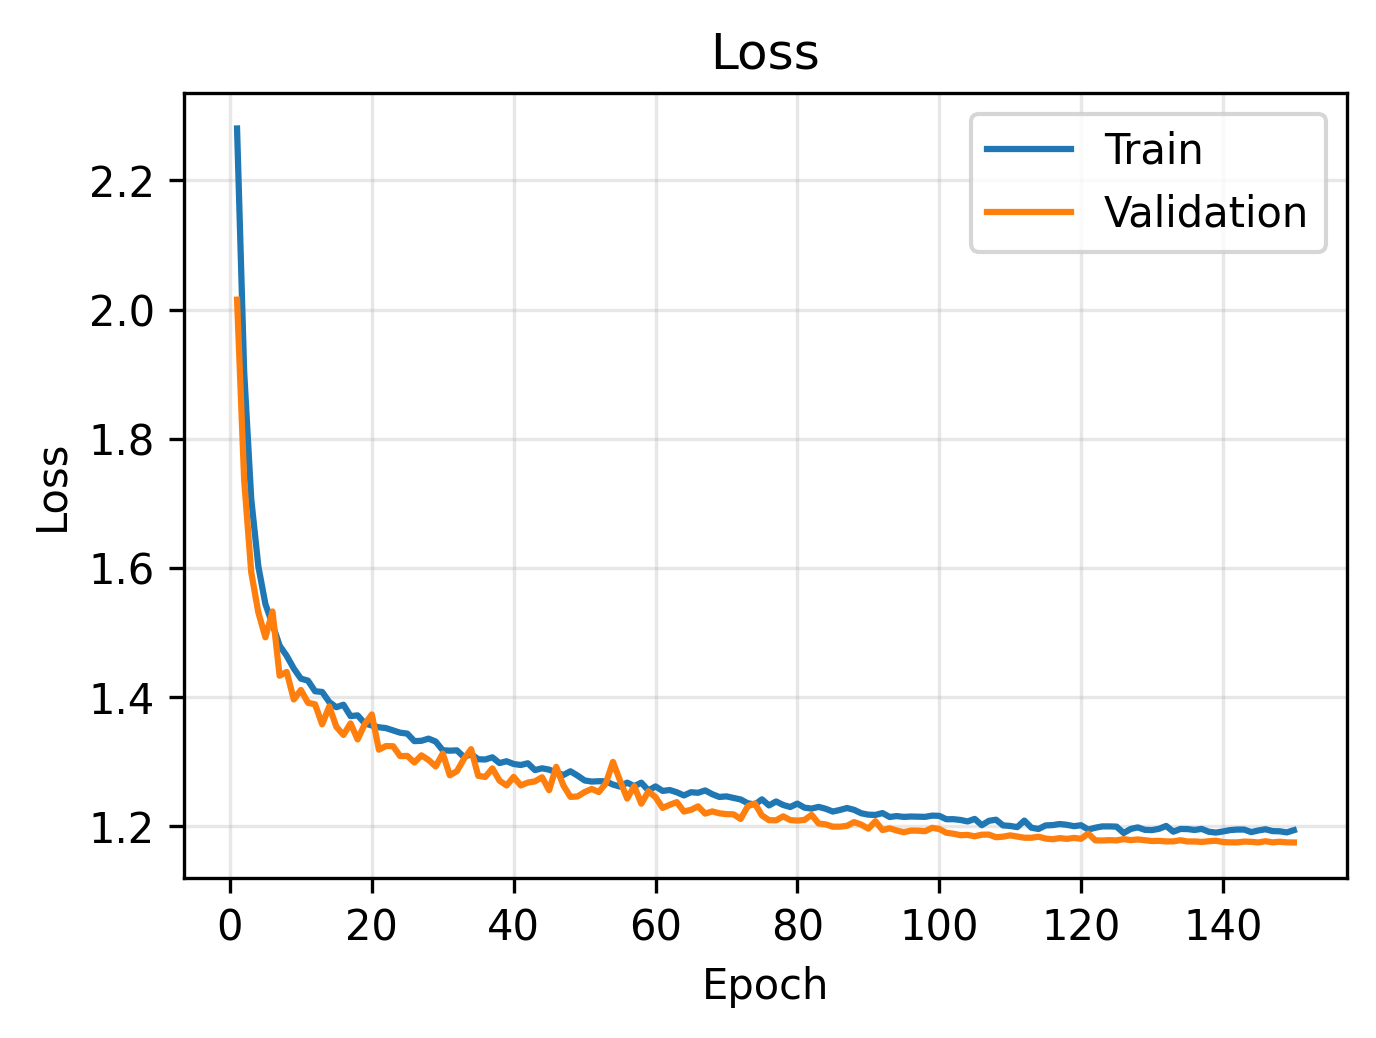

curve_miou


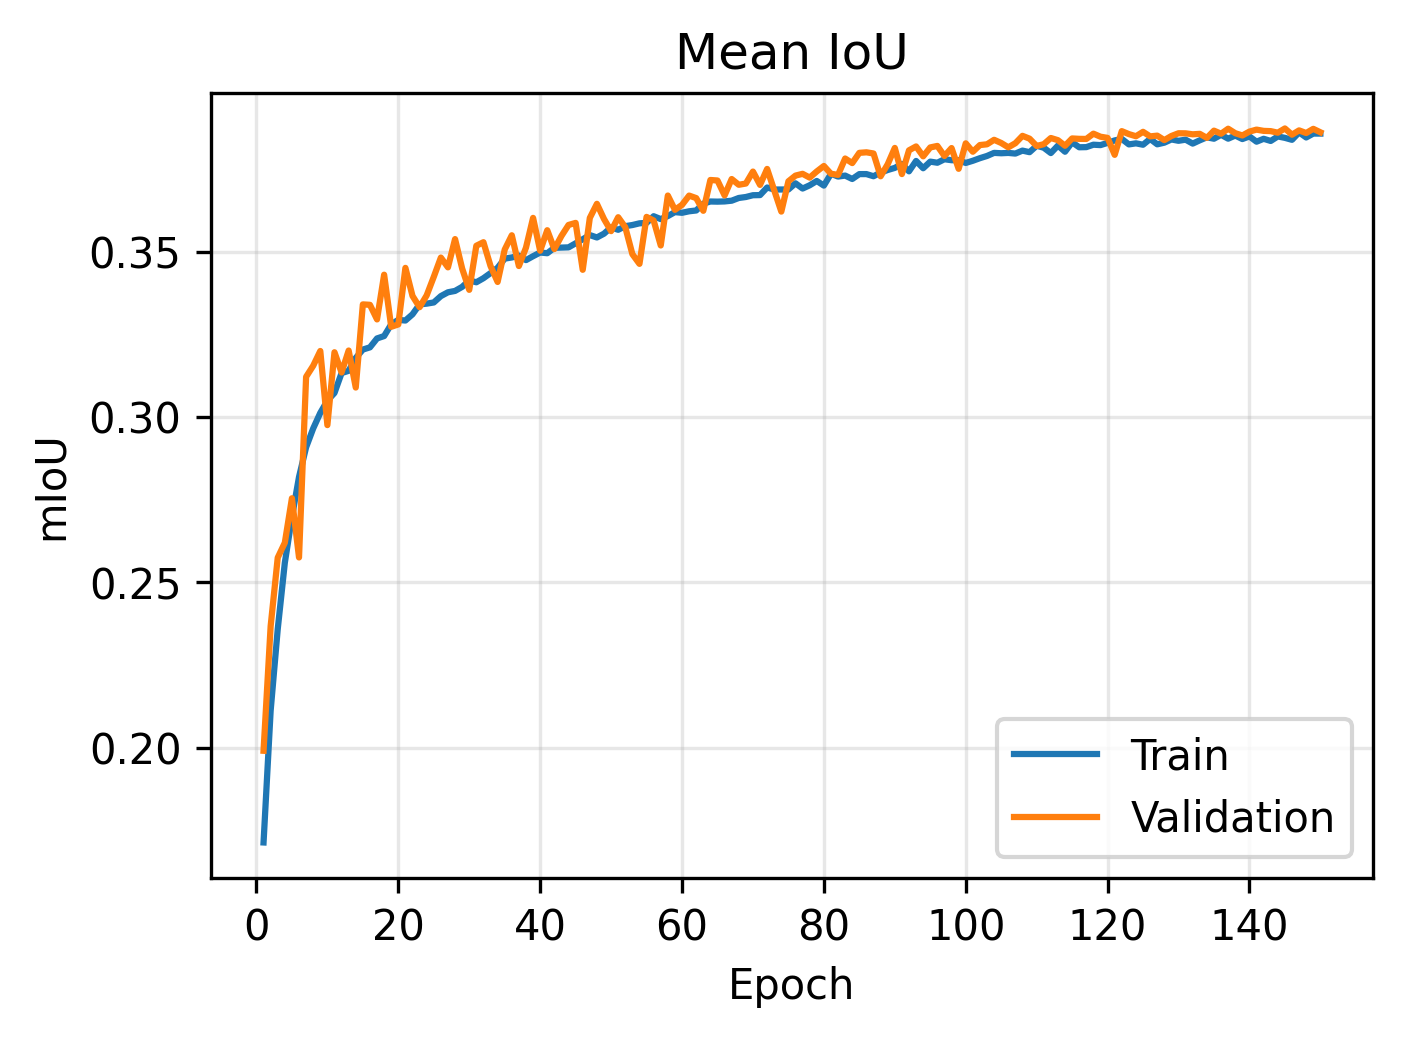

curve_macro_f1


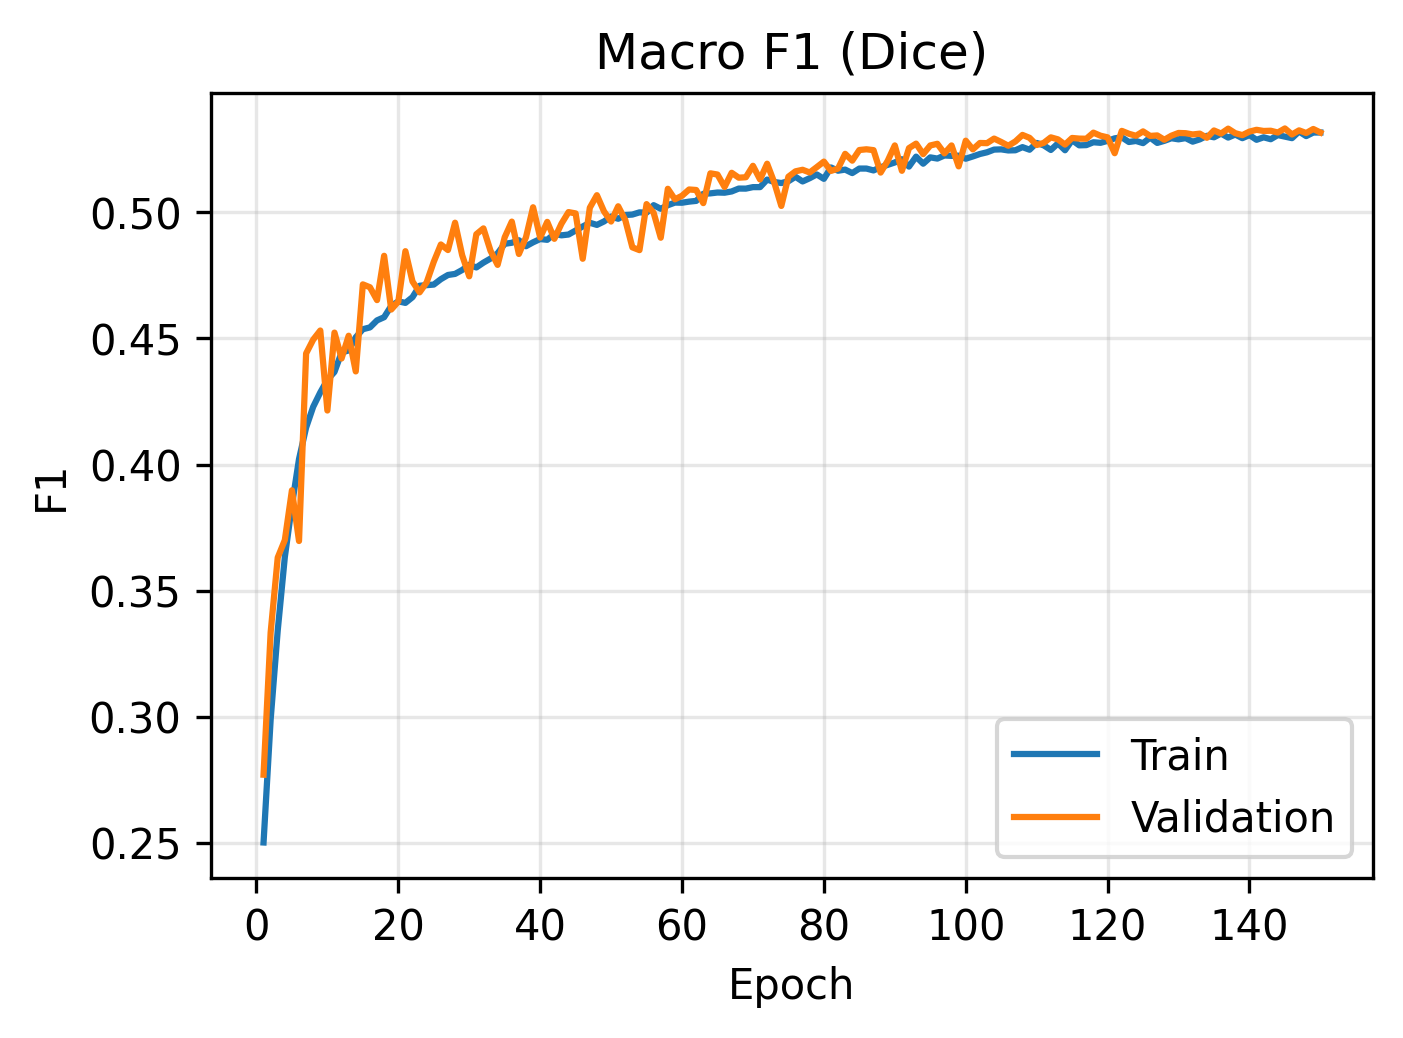

curve_lr


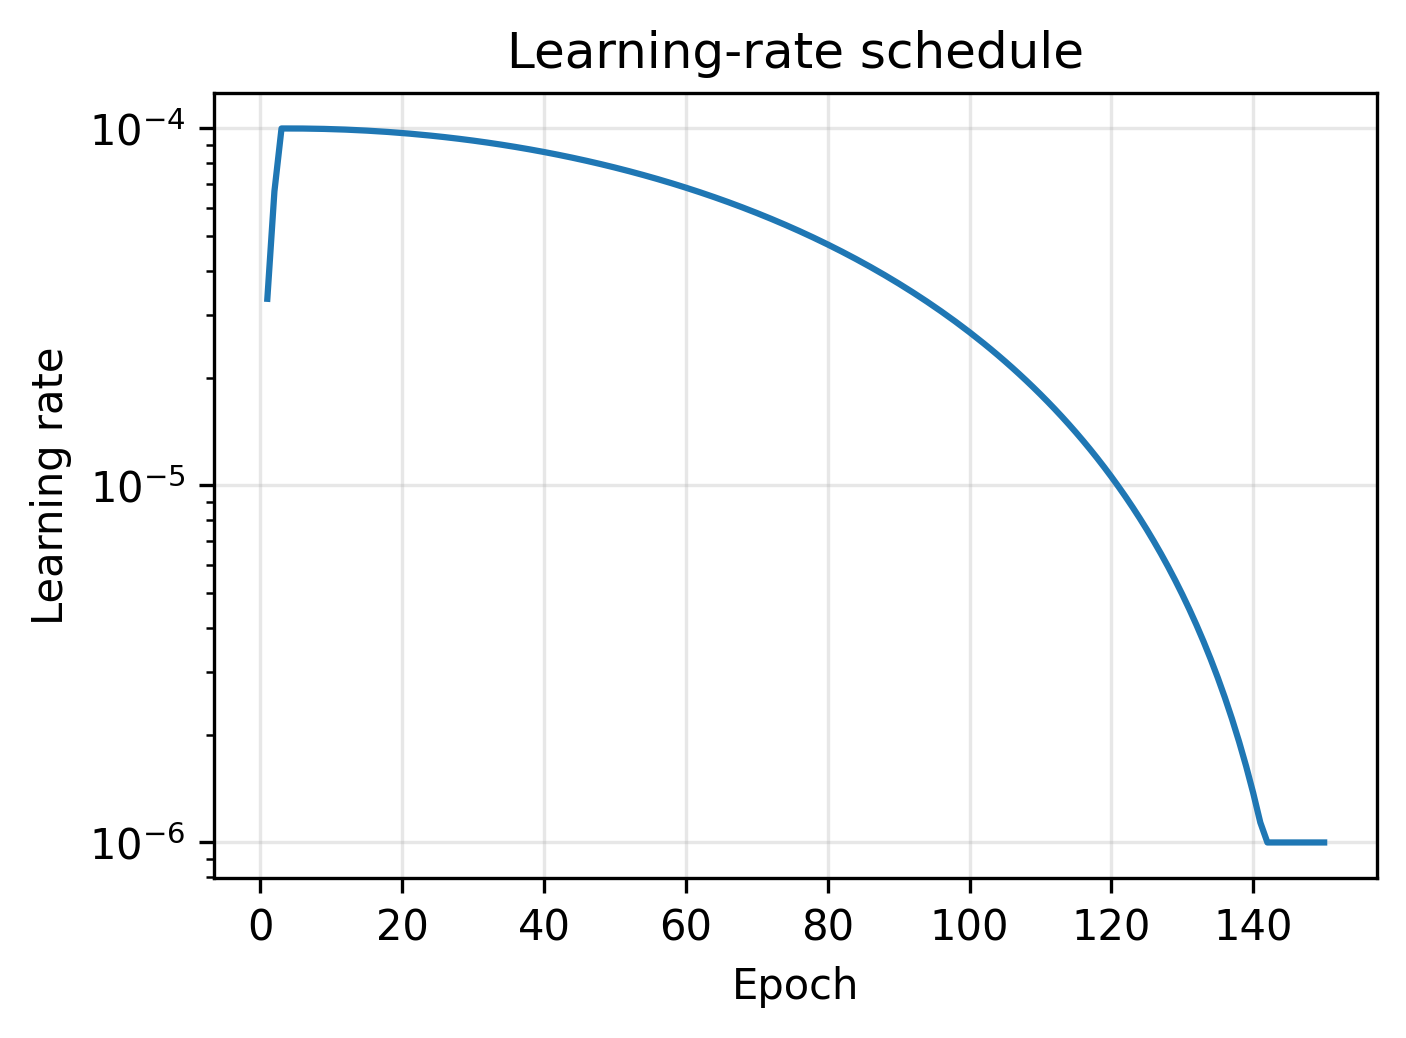

test_confusion_normalized


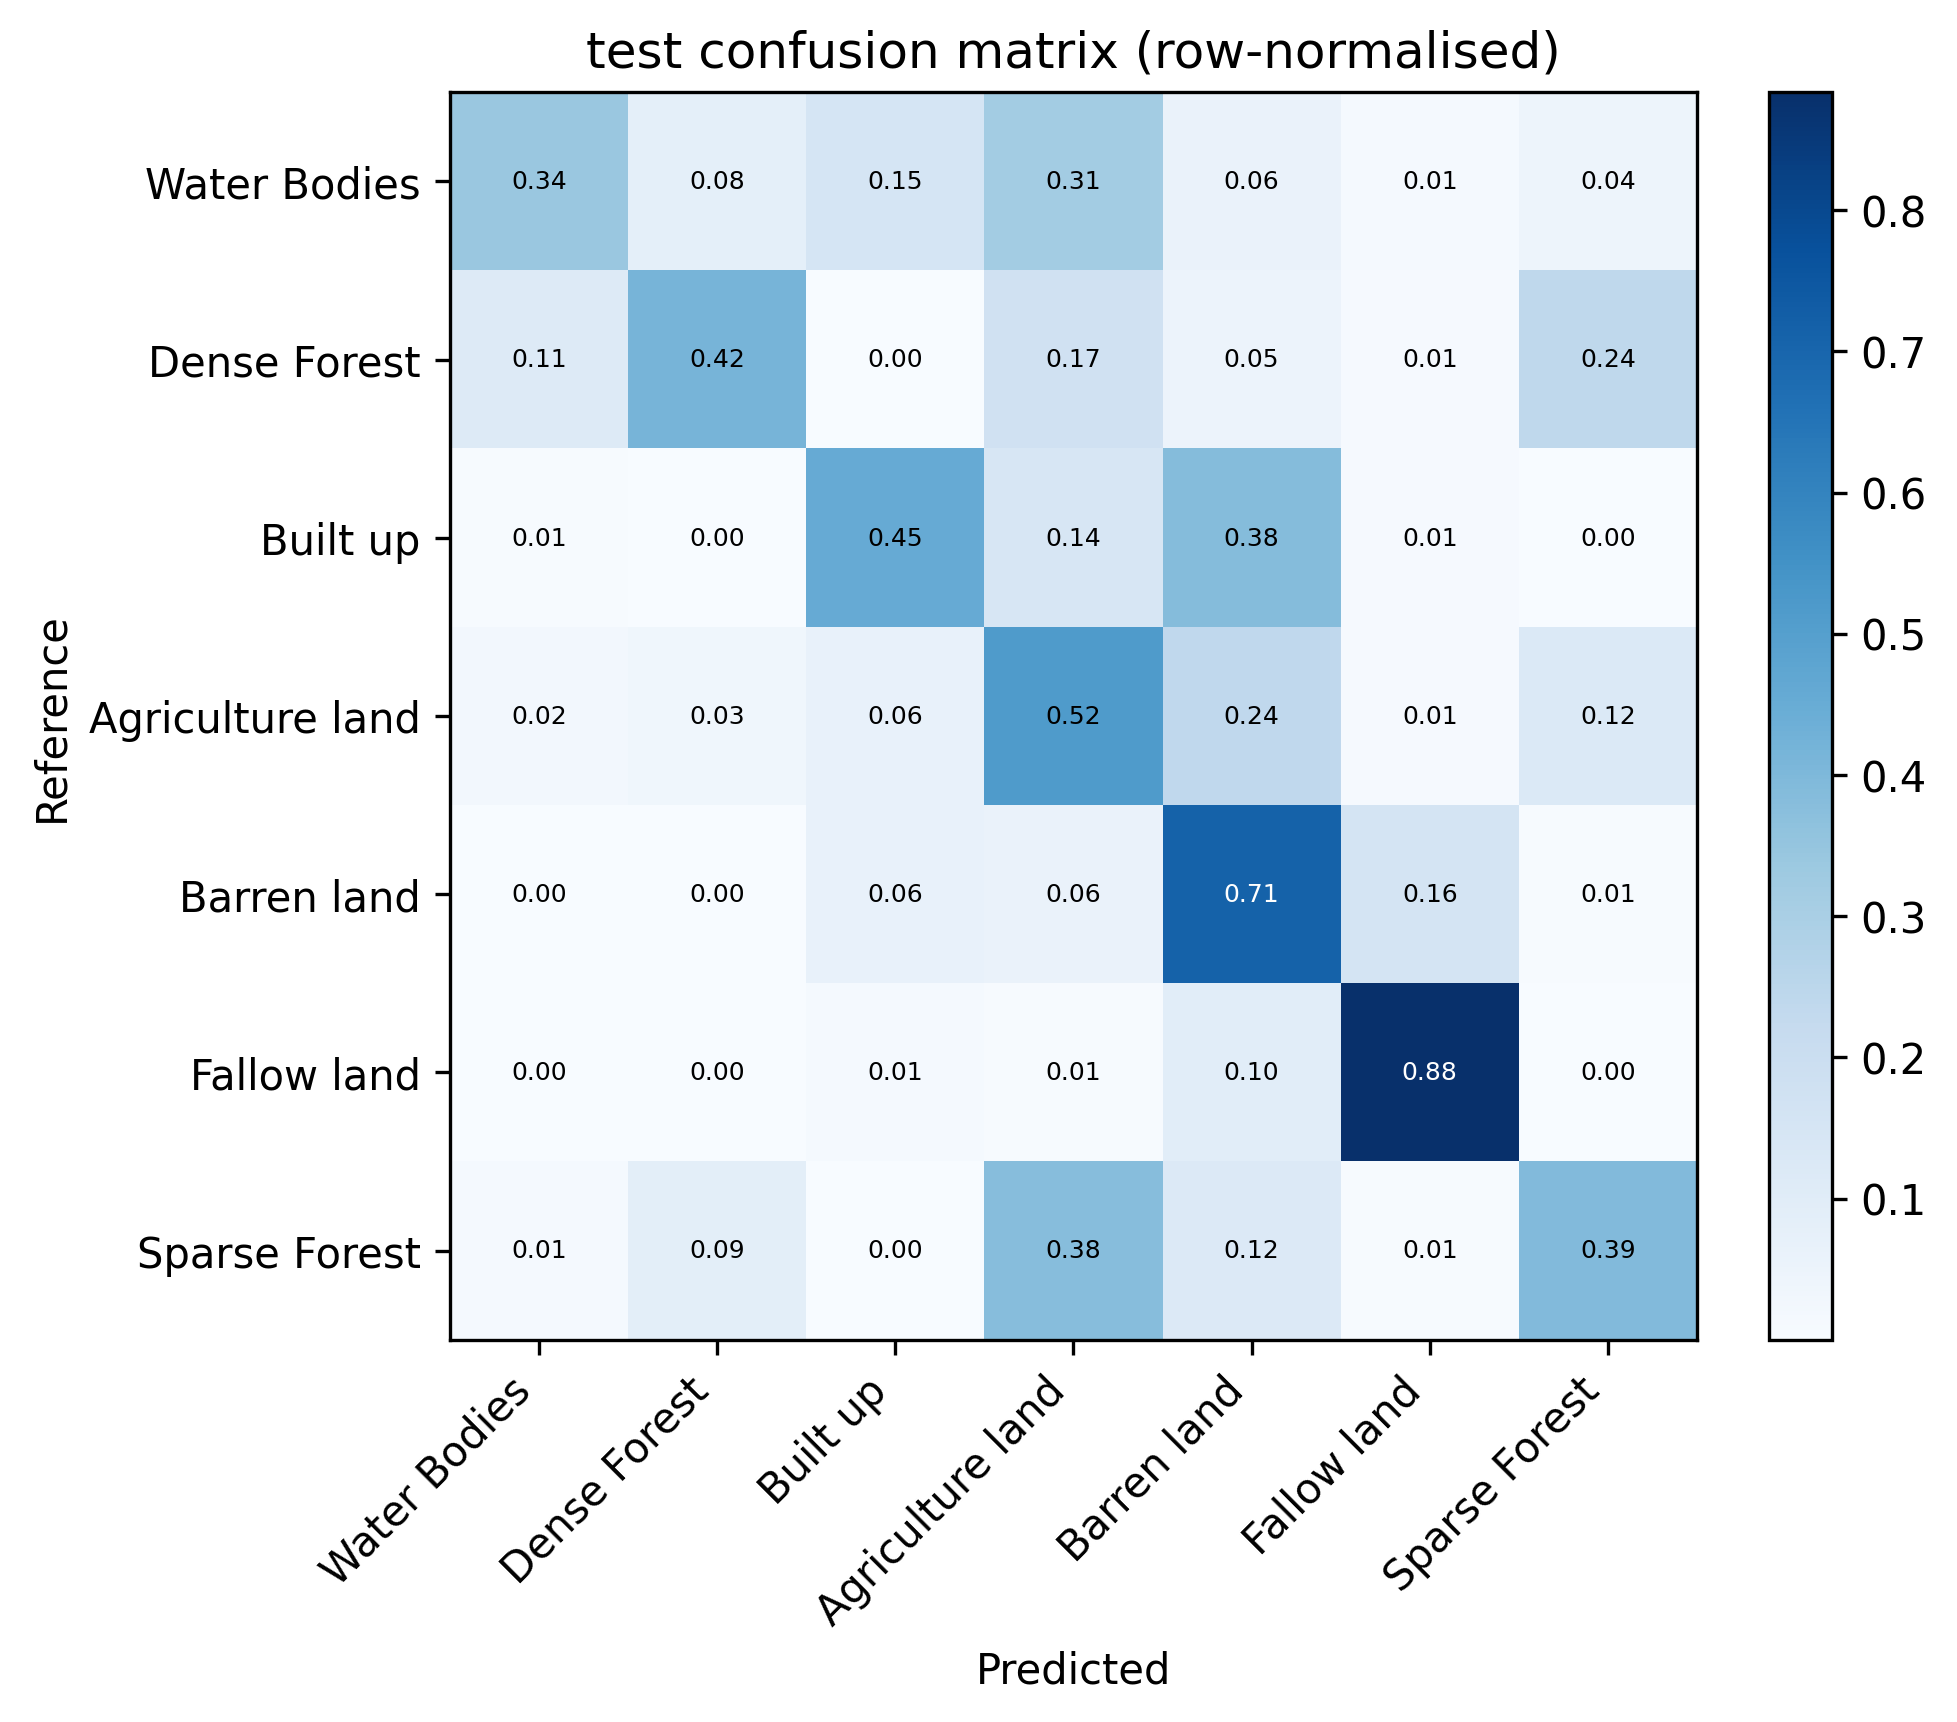

test_per_class_iou


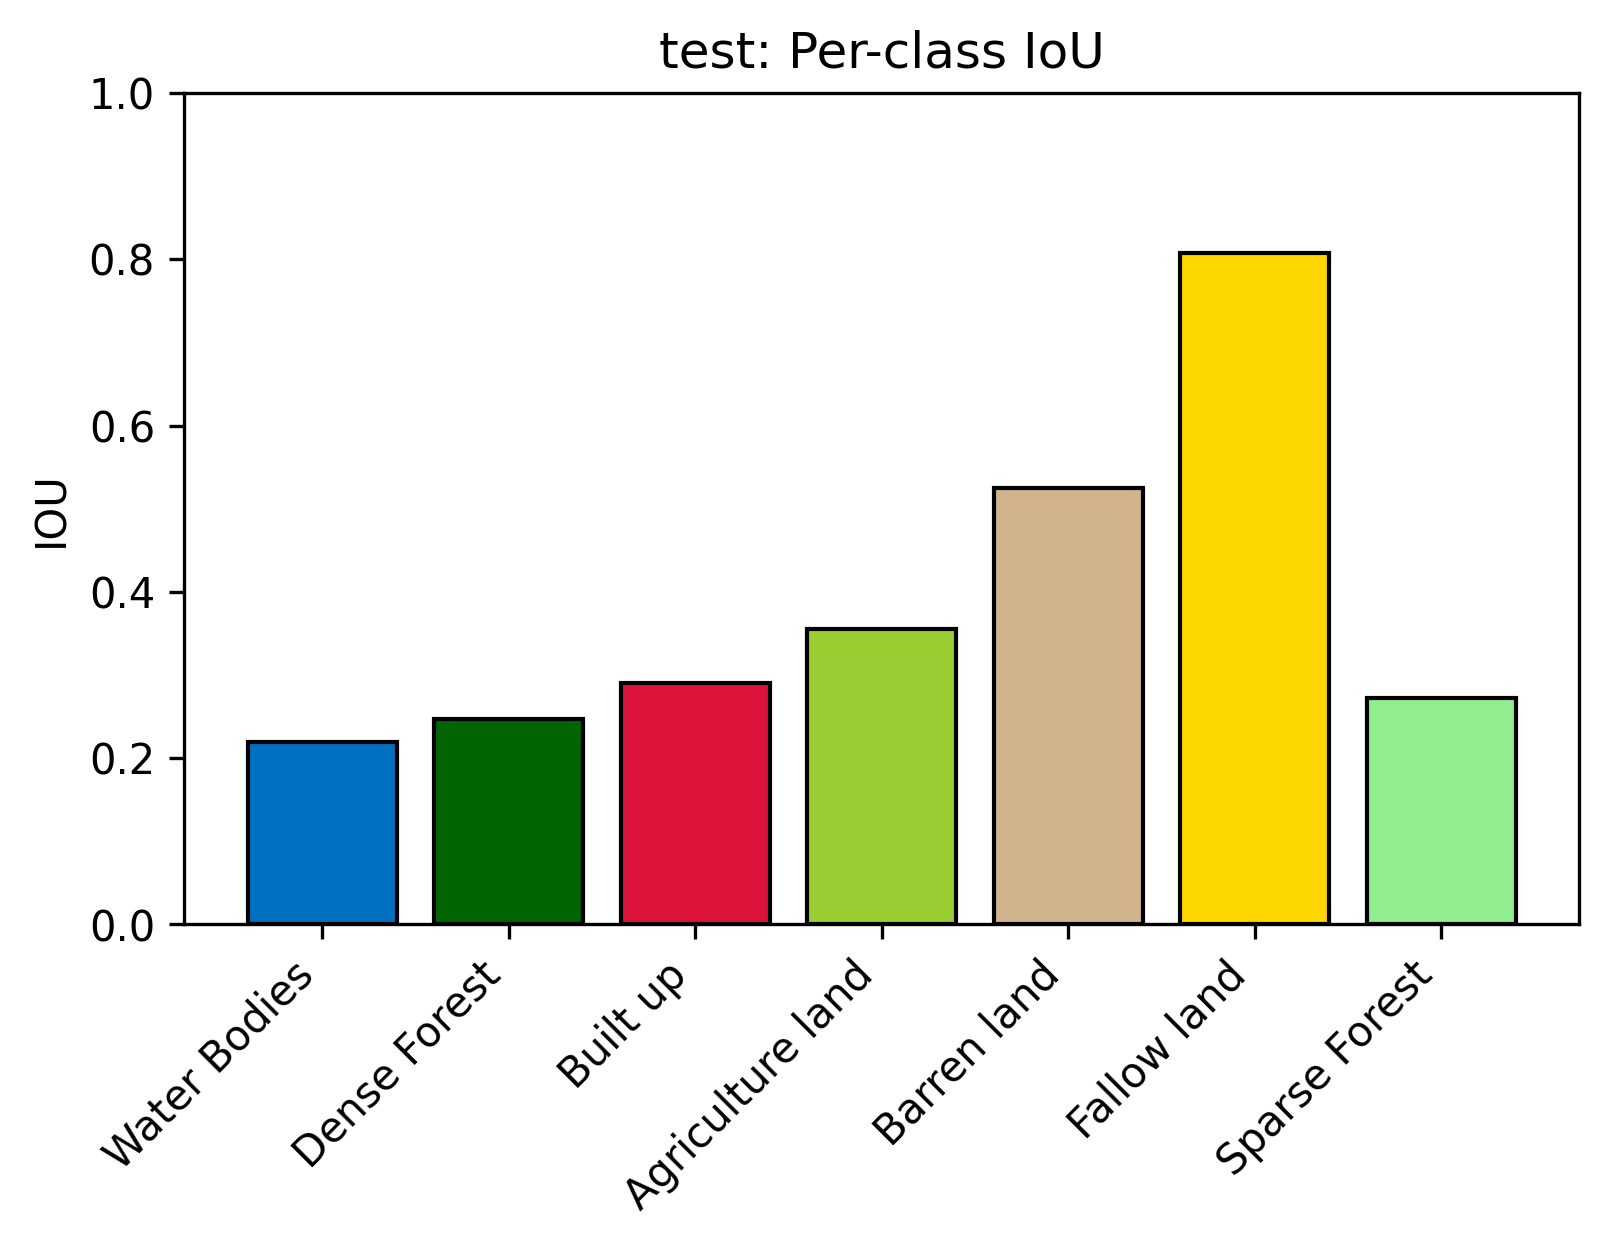

test_per_class_precision_recall


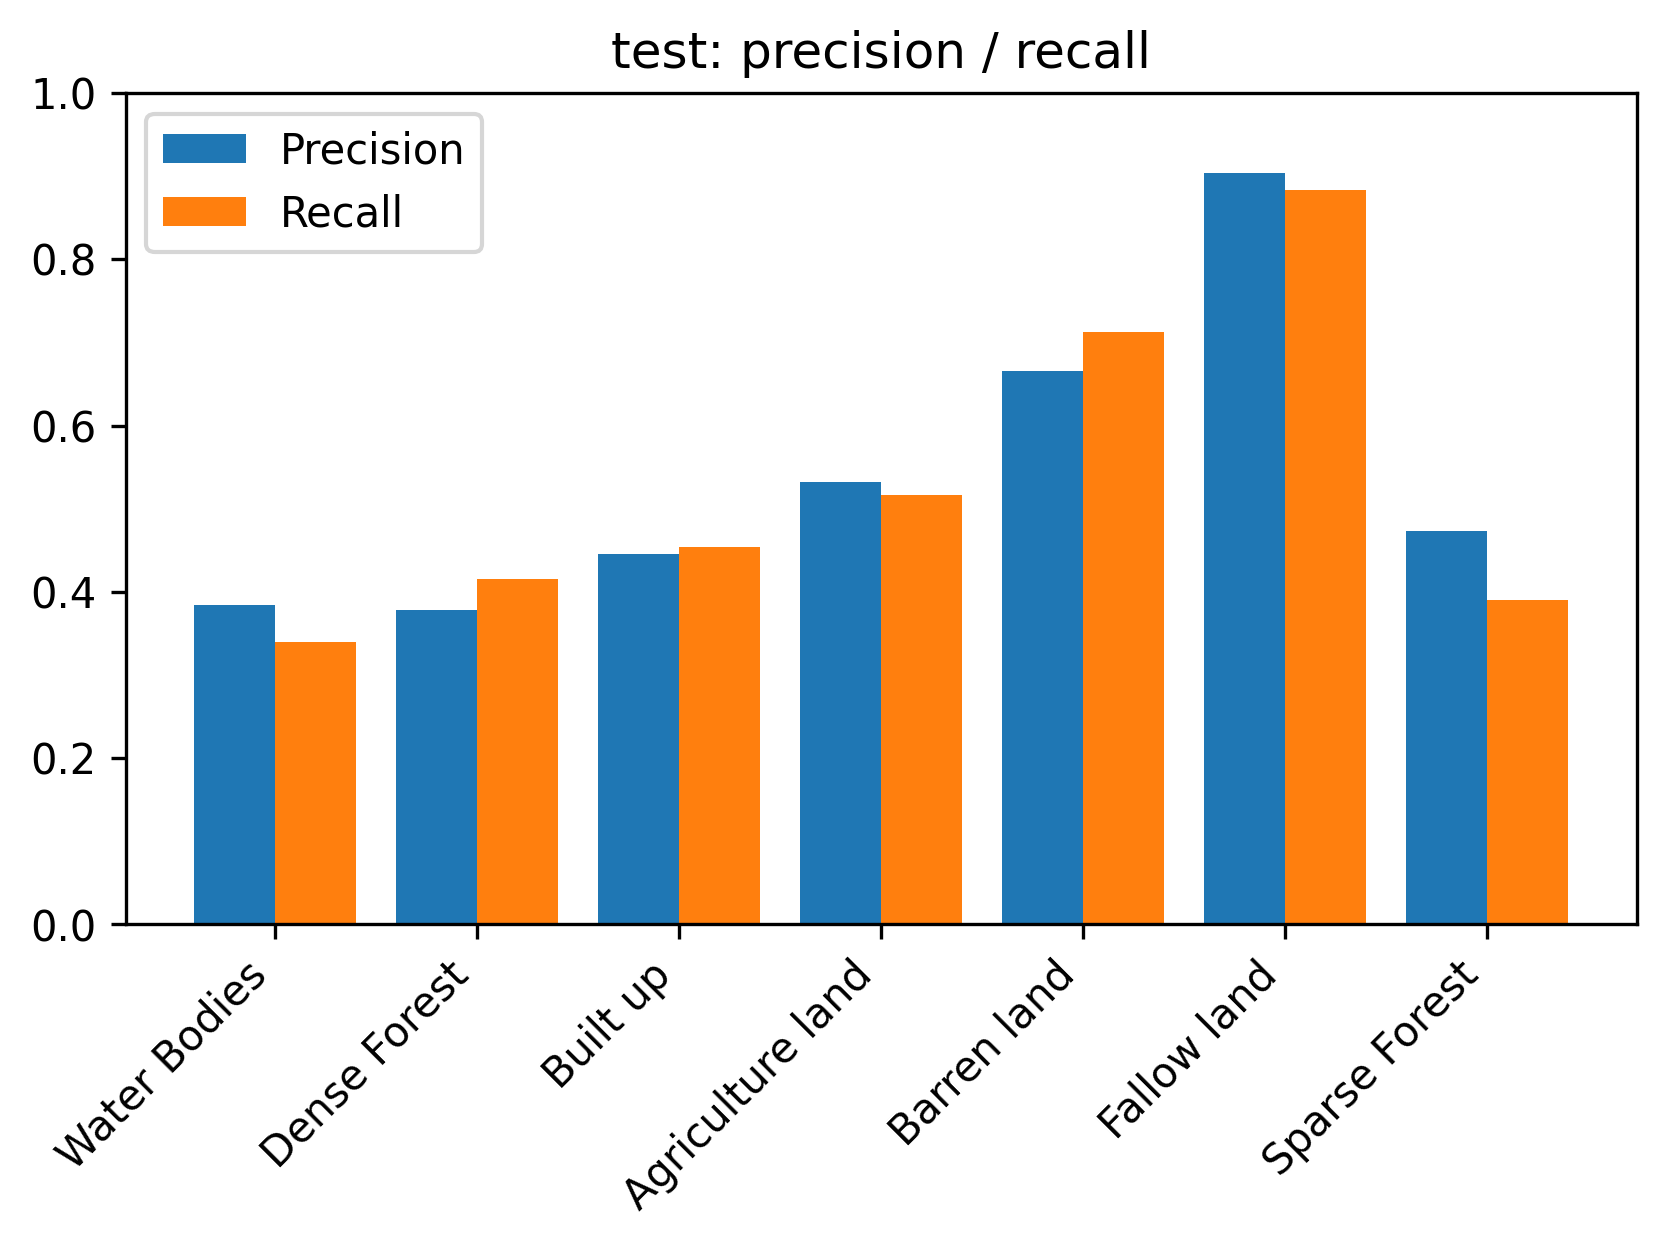

['curve_loss.eps', 'curve_loss.png', 'curve_lr.eps', 'curve_lr.png', 'curve_macro_f1.eps', 'curve_macro_f1.png', 'curve_miou.eps', 'curve_miou.png', 'test_confusion_normalized.eps', 'test_confusion_normalized.png', 'test_confusion_raw.eps', 'test_confusion_raw.png', 'test_per_class_f1_dice.eps', 'test_per_class_f1_dice.png', 'test_per_class_iou.eps', 'test_per_class_iou.png', 'test_per_class_precision_recall.eps', 'test_per_class_precision_recall.png', 'validation_confusion_normalized.eps', 'validation_confusion_normalized.png', 'validation_confusion_raw.eps', 'validation_confusion_raw.png', 'validation_per_class_f1_dice.eps', 'validation_per_class_f1_dice.png', 'validation_per_class_iou.eps', 'validation_per_class_iou.png', 'validation_per_class_precision_recall.eps', 'validation_per_class_precision_recall.png']


In [30]:
from IPython.display import Image as IPImage, display
fd = f"{c_main['exp_dir']}/figures"
for f in ["curve_loss", "curve_miou", "curve_macro_f1", "curve_lr", "test_confusion_normalized", "test_per_class_iou", "test_per_class_precision_recall"]:
    if os.path.exists(f"{fd}/{f}.png"): print(f); display(IPImage(f"{fd}/{f}.png", width=520))
print(sorted(os.listdir(fd)))

## 20. Qualitative results: strong / average / failure cases (selected by per-image mIoU rank, not by appearance)
Panels: RGB · reference · prediction · error map (white = correct, red = wrong, grey = ignored) · predictive entropy.

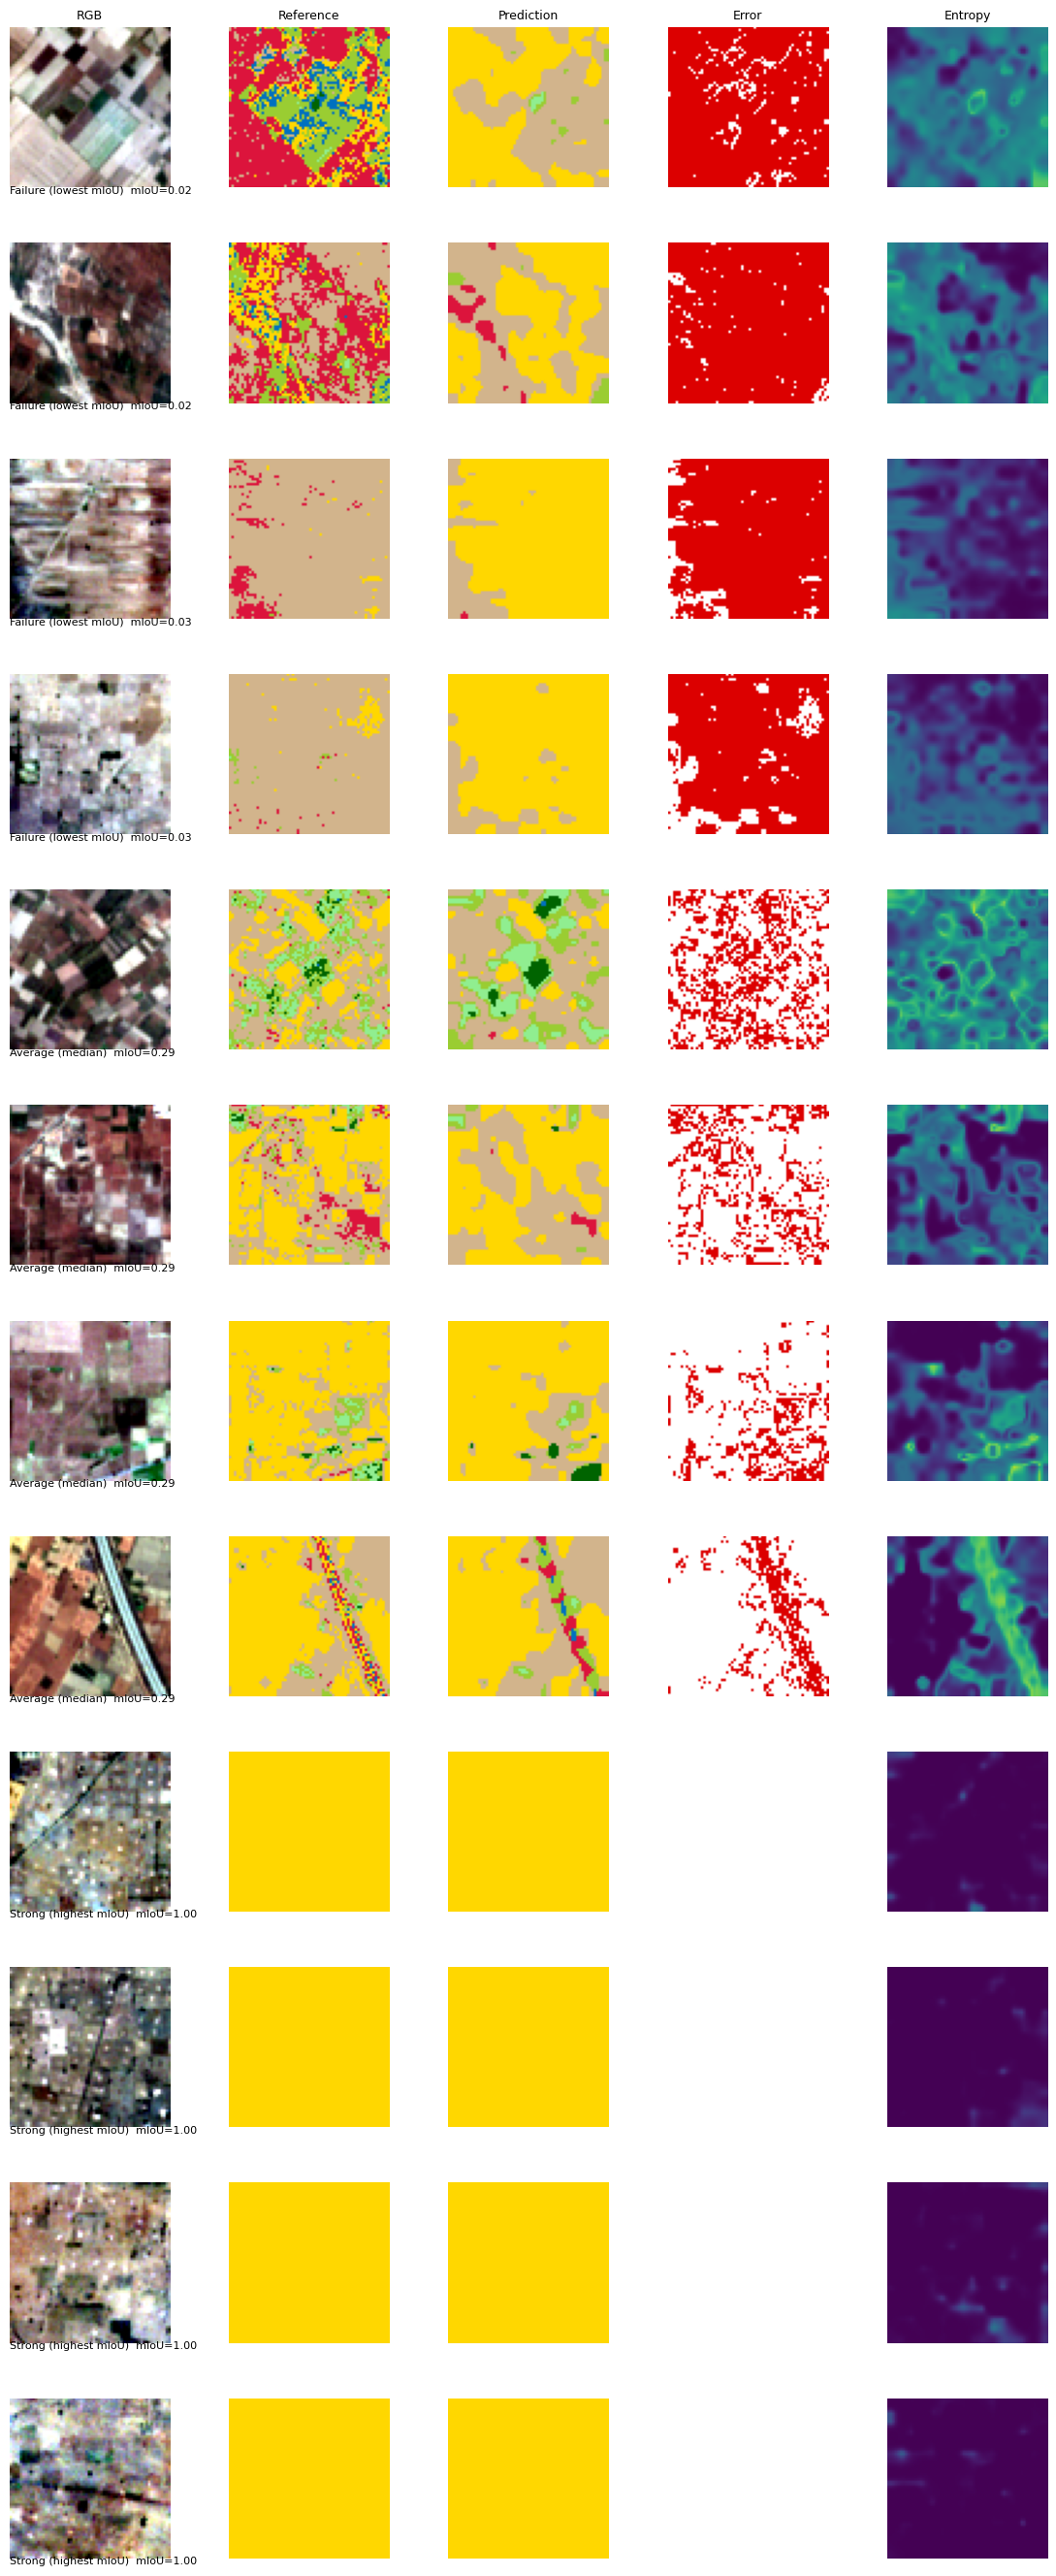

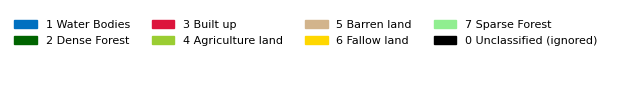

In [31]:
sys.path.insert(0, CODE); import importlib, common as Cm; importlib.reload(Cm)
import torch, matplotlib.pyplot as plt, torch.nn.functional as F
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
cfg_m = json.load(open(f"{c_main['exp_dir']}/config.json")); model, _ = Cm.build_model(cfg_m, pretrained=False)
ck = torch.load(f"{c_main['exp_dir']}/checkpoints/best.pt", map_location=dev, weights_only=False); model.load_state_dict(ck["model"]); model = model.to(dev).eval()
pi = pd.read_csv(f"{c_main['exp_dir']}/test_per_image_results.csv").dropna(subset=["iou"]).sort_values("iou").reset_index(drop=True)
pick = {"Failure (lowest mIoU)": pi.iloc[:4], "Average (median)": pi.iloc[len(pi)//2-2:len(pi)//2+2], "Strong (highest mIoU)": pi.iloc[-4:]}
ds = Cm.LULCDataset(f"{ROOT}/splits/test_manifest.csv", cfg_m, train=False); idmap = {v: i for i, v in enumerate(ds.df.id)}
fig, axs = plt.subplots(12, 5, figsize=(11, 27)); row = 0
for title, sub in pick.items():
    for _, r in sub.iterrows():
        x, y, _ = ds[idmap[r.image_id]]
        with torch.no_grad(): lg = model(x.unsqueeze(0).to(dev)).float()
        p = lg.softmax(1)[0]; pred = p.argmax(0).cpu().numpy(); ent = (-(p * (p + 1e-8).log()).sum(0) / np.log(7)).cpu().numpy(); gt = y.numpy()
        rgb = np.clip(x.numpy().transpose(1, 2, 0) * ds.std + ds.mean, 0, 1)
        err = np.full(gt.shape + (3,), 200, np.uint8); v = gt != 255; err[v & (pred == gt)] = 255; err[v & (pred != gt)] = (220, 0, 0)
        for j, (im, t) in enumerate([(rgb, "RGB"), (Cm.colorize(gt), "Reference"), (Cm.colorize(pred), "Prediction"), (err, "Error"), (ent, "Entropy")]):
            axs[row, j].imshow(im, vmin=0, vmax=1) if j == 4 else axs[row, j].imshow(im); axs[row, j].axis("off")
            if row == 0: axs[row, j].set_title(t, fontsize=9)
        axs[row, 0].text(0, -0.05, f"{title}  mIoU={r.iou:.2f}", transform=axs[row, 0].transAxes, fontsize=8, va="bottom"); row += 1
plt.tight_layout(); fig.savefig(f"{fd}/qualitative_examples.png", dpi=200, bbox_inches="tight"); fig.savefig(f"{fd}/qualitative_examples.eps", bbox_inches="tight"); plt.show()
from matplotlib.patches import Patch
fig2, ax2 = plt.subplots(figsize=(7, 1)); ax2.axis("off"); ax2.legend(handles=[Patch(color=np.array(Cm.CLASS_COLORS_SRC[i]) / 255, label=f"{i} {Cm.CLASS_NAMES_SRC[i]}") for i in range(1, 8)] + [Patch(color="black", label="0 Unclassified (ignored)")], ncol=4, frameon=False, fontsize=8)
fig2.savefig(f"{fd}/legend.png", dpi=300, bbox_inches="tight"); fig2.savefig(f"{fd}/legend.eps", bbox_inches="tight"); plt.show()
del model; torch.cuda.empty_cache()

## 21. Run another architecture / ablation (modest runner — no automatic grids)
Edit `QUEUE` and run. Keep split, preprocessing, augmentation, loss, optimiser and early-stopping identical for the first controlled comparison; only `model`/`encoder` change. Each entry gets a unique directory.

In [32]:
QUEUE = [   # example controlled comparison (A-D of the plan); uncomment what you want to run - each is a full 150-epoch budget
    # dict(model="unetplusplus", encoder="resnet34"),
    # dict(model="deeplabv3plus", encoder="resnet50"),
    # dict(model="segformer", encoder="mit-b0", segformer_checkpoint="nvidia/mit-b0", lr=6e-5, batch_size=32),
]
for ov in QUEUE:
    c = new_experiment(ov)
    if launch(c, "train") == 0: check_dual_gpu(c)
    # run TEST only after you have chosen the final configuration:  launch(c, "test")

## 22. Experiment summary & model-comparison table (built only from completed experiment files)
First, *optionally* import the finished U-Net baseline so it is listed next to RS3Mamba.

In [33]:
# OPTIONAL - bring the finished U-Net experiment into this notebook so it appears in the summary table / head-to-head below.
# Attach the U-Net notebook output and point to its experiment folder (checkpoints are NOT copied; only csv/json/figures).
UNET_EXP_DIR = None   # e.g. "/kaggle/input/sen2lulc-unet/lulc_research/experiments/unet_resnet34_seed42_20261008_084721"
if UNET_EXP_DIR:
    dst = f"{ROOT}/experiments/{os.path.basename(UNET_EXP_DIR.rstrip('/'))}"
    if not os.path.exists(dst): shutil.copytree(UNET_EXP_DIR, dst, ignore=shutil.ignore_patterns("checkpoints"))
    print("baseline imported:", dst, "->", sorted(os.listdir(dst))[:12], "...")
else:
    print("UNET_EXP_DIR not set -> summary will list only experiments run in this notebook.")


UNET_EXP_DIR not set -> summary will list only experiments run in this notebook.


In [34]:
rows = []
for d in sorted(glob.glob(f"{ROOT}/experiments/*/")):
    name = os.path.basename(d.rstrip("/"))
    if any(t in name for t in ("_smokecfg", "_ddpsmoke", "_resumetest")): continue
    if not (os.path.exists(f"{d}runtime.json") and os.path.exists(f"{d}validation_metrics.csv")): continue
    rt = json.load(open(f"{d}runtime.json")); cf = json.load(open(f"{d}config.json")); v = pd.read_csv(f"{d}validation_metrics.csv").iloc[0]
    row = dict(experiment=name, model=cf["model"], encoder=cf["encoder"], pretrained=cf["pretrained"], loss=cf["loss"], lr=cf["lr"], scheduler=cf["scheduler"], aug=cf["augmentation"],
               params_M=rt["params_total"] / 1e6, best_epoch=rt["best_epoch"], epochs_run=rt["epochs_run"], val_OA=v.oa, val_mIoU=v.miou, val_macroF1=v.macro_f1, val_kappa=v.kappa,
               train_time_h=rt["train_time_s"] / 3600, peak_mem_MB=rt["peak_mem_mb_max"], GFLOPs_fwd=(rt["forward_flops_per_image"] or np.nan) / 1e9, effective_batch=rt["effective_batch"])
    if os.path.exists(f"{d}test_metrics.csv"):
        t = pd.read_csv(f"{d}test_metrics.csv").iloc[0]
        row.update(test_OA=t.oa, test_mIoU=t.miou, test_macroF1=t.macro_f1, test_kappa=t.kappa, inference_img_per_s=rt.get("inference_throughput_img_per_s"))
    rows.append(row)
summ = pd.DataFrame(rows); summ.to_csv(f"{ROOT}/model_comparisons/experiment_summary.csv", index=False); summ.to_csv(f"{ROOT}/experiments/experiment_summary.csv", index=False)
display(summ.round(4) if len(summ) else "No completed experiments yet.")
if len(summ) > 1:
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.4)); lab = summ.model + "\n" + summ.encoder
    for a, (col, t) in zip(ax, [("val_mIoU", "Validation mIoU"), ("params_M", "Parameters (M)"), ("train_time_h", "Training time (h)"), ("peak_mem_MB", "Peak GPU memory (MB)")]):
        a.bar(lab, summ[col]); a.set_title(t); plt.setp(a.get_xticklabels(), fontsize=7)
    plt.tight_layout(); [fig.savefig(f"{ROOT}/model_comparisons/comparison.{e}", dpi=300, bbox_inches="tight") for e in ("png", "eps")]; plt.show()
print("\nPART 2 COMPLETE. Part 3 (GeoTIFF inference, areas, flood-exposure utilities) follows as pasteable cells.")

,experiment,model,encoder,pretrained,loss,lr,scheduler,aug,params_M,best_epoch,...,val_kappa,train_time_h,peak_mem_MB,GFLOPs_fwd,effective_batch,test_OA,test_mIoU,test_macroF1,test_kappa,inference_img_per_s
0,rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831,rs3mamba,resnet18_vssm_tiny,True,ce_dice,0.0001,warmup_cosine,moderate,43.325,145,...,0.6084,4.1312,2224.9102,1.3812,64,0.7395,0.388,0.5343,0.608,200.0585



PART 2 COMPLETE. Part 3 (GeoTIFF inference, areas, flood-exposure utilities) follows as pasteable cells.


## 23. U-Net vs RS3Mamba — head-to-head on the TEST split (from saved files; no re-inference)

In [35]:
# Head-to-head on the TEST split from the saved per-image / per-class files (no re-inference).
# Per-image mIoU differences are PAIRED (same images), with a bootstrap CI.  Note: mean per-image mIoU != the global mIoU in test_metrics.csv.
def _find(model):
    """newest TEST-evaluated, non-smoke experiment whose config.json says `model`"""
    for d in sorted(glob.glob(f"{ROOT}/experiments/*/"), reverse=True):
        if any(t in d for t in ("_smokecfg", "_ddpsmoke", "_resumetest")) or not os.path.exists(f"{d}test_metrics.csv"): continue
        if json.load(open(f"{d}config.json")).get("model") == model: return d
    return None
dA, dB = _find("unet"), _find("rs3mamba")
if not (dA and dB):
    print("Need a TEST-evaluated U-Net (set UNET_EXP_DIR above) and RS3Mamba run (Section 18).  U-Net:", dA, "| RS3Mamba:", dB)
else:
    nA, nB = "U-Net", "RS3Mamba"
    mA, mB = pd.read_csv(f"{dA}test_metrics.csv").iloc[0], pd.read_csv(f"{dB}test_metrics.csv").iloc[0]
    tab = pd.DataFrame({nA: {k: mA[k] for k in ("oa", "miou", "macro_f1", "kappa")}, nB: {k: mB[k] for k in ("oa", "miou", "macro_f1", "kappa")}}); tab["diff (B-A)"] = tab[nB] - tab[nA]
    display(tab.round(4))
    pcA, pcB = pd.read_csv(f"{dA}test_per_class_metrics.csv"), pd.read_csv(f"{dB}test_per_class_metrics.csv")
    pc = pd.DataFrame({"class": pcA["class_name"], f"IoU {nA}": pcA["iou"], f"IoU {nB}": pcB["iou"]}); pc["diff (B-A)"] = pc[f"IoU {nB}"] - pc[f"IoU {nA}"]; display(pc.round(4))
    pA, pB = pd.read_csv(f"{dA}test_per_image_results.csv"), pd.read_csv(f"{dB}test_per_image_results.csv")
    j = pA[["image_id", "iou"]].merge(pB[["image_id", "iou"]], on="image_id", suffixes=("_A", "_B")).dropna()
    d = (j.iou_B - j.iou_A).to_numpy(); rng = np.random.RandomState(42)
    bs = np.array([d[rng.randint(0, len(d), len(d))].mean() for _ in range(2000)])
    print(f"paired per-image mIoU difference ({nB} - {nA}) over {len(d)} test images: mean {d.mean():+.4f}  95% bootstrap CI [{np.percentile(bs,2.5):+.4f}, {np.percentile(bs,97.5):+.4f}]  "
          f"| {nB} better on {(d>0).mean():.1%}, worse on {(d<0).mean():.1%}")
    rA, rB = json.load(open(f"{dA}runtime.json")), json.load(open(f"{dB}runtime.json"))
    cost = pd.DataFrame({nA: {"params_M": rA["params_total"]/1e6, "GFLOPs_fwd": (rA["forward_flops_per_image"] or np.nan)/1e9, "avg_epoch_s": rA["avg_epoch_time_s"], "peak_mem_MB": rA["peak_mem_mb_max"], "infer_img_per_s": rA.get("inference_throughput_img_per_s")},
                         nB: {"params_M": rB["params_total"]/1e6, "GFLOPs_fwd": (rB["forward_flops_per_image"] or np.nan)/1e9, "avg_epoch_s": rB["avg_epoch_time_s"], "peak_mem_MB": rB["peak_mem_mb_max"], "infer_img_per_s": rB.get("inference_throughput_img_per_s")}})
    display(cost.round(2))
    print("RS3Mamba GFLOPs include an analytic selective-scan term (VMamba convention) - see runtime.json -> flops_detail.")


Need a TEST-evaluated U-Net (set UNET_EXP_DIR above) and RS3Mamba run (Section 18).  U-Net: None | RS3Mamba: /kaggle/working/lulc_research/experiments/rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831/


## 24. Deployment bundle (for Part 3)
Packages the best experiment by **validation** mIoU together with all code (`mamba_scan.py`, `rs3mamba_model.py`, …). Note: using the RS3Mamba checkpoint in Part 3 additionally requires the §3a kernel (or `scan_backend='torch'`).

In [36]:
import os, sys, json, glob, time, shutil, zipfile, datetime, hashlib, platform, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
ROOT = "/kaggle/working/lulc_research"
SMOKE_TAGS = ("_smokecfg", "_ddpsmoke", "_resumetest")

def list_experiments(patterns):
    """All finished experiments (best.pt present), de-duplicated by name (first pattern wins). Selection metric = VALIDATION mIoU."""
    seen, rows = set(), []
    for pat in patterns:
        for ck in sorted(glob.glob(pat, recursive=True)):
            d = os.path.dirname(os.path.dirname(ck)); name = os.path.basename(d)
            if name in seen or any(t in name for t in SMOKE_TAGS): continue
            seen.add(name); r = dict(experiment=name, exp_dir=d, val_mIoU=np.nan, test_mIoU=np.nan)
            if os.path.exists(f"{d}/validation_metrics.csv"): r["val_mIoU"] = float(pd.read_csv(f"{d}/validation_metrics.csv").iloc[0].miou)
            if os.path.exists(f"{d}/test_metrics.csv"): r["test_mIoU"] = float(pd.read_csv(f"{d}/test_metrics.csv").iloc[0].miou)
            rows.append(r)
    return pd.DataFrame(rows)

if os.path.isdir(f"{ROOT}/experiments") and glob.glob(f"{ROOT}/experiments/*/checkpoints/best.pt"):
    ex = list_experiments([f"{ROOT}/experiments/*/checkpoints/best.pt"]).sort_values("val_mIoU", ascending=False)
    print(ex.drop(columns="exp_dir").to_string()); best = ex.iloc[0]; print("\nBEST by validation mIoU:", best.experiment)
    B = "/kaggle/working/lulc_deploy/lulc_research"; shutil.rmtree("/kaggle/working/lulc_deploy", ignore_errors=True)
    for sub in ("code", "preprocessing", "dataset_analysis"):
        os.makedirs(f"{B}/{sub}", exist_ok=True)
    for f in glob.glob(f"{ROOT}/code/*.py"): shutil.copy(f, f"{B}/code/")
    for f in glob.glob(f"{ROOT}/preprocessing/*.json"): shutil.copy(f, f"{B}/preprocessing/")
    for f in ("dataset_summary.json", "class_stats.json"):
        if os.path.exists(f"{ROOT}/dataset_analysis/{f}"): shutil.copy(f"{ROOT}/dataset_analysis/{f}", f"{B}/dataset_analysis/")
    dst = f"{B}/experiments/{best.experiment}"; os.makedirs(f"{dst}/checkpoints", exist_ok=True)
    shutil.copy(f"{best.exp_dir}/checkpoints/best.pt", f"{dst}/checkpoints/best.pt")
    for f in glob.glob(f"{best.exp_dir}/*.csv") + glob.glob(f"{best.exp_dir}/*.json"): shutil.copy(f, dst)
    shutil.copytree(f"{best.exp_dir}/figures", f"{dst}/figures", dirs_exist_ok=True)
    zp = "/kaggle/working/lulc_deploy_bundle.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for dp, _, fs in os.walk("/kaggle/working/lulc_deploy"):
            for f in fs: z.write(os.path.join(dp, f), os.path.relpath(os.path.join(dp, f), "/kaggle/working/lulc_deploy"))
    print(f"\nBundle written: {zp} ({os.path.getsize(zp)/2**20:.0f} MB)\nDownload it from the Output panel, then: Datasets > New Dataset > upload it (e.g. name 'lulc-deploy-bundle').")
else:
    print("No training outputs in this session -> skipping (normal for a NEW Part-3 notebook).")

                                                     experiment  val_mIoU  test_mIoU
0  rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831  0.387762   0.388017

BEST by validation mIoU: rs3mamba_resnet18_vssm_tiny_seed42_practical_20261028_015831

Bundle written: /kaggle/working/lulc_deploy_bundle.zip (466 MB)
Download it from the Output panel, then: Datasets > New Dataset > upload it (e.g. name 'lulc-deploy-bundle').
